# Natuurherstel, nieuwe beschermde gebieden en monitoring op de Noordzee

*Alternatieve versie, gebaseerd op de vraag van Haskoning en Stichting Noordzee, met BeaconIHM, BeaconWOD en open externe bronnen*

# 1. Overzicht en doelstelling

## De vragen

Dit notebook beantwoordt drie vragen over het Nederlandse deel van de Noordzee:

1. **Natuurherstel.** Welke gebieden zijn geschikt voor natuurherstelprojecten, ecologisch gezien en met medegebruik van de Noordzee? De aandacht gaat uit naar biogene riffen: riffen van de platte oester, de zandkokerworm en de paardenmossel.
2. **Nieuwe beschermde gebieden (MPA's).** Wat zijn ecologisch gezien logische locaties voor nieuwe mariene beschermde gebieden?
3. **Monitoring.** Welke monitoringsactiviteiten in het IHM overlappen in plaats en in ecologie?

## Verschil met de eerste versie

De eerste versie van dit notebook ging alleen over de eerste vraag. Deze versie voegt toe:

- een **MPA-analyse**: waar liggen ecologisch waardevolle gebieden die nu niet beschermd zijn, en welke habitattypen zijn nog te weinig beschermd?
- een **monitoringanalyse**: welke programma's meten dezelfde plekken, dezelfde jaren en dezelfde habitats, en waar zijn hiaten?
- **medegebruik** als apart onderdeel: per kansrijk herstelgebied is te zien of het in een beschermd gebied, een windpark, een defensiegebied, een scheepvaartzone of in open water ligt.
- **milieuomstandigheden** uit BeaconWOD (World Ocean Database) en de CTD-metingen van Rijkswaterstaat: zuurstof, zoutgehalte en temperatuur van het bodemwater.
- een **koppeling** tussen de drie vragen: waar vallen herstelgebieden, MPA-kandidaten en monitoring samen?

De eerdere vraag blijft onderdeel: een gebied met weinig natuurwaarde is niet automatisch een goede plek voor herstel. Het notebook zoekt eerst een verklaring voor de lage waarde en onderscheidt **herstel** van het **maken van nieuw habitat**.

## Wat is bijgewerkt (30 oktober 2026)

BeaconIHM bevat meer bronnen dan de vorige versie van dit notebook gebruikte. Deze update voegt de bronnen toe die bij de drie vragen passen:

- **Windenergie.** Drie tabellen van Rijkswaterstaat vullen de EMODnet-windlagen aan: de aangewezen windenergiegebieden, de vergunde posities van turbines en de vrije ruimte voor medegebruik in windparken (sectie 6.4 en 6.5.3). De indeling van de cellen verandert niet. Wel is nu zichtbaar waar binnen een windpark ruimte is voor natuur.
- **Monitoring.** Zestien tabellen komen bij de monitoringanalyse, onder meer Aquadesk (bodemfauna en fytoplankton), de schelpdiersurvey `ihm_wmr`, negen kustprojecten, de Oceana-expeditie van 2016 en de waarnemingen van de noordkromp (sectie 6.7).
- **Controle.** Sommige tabellen blijken kopieën of bundelingen van tabellen die het notebook al gebruikte. Sectie 6.7 en sectie 8.10 tonen welke. Het aandeel cellen zonder biotische monitoring daalt daardoor maar licht, van 35% naar 32%.
- **Niet gebruikt.** Tabellen die een kopie zijn, geen coördinaten hebben of niet bij de vragen passen, staan in sectie 2.1.

## Aanpak in het kort

Het notebook legt alle lagen op een raster van 0,05 graden (ongeveer 3,5 bij 5,5 kilometer) en beperkt de analyse tot de Nederlandse exclusieve economische zone (EEZ). Per cel bepaalt het notebook:

- de **fysieke randvoorwaarden**: diepte, bodemtype, zuurstof;
- het **ecologisch potentieel** uit modelkaarten en het **bewijs van aanwezigheid** uit waarnemingen;
- de **drukfactoren en regimes**: visserij, scheepvaart, windparken, defensie, winning, bescherming;
- de **monitoring**: welke programma's meten er, in welke jaren.

Daarna volgen drie analyses (herstel, MPA, monitoring) en een koppeling.

## Grenzen van de analyse

- De uitkomst is een **eerste ruimtelijke selectie**. Het is geen besluit en geen vergunningstoets.
- De modelkaarten tonen waar een soort kan leven. Ze tonen niet of herstel lukt.
- De gewichten en grenswaarden zijn **keuzes van de analist**. Sectie 8 toont hun invloed.
- Een waarneming bewijst niet dat daar ooit een rif lag.
- Het notebook toont geen oorzaak-gevolgrelaties.
- Het notebook beoordeelt het **ecologisch** perspectief. Sociaal-economische belangen (visserij, scheepvaart, energie) komen alleen voor als gebruikslaag.

# 2. Databronnen en gebruikte data

## 2.1 Bronnen uit de data lake

Alle bronnen komen van drie Beacon-servers. De tabelnamen, kolomnamen en eenheden zijn met de MCP-tools `list_tables`, `describe_table` en `run_sql` gecontroleerd. Het notebook haalt alleen samengevatte gegevens per rastercel op.

| Server | Bron (tabel) | Wat bevat de bron? | Waarom nodig? | Periode |
|---|---|---|---|---|
| BeaconIHM | `prj_mons55_habitat_prediction` | Modelkans (0 tot 1) dat een soort voorkomt. Twee modellen per soort: platte oester, zandkokerworm, paardenmossel, tubeworm (*Lanice conchilega*). | Ecologisch potentieel voor herstel en voor bescherming. | Modelkaart |
| BeaconIHM | `prj_noordkromp_arctica_prediction` | Modelkans voor de noordkromp (*Arctica islandica*), voor de periodes `pre2004` en `post2003`. | Potentieel en achteruitgang van een langlevende bodemsoort. | Modelkaart |
| BeaconIHM | `prj_mons55_presence`, `prj_mons55_presence_datras` | Waarnemingen van aanwezigheid (1) en afwezigheid (0) van dezelfde soorten. | Huidige en historische aanwezigheid. | 1902 tot 2018 |
| BeaconIHM | `mon_morphology_bathymetry_ncp_2019` | Dieptemodel Nederlands Continentaal Plat. | Diepte. | 2019 |
| BeaconIHM | `prj_nzb_depth` | Tweede dieptebron. | Controle van de diepte. | Onbekend |
| BeaconIHM | `mon_chemistry_grain_size_sediment` | Korrelgrootte van de zeebodem bij MWTL-stations. | Controle van het bodemtype. | 1988 tot 2018 |
| BeaconIHM | `prj_itaw_harbour_porpoise_density_2020` | Gemodelleerde dichtheid van de bruinvis in de zomer. | Waarde voor zeezoogdieren (MPA). | 2020 |
| BeaconIHM | `ihm_rws_ctd` | CTD-profielen van Rijkswaterstaat: temperatuur, zoutgehalte, zuurstof, diepte. | Milieuomstandigheden en monitoringgroep water. | 1995 tot 2019 |
| BeaconIHM | `ihm_wadar` | Waterstanden en andere gegevens op stations. | Monitoringgroep water. | Zie sectie 6.7 |
| BeaconIHM | `mon_benthos_macroinvertebrates_rws`, `mon_benthos_shellfish_wot` | MWTL-benthos en WOT-schelpdiermonitoring. | Natuurwaarde, aanwezigheid van rifbouwers en monitoring. | 1989 tot 2025 |
| BeaconIHM | `prj_dt_fish_yield_2008_2018` | Visserij-opbrengst per cel. Eenheid onbekend. | Controle van de visserijdruk. | 2008 tot 2018 |
| BeaconIHM | 38 monitoringtabellen (benthos, schelpdieren, habitatkartering, vis, vogels, plankton, water, sediment) | Zie de tabel in sectie 6.7. Zestien daarvan zijn toegevoegd in de update van oktober 2026 en staan hieronder apart. | Overlap van monitoring. | Verschilt per tabel |
| BeaconIHM | `use_wind_energy_areas` | Aangewezen windenergiegebieden op de Noordzee: 13 vlakken (Rijkswaterstaat, herzien op 20 juli 2026). | Aanvulling op de windlaag van EMODnet. Toont waar windparken mogen komen. | 2026 |
| BeaconIHM | `use_wind_turbines` | Vergunde posities van 745 turbines en platforms. Status *In gebruik* (739) of *Toekomstig* (6). | Contour van bestaande en geplande windparken. Onafhankelijke toets van EMODnet. | Herzien op 11 juni 2026 |
| BeaconIHM | `use_wind_farm_co_use_space` | Vrije ruimte voor medegebruik in windparken: 252 vlakken, alleen voor Borssele, Hollandse Kust Zuid en Hollandse Kust Noord. | Kansen voor natuur of ander medegebruik binnen windparken. | Gemaakt op 12 februari 2024 |
| BeaconIHM | `aquadesk2026` | Taxonmetingen uit Aquadesk. Het notebook gebruikt compartiment *BS* (bodemfauna) en *OW* (fytoplankton). | Extra benthos- en planktongegevens. Overlapt sterk met de MWTL-tabellen (sectie 8.10). | 1979 tot 2026 |
| BeaconIHM | `ihm_wmr` | Schelpdiersurvey (cluster IHM-KRM) met 951.897 records. | Zelfde survey als `mon_benthos_shellfish_wot`. Het notebook rekent beide tot één groep. | 1993 tot 2023 |
| BeaconIHM | `ihm_vis_monitoring` | Vismonitoring van WMR met 1,8 miljoen records. | Geen enkele cel in de EEZ heeft metingen uit deze tabel. Ze telt daarom niet mee. | 1989 tot 2022 |
| BeaconIHM | `prj_a2m_benthos`, `prj_a2m_fish`, `prj_nv_benthos`, `prj_nv_fish`, `prj_egs_benthos`, `prj_kg2_macrobenthos`, `prj_kg2_fish`, `prj_zm_fish`, `prj_milzon_benthos_1988_1989` | Kustprojecten: zandwinput Maasvlakte 2 (A2M), ecologische zandsuppletie (NV en EGS), Ameland (KG2), Zandmotor (ZM) en de kustzone in 1988 en 1989 (MILZON). | Extra benthos- en visgegevens, vooral dicht bij de kust. | 1974 tot 2020 |
| BeaconIHM | `prj_oce_species_survey_2016` | Soortwaarnemingen van de Oceana-expeditie (ROV, happer, duikers). De tabel heeft geen datumkolom. | Waarnemingen van bodemhabitats. Groep *habitatkartering*. | 2016 |
| BeaconIHM | `prj_noordkromp_arctica_observations_pre2004`, `prj_noordkromp_arctica_observations_post2003` | Aanwezigheid en afwezigheid van de noordkromp (12.418 records in het studiegebied). | Waarnemingen bij het model voor de noordkromp. Groep *habitatkartering*. | 1971 tot 2017 |
| BeaconWOD | `easy-wod` | World Ocean Database: temperatuur, zoutgehalte en zuurstof per diepte. | Milieuomstandigheden van het bodemwater (extra bron). | 1951 tot 2023 |

Het notebook heeft ook andere IHM-tabellen bekeken, maar niet gebruikt. `prj_nc2m_voordelta_use` bevat alleen punten zonder omschrijving. `prj_ed_sediment` ligt in het Eems-Dollardestuarium. `prj_nzb_max_wave_height` bevat polygonen die niet op het raster passen. De IHM-tabellen bevatten geen lagen voor scheepvaart, defensie of beschermde gebieden. Voor windparken heeft IHM nu eigen lagen (zie hierboven). EMODnet blijft nodig voor de overige gebruiksfuncties en voor windparken buiten de IHM-lagen. Daarom zijn externe bronnen nodig.

In de update van oktober 2026 zijn ook deze IHM-tabellen bekeken en bewust niet gebruikt:

| Tabel | Reden |
|---|---|
| `easy_rws_ctd`, `prj_ctd_rws_1995_2018`, `easy_ihm_wadar` | Dezelfde aantal rijen als `ihm_rws_ctd` en `ihm_wadar` (sectie 6.7). Het zijn kopieën of compacte versies. Ze voegen geen metingen toe. |
| `mon_fish_ices_cpue_age` | Dezelfde 3.138 cel-jaren in de EEZ als `mon_fish_ices_cpue_length`. Dezelfde trekken, anders uitgesplitst. |
| `ihm_vogel_monitoring` | Heeft geen lengte- en breedtegraad (alleen gebiedsnamen). De tabel past niet op het raster. |
| `prj_woz_gull_flight_paths` | GPS-posities van individuele meeuwen. Het is geen meetnet voor een gebied. |
| `pol_svnz_wind_energy_areas` | Windenergiegebieden uit de Structuurvisie. De gebiedscodes komen overeen met `use_wind_energy_areas`, dat wel is gebruikt. |
| Chemie- en biotatabellen (`mon_chemistry_*`), `prj_nzb_nitrate_flux`, `prj_nzb_phosphate_flux`, kustduinen (`prj_mepd_*`) en Eems-Dollard (`prj_ed_*`) | Passen niet bij de drie vragen van dit notebook. |

## 2.2 Externe data en informatie

Dit notebook gebruikt **externe, openbare bronnen**. De externe data dienen alleen voor de ruimtelijke context.

| Bron | Laag | Wat halen we op? | Waarom? |
|---|---|---|---|
| Marine Regions (VLIZ), WFS | `MarineRegions:eez` | Grens van de Nederlandse EEZ. | Beperkt de analyse tot de EEZ. |
| EMODnet Seabed Habitats, WMS en WFS | `eusm2025_eunis2019_full` (EUSeaMap 2025), `biogenic_substrate_poly_2025` | Bodemtypeklassen en bekende biogene substraten. | Bodemtype is een randvoorwaarde. Habitattypen voor de MPA-analyse. |
| EMODnet Human Activities, WFS | `marineprotectedareas`, `natura2000areas` | Beschermde gebieden. | Huidige bescherming. |
| EMODnet Human Activities, WFS | `fishingbeamtrawls`, `fishingbottomottertrawls`, `fishingdredges` | Visserij-inspanning per cel (VMS, schepen langer dan 12 m), gemiddelde van 2021 tot 2024. | Visserijdruk. |
| EMODnet Human Activities, WCS | `vesseldensity_allavg` | Scheepvaartdichtheid uit AIS, 2023. | Scheepvaartdruk. |
| EMODnet Human Activities, WFS | `windfarmspoly`, `militaryareaspoly`, `aggregateareas`, `dredgespoilpoly`, `munitionspoly`, `pipelines`, `rijkscables`, `mspzoningpolybyusefunction` | Windparken, defensie, winning, stortlocaties, munitie, leidingen, kabels en gebruiksfuncties uit het Programma Noordzee. | Menselijk gebruik en regimes. |

De windlagen van EMODnet krijgen een aanvulling uit drie IHM-tabellen (sectie 2.1). Het notebook voert **geen** gegevens uit rapporten of literatuur in. Historische geschiktheid komt alleen uit de waarnemingen en kaarten in de bronnen hierboven. Beleidsdoelen (zoals 30% bescherming) zijn als **parameter** ingevoerd en staan in de instellingencel.

## 2.3 Data-extractie en scope

- **Studiegebied:** lengtegraad 2,5 tot 7,3 en breedtegraad 51,0 tot 55,8. De rangschikking gebruikt alleen cellen met het middelpunt in de Nederlandse EEZ.
- **Raster:** cellen van 0,05 graden. De Beacon-servers middelen of tellen per cel. Het notebook haalt dus geen ruwe waarnemingen op.
- **Alle records of een deel?** Alle records in het studiegebied tellen mee, behalve waar de tekst een filter noemt. Bij BeaconWOD gelden filters voor geldige waarden (zie sectie 6.2).
- **Beperkte monsterdekking:** monitoring ligt op vaste stations. Een cel zonder monsters heeft geen waarneming. Dat is niet hetzelfde als afwezigheid.
- **Geen toegangsgegevens in het notebook.** Een token (indien nodig) komt uit een omgevingsvariabele.
- **Update van 30 oktober 2026.** De nieuwe tabellen zijn gevonden met de MCP-tools `list_tables` en `describe_table` van BeaconIHM. De extractie in het notebook gebruikt SQL via de bibliotheek `beacon-api`. De query's staan in de codecellen van sectie 6.4 (windlagen) en 6.7 (monitoring). De extractie is op 30 oktober 2026 gedaan.
- **Windlagen uit IHM:** alle records. Dat zijn 13 windenergiegebieden, 745 turbines en platforms en 252 vlakken met vrije ruimte.
- **Monitoringtabellen uit IHM:** het notebook haalt per tabel alleen het aantal records per cel en per jaar op. Bij Aquadesk geldt een filter op compartiment (*BS* of *OW*). Dat zijn 1,1 miljoen en 1,9 miljoen records in het studiegebied. In de EEZ vallen daarvan 472 cellen (bodemfauna) en 28 cellen (fytoplankton). De rest ligt langs de kust of op land.

De volgende cel laadt de bibliotheken, maakt verbinding met de servers en bevat de instellingen. Alle gewichten en grenswaarden staan op één plek zodat u ze kunt aanpassen.

In [1]:
import contextlib
import io
import json
import os
import tempfile
import warnings
from concurrent.futures import ThreadPoolExecutor

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import rasterio
import requests
import shapely
from beacon_api import Client
from IPython.display import display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from PIL import Image
from pyproj import Transformer
from scipy import ndimage
from shapely.geometry import box

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

BEACON_IHM_URL = "https://beacon-ihm.maris.nl"
BEACON_WOD_URL = "https://beacon-wod.maris.nl"
CACHE = os.path.join("output", "cache_biogene_riffen")
os.makedirs(CACHE, exist_ok=True)

client = Client(BEACON_IHM_URL, user_agent="natuurherstel-mpa-notebook/1.0", jwt_token=os.environ.get("BEACON_IHM_TOKEN"))
client.check_status()
client_wod = Client(BEACON_WOD_URL, user_agent="natuurherstel-mpa-notebook/1.0", jwt_token=os.environ.get("BEACON_WOD_TOKEN"))
client_wod.check_status()


def run_sql(query, node=None):
    """Voer SQL uit op een Beacon-server en geef een DataFrame terug."""
    node = node or client
    with tempfile.TemporaryDirectory() as tmp:
        path = os.path.join(tmp, "result.parquet")
        with contextlib.redirect_stdout(io.StringIO()):
            node.sql_query(query).to_parquet(path)
        with open(path, "rb") as f:
            table = pq.read_table(io.BytesIO(f.read()))
    for i, field in enumerate(table.schema):
        if pa.types.is_dictionary(field.type):
            table = table.set_column(i, field.name, table.column(i).cast(pa.string()))
    return table.to_pandas()


# ---- Instellingen (keuzes van de analist) ----
BBOX = dict(lon0=2.5, lon1=7.3, lat0=51.0, lat1=55.8)
BIN = 0.05  # celgrootte in graden
IX0, IY0 = round(BBOX["lon0"] / BIN), round(BBOX["lat0"] / BIN)
NX, NY = round((BBOX["lon1"] - BBOX["lon0"]) / BIN), round((BBOX["lat1"] - BBOX["lat0"]) / BIN)
EXTENT = (BBOX["lon0"], BBOX["lon1"], BBOX["lat0"], BBOX["lat1"])
LON_SQL = f"CAST(FLOOR(longitude / {BIN}) AS BIGINT)"
LAT_SQL = f"CAST(FLOOR(latitude / {BIN}) AS BIGINT)"
BBOX_SQL = f"longitude BETWEEN {BBOX['lon0']} AND {BBOX['lon1']} AND latitude BETWEEN {BBOX['lat0']} AND {BBOX['lat1']}"

# -- Natuurherstel --
DEPTH_RANGE_M = (10, 50)  # diepte waarbinnen herstel haalbaar is
SUBSTRATE_SCORE = {  # bodemgeschiktheid voor een rif (0 = ongeschikt, 1 = zeer geschikt)
    "Rock or other hard substrata": 0.8, "Coarse substrate": 1.0, "Mixed sediment": 1.0, "Sand": 0.5,
    "Muddy sand": 0.25, "Sandy mud": 0.1, "Mud": 0.0, "Fine mud": 0.0,
}
MIN_SUBSTRATE_SCORE = 0.4
MIN_KNOWN_SUBSTRATE = 0.5
SPECIES_WEIGHTS = {"p_ostrea": 0.5, "p_sabellaria": 0.25, "p_modiolus": 0.25}
PRESSURE_WEIGHTS = {"fishing": 0.6, "shipping": 0.4}
PRESSURE_PENALTY = 0.7
HIGH_PRESSURE = 0.5
TOP_FRACTION = 0.20
BLOCK_SHARE = 0.25  # celaandeel binnen een uitsluitend gebruik
NEGOTIATE_SHARE = 0.10  # celaandeel binnen een gebruik waarover overleg nodig is
PROTECTED_SHARE = 0.5  # celaandeel binnen een beschermd gebied
MIN_ZONE_CELLS = 4
LOW_VALUE_QUANTILE = 0.25
MIN_BENTHOS_SAMPLES = 3

# -- MPA-kandidaten --
PROTECTION_TARGET = 0.30  # beleidsdoel voor beschermd aandeel per habitattype (parameter)
UNPROTECTED_MAX = 0.25  # een kandidaatcel heeft hoogstens dit aandeel bescherming
MPA_WEIGHTS = {"habitat": 0.25, "quahog": 0.15, "porpoise": 0.15, "gap": 0.15, "integrity": 0.20, "connect": 0.10}
MPA_USE_PENALTY = 0.15  # aftrek voor cellen waar overleg over medegebruik nodig is
MPA_TOP_FRACTION = 0.15
MPA_MIN_ZONE_CELLS = 5
DEPTH_CLASSES = [-100, 10, 20, 30, 40, 50, 200]

# -- Milieu --
O2_LOW_MG_L = 6.0  # waarde waaronder het zuurstofgehalte laag is (analistenkeuze)
O2_CRITICAL_MG_L = 4.0

# -- Monitoring --
RECENT_FROM_YEAR = 2010
MIN_OVERLAP_CELLS = 10

HA_WFS = "https://ows.emodnet-humanactivities.eu/wfs"
HA_WCS = "https://ows.emodnet-humanactivities.eu/wcs"
SH_WFS = "https://ows.emodnet-seabedhabitats.eu/geoserver/emodnet_open/wfs"
SH_WMS = "https://ows.emodnet-seabedhabitats.eu/geoserver/emodnet_open/wms"
MR_WFS = "https://geo.vliz.be/geoserver/MarineRegions/wfs"
print(f"Raster: {NX} x {NY} cellen van {BIN} graden")

Connected to: https://beacon-ihm.maris.nl/ server successfully
Beacon Version: 2.0.2
Connected to: https://beacon-ihm.maris.nl/ server successfully
Beacon Version: 2.0.2


Connected to: https://beacon-wod.maris.nl/ server successfully
Beacon Version: 2.0.2
Connected to: https://beacon-wod.maris.nl/ server successfully
Beacon Version: 2.0.2
Raster: 96 x 96 cellen van 0.05 graden


# 3. Aannames, datakwaliteit en voorbereiding

## 3.1 Aannames

| # | Aanname | Reden | Mogelijk effect |
|---|---|---|---|
| 1 | Alle gewichten en grenswaarden in de instellingencel zijn keuzes van de analist. | De bronnen geven geen vaste grenzen. | De selectie verandert. Sectie 8 toetst dit. |
| 2 | Voor herstel telt de platte oester het zwaarst (gewicht 0,5). Zandkokerworm en paardenmossel tellen 0,25. | De vraag noemt de platte oester als voorbeeld. | Een ander gewicht verschuift de zones. |
| 3 | Voor herstel is een diepte van 10 tot 50 m haalbaar. Voor MPA's geldt geen dieptegrens. | Werkafspraak voor herstel. Bescherming kent geen vaste dieptegrens. | Ondiepe kustcellen vallen af voor herstel. |
| 4 | Het bodemtype uit EUSeaMap bepaalt een geschiktheidsscore. Grof en gemengd sediment scoren hoog, zand middelmatig, slib laag. | Platte oesters en zandkokerwormen hebben hard of gemengd substraat nodig. | Zand telt als *mogelijk*, maar dan is het nieuw habitat. |
| 5 | Een cel zonder visserij (VMS) of scheepvaart (AIS) heeft geen druk (waarde 0). | De bronnen tonen alleen cellen met activiteit. Schepen korter dan 12 m ontbreken. | De druk langs de kust is mogelijk te laag. |
| 6 | Een waarneming van aanwezigheid geldt als bewijs dat de soort daar thuishoort. | Er zijn geen gedateerde rifkaarten. | Een zwerver kan ten onrechte als bewijs tellen. |
| 7 | Een cel hoort bij de Nederlandse EEZ als het celmiddelpunt binnen de EEZ-grens ligt. | Eenvoudige, controleerbare regel. | Cellen op de grens kunnen verkeerd vallen. |
| 8 | Stortlocaties, actieve zandwinning (kleiner dan 1.000 km²) en munitiegebieden sluiten herstel en bescherming uit. Windparken, defensiegebieden en scheepvaartzones vragen overleg. Kabels, leidingen en het grote vergunningsgebied voor schelpenwinning zijn alleen informatie. | Medegebruik is denkbaar, maar vraagt afspraken. | Een andere keuze verandert de categorieën. |
| 9 | De plaatsnaam *Oestergronden* in het Programma Noordzee is een zwakke aanwijzing voor eerdere oesterbanken. | Er zijn geen kaarten van historische banken in de bronnen. | Een naam bewijst geen rif. |
| 10 | Voor MPA's geldt een beschermd aandeel van 30% per habitattype als referentiedoel. | Gebruikelijke beleidswaarde in Europa. Het notebook controleert dit niet. | Een ander doel verandert welke habitats een *gat* hebben. |
| 11 | Een lage zuurstofwaarde in de zomer is een risico voor bodemdieren. Grenzen: 6 mg/l (laag) en 4 mg/l (kritiek). | Werkafspraak. Het notebook verifieert geen drempels voor soorten. | Cellen met zuurstofrisico krijgen een waarschuwing. |
| 12 | Een monitoringgroep *meet* een cel als er minimaal één record uit een tabel van die groep in de cel ligt. | Eenvoudige regel. Het aantal records zegt niets over de kwaliteit. | Cellen met één record tellen als gedekt. |
| 13 | Een windpark uit IHM is de omhullende van de turbinepunten per park, met een marge van 0,5 km. | IHM geeft posities van turbines, geen contouren. | De contour kan kleiner of groter zijn dan de vergunde kavel. De indeling van de cellen verandert niet (sectie 8.10). |
| 14 | In Aquadesk telt compartiment *BS* als bodemfauna en compartiment *OW* als fytoplankton. De tabel `ihm_wmr` telt als dezelfde survey als de WOT-schelpdiermonitoring. | De metadata beschrijven dit niet. De keuze volgt uit de taxongroepen in de EEZ en uit de gedeelde cel-jaren (sectie 6.7 en 8.10). | Een andere indeling verandert het aantal biotische groepen per cel. |

## 3.2 Datakwaliteit

Het notebook voert deze controles uit. De uitkomsten staan bij de stap zelf en in sectie 8.

- **Volledigheid:** aantal cellen per laag, aandeel cellen zonder waarde.
- **Unieke cellen:** elke rastercel komt één keer voor na het samenvoegen van de lagen.
- **Datumfouten:** datums buiten het bereik 1900 tot 2026 tellen niet mee in de monitoringanalyse. Bij de MONS55-waarnemingen (sectie 6.3) geldt de grens van 2025.
- **Consistentie van bronnen:** diepte uit twee bronnen, bodemtype tegenover korrelgrootte, visserijdruk uit twee bronnen, zuurstof uit twee bronnen (CTD en WOD).
- **Dekking van de monitoring:** aantal monsters en jaren per cel.

## 3.3 Gegevensvoorbereiding en bewerkingen

1. **Aggregatie naar een raster.** De Beacon-servers geven het gemiddelde of de som per cel van 0,05 graden. BeaconWOD heeft te weinig punten voor zo'n fijn raster. Daar geldt een raster van 0,25 graden.
2. **Modellen middelen.** Per soort is de kans het gemiddelde van de twee modellen.
3. **Bodemtype per cel.** Het aandeel per bodemklasse komt uit een kaartafbeelding (WMS) van EUSeaMap. Dit is een benadering.
4. **Gebiedslagen.** Het aandeel van elke cel binnen een polygoon is berekend met de geometrie. Lijnen (kabels en leidingen) zijn een markering.
5. **Drukindex.** Visserij en scheepvaart zijn logaritmisch geschaald en begrensd op het 99e percentiel. De index loopt van 0 tot 1.
6. **Rangpercentielen.** Een modelkans of dichtheid wordt omgezet naar een rang binnen de Nederlandse cellen (0 tot 1). Dit voorkomt dat één laag alles bepaalt.
7. **Habitattype.** Een habitattype is de combinatie van het dominante bodemtype en een dieptestap van 10 m.
8. **Monitoringgroepen.** Tabellen met dezelfde ecologische functie vormen een groep (zie sectie 6.7).

# 4. Interpolatie, schatting en ontbrekende data

## 4.1 Interpolatie

Het notebook **interpoleert niet**. Het vult geen waarden in tussen waarnemingen. Een cel zonder waarde blijft zonder waarde.

## 4.2 Andere schatting of imputatie

- De **modelkaarten** (habitatgeschiktheid, noordkromp, bruinvis) zijn zelf modeluitkomsten. Het notebook gebruikt ze zoals geleverd en noemt ze *modelkans* of *modeldichtheid*.
- Cellen zonder visserij- of scheepvaartwaarde zijn op **0** gezet (aanname 5).
- De IHM-laag `prj_dt_fish_yield_2008_2018` heeft een ander raster. Elke cel krijgt de waarde van de DT-cel waarin het middelpunt ligt.
- De BeaconWOD-waarden gelden voor een cel van 0,25 graden. Alle 0,05-cellen daarbinnen krijgen dezelfde waarde. Dit is een **ruwe toewijzing**, geen schatting per cel.
- Het bodemtype is afgeleid uit een kaartafbeelding.

## 4.3 Ontbrekende waarden

Cellen zonder diepte, zonder bekend bodemtype (meer dan 50% onbekend), zonder benthosmonster of zonder milieumeting krijgen **geen** schatting. Ze krijgen een aparte uitkomst of geen oordeel.

> Het notebook voert geen interpolatie uit. De analyse gebruikt waargenomen of gemodelleerde waarden uit de beschreven bronnen, met de filters en bewerkingen hierboven.

# 5. Analyseaanpak

De analyse volgt deze stappen. Elke stap staat in sectie 6 met een korte uitleg.

1. **Gegevens ophalen en op één raster zetten** (6.1).
2. **Fysieke randvoorwaarden en milieu** (6.2): diepte, bodemtype en zuurstof, zoutgehalte en temperatuur.
3. **Ecologisch potentieel en bewijs van aanwezigheid** (6.3).
4. **Drukfactoren en regimes** (6.4).
5. **Vraag 1, natuurherstel en medegebruik** (6.5): indeling per cel, zones, het type medegebruik en de vraag *waarom is de natuurwaarde laag*.
6. **Vraag 2, nieuwe MPA's** (6.6): hiaten in het beschermde netwerk, ecologische waarde en MPA-zones.
7. **Vraag 3, overlap van monitoring** (6.7): overlap in plaats, in tijd en in habitat.
8. **Koppeling** (6.8): waar vallen herstel, bescherming en monitoring samen?

**Maten.**

- *Herstelpotentieel* = gewogen rang van de modelkans × bodemgeschiktheid. *Prioriteitsscore* = potentieel × (1 − 0,7 × drukindex).
- *MPA-score* = gewogen som van zes rangen: habitatpotentieel, noordkromp, bruinvis, habitathiaat, ongestoorde zeebodem en aansluiting op een bestaand beschermd gebied.
- *Monitoringoverlap* = aantal groepen per cel, aantal gedeelde jaren en aandeel gedeelde cellen per paar groepen.

**Interpretatie.** Een hoge score betekent: de omstandigheden passen bij het doel en de druk is laag. Het notebook toont geen zekerheid dat een rif groeit of dat een MPA werkt.

**Beperking.** De methode is een transparante rangschikking met aannames. Er is geen statistische toets.

# 6. Analyse en resultaten

## 6.1 Gegevens ophalen en op één raster zetten

**Wat gebeurt hier?** De IHM-server telt of middelt alle lagen per cel van 0,05 graden. Het notebook voegt de lagen samen op de celcode (`ix`, `iy`). Het notebook controleert dat de samenvoeging geen dubbele cellen maakt.

**Eerst de modelkaart, diepte en bodemdata uit het IHM.**

In [2]:
species_cols = ",\n".join(
    f"AVG(CASE WHEN CAST(species AS VARCHAR) = '{s}' THEN value END) AS p_{k}"
    for s, k in [
        ("ostrea_edulis", "ostrea"),
        ("sabellaria_spinulosa", "sabellaria"),
        ("modiolus_modiolus", "modiolus"),
        ("lanice_conchilega", "lanice"),
    ]
)
habitat = run_sql(
    f"""
    SELECT {LON_SQL} AS ix, {LAT_SQL} AS iy, {species_cols}
    FROM prj_mons55_habitat_prediction
    WHERE {BBOX_SQL}
    GROUP BY 1, 2
    """
)
in_grid = habitat["ix"].between(IX0, IX0 + NX - 1) & habitat["iy"].between(IY0, IY0 + NY - 1)
cells = habitat[in_grid].reset_index(drop=True)
cells["lon"] = (cells["ix"] + 0.5) * BIN
cells["lat"] = (cells["iy"] + 0.5) * BIN
cells["area_km2"] = BIN * 111.32 * np.cos(np.radians(cells["lat"])) * BIN * 110.57
print(f"Modelkaart (habitat): {len(cells)} cellen in het raster")


def merge_layer(base, layer):
    n = len(base)
    out = base.merge(layer, on=["ix", "iy"], how="left")
    assert len(out) == n, "De samenvoeging maakt dubbele cellen"
    return out


depth = run_sql(
    f"""
    SELECT {LON_SQL} AS ix, {LAT_SQL} AS iy, -AVG(CAST(value AS DOUBLE)) AS depth_m
    FROM mon_morphology_bathymetry_ncp_2019
    WHERE {BBOX_SQL}
    GROUP BY 1, 2
    """
)
depth_nzb = run_sql(
    f"""
    SELECT {LON_SQL} AS ix, {LAT_SQL} AS iy,
           AVG(CAST(dn AS DOUBLE)) AS depth_nzb_m, AVG(CAST(gunstig AS DOUBLE)) AS nzb_gunstig
    FROM prj_nzb_depth
    WHERE {BBOX_SQL} AND dn BETWEEN 0 AND 200
    GROUP BY 1, 2
    """
)
mud = run_sql(
    f"""
    SELECT {LON_SQL} AS ix, {LAT_SQL} AS iy, AVG(waarde) AS mud_pct, COUNT(*) AS mud_n
    FROM mon_chemistry_grain_size_sediment
    WHERE parametercode = '%KGF63' AND waarde BETWEEN 0 AND 100 AND {BBOX_SQL}
    GROUP BY 1, 2
    """
)
for layer in (depth, depth_nzb, mud):
    cells = merge_layer(cells, layer)
print(f"Diepte (NCP 2019): {depth.shape[0]} cellen | Diepte (NZB, controle): {depth_nzb.shape[0]} cellen | MWTL-slibfractie: {mud.shape[0]} cellen")

Modelkaart (habitat): 6085 cellen in het raster


Diepte (NCP 2019): 3923 cellen | Diepte (NZB, controle): 4504 cellen | MWTL-slibfractie: 126 cellen


**Daarna de waarnemingen van rifbouwers en de benthosdata uit het IHM.**

- *Aanwezigheid* (MONS55): aantal waarnemingen met de soort aanwezig en het totaal aantal waarnemingen, per soort en cel. Datums na 2025 zijn fout en tellen niet mee als recent. Het notebook telt ze apart.
- *Benthos MWTL*: per monster het aantal taxa. Het notebook middelt dit per cel. Een monster is een combinatie van meetpunt en datum.
- *Schelpdieren WOT*: aanwezigheid van platte oester en mossel.

In [3]:
presence = run_sql(
    f"""
    SELECT {LON_SQL} AS ix, {LAT_SQL} AS iy, species,
           SUM(CASE WHEN presabs = 1 THEN 1 ELSE 0 END) AS n_pres, COUNT(*) AS n_obs
    FROM (
        SELECT longitude, latitude, presabs, CAST(species AS VARCHAR) AS species FROM prj_mons55_presence
        UNION ALL
        SELECT longitude, latitude, presabs, CAST(species AS VARCHAR) AS species FROM prj_mons55_presence_datras
    ) t
    WHERE {BBOX_SQL} AND species IN ('ostrea_edulis', 'sabellaria_spinulosa', 'modiolus_modiolus')
    GROUP BY 1, 2, 3
    """
)
pres = presence.pivot_table(index=["ix", "iy"], columns="species", values=["n_pres", "n_obs"], aggfunc="sum")
pres.columns = [f"{a}_{b.split('_')[0]}" for a, b in pres.columns]
pres = pres.reset_index()

dated = run_sql(
    f"""
    SELECT {LON_SQL} AS ix, {LAT_SQL} AS iy,
           SUM(CASE WHEN presabs = 1 AND "eventDt" < DATE '1990-01-01' THEN 1 ELSE 0 END) AS pres_before_1990,
           SUM(CASE WHEN presabs = 1 AND "eventDt" >= DATE '1990-01-01' AND "eventDt" <= DATE '2025-12-31' THEN 1 ELSE 0 END) AS pres_since_1990,
           SUM(CASE WHEN "eventDt" > DATE '2025-12-31' THEN 1 ELSE 0 END) AS n_future_dates
    FROM prj_mons55_presence
    WHERE {BBOX_SQL} AND CAST(species AS VARCHAR) IN ('ostrea_edulis', 'sabellaria_spinulosa', 'modiolus_modiolus')
    GROUP BY 1, 2
    """
)

benthos = run_sql(
    f"""
    WITH s AS (
        SELECT {LON_SQL} AS ix, {LAT_SQL} AS iy,
               CONCAT(measurementobject, '|', CAST(collectiondate AS VARCHAR)) AS sample_id,
               COUNT(DISTINCT parameter) AS taxa,
               MAX(CASE WHEN parameter LIKE 'Sabellaria%' THEN 1 ELSE 0 END) AS sab,
               MAX(CASE WHEN parameter LIKE 'Modiolus%' THEN 1 ELSE 0 END) AS modi,
               MAX(CASE WHEN parameter = 'Mytilus edulis' THEN 1 ELSE 0 END) AS myt,
               MAX(jaar) AS yr
        FROM mon_benthos_macroinvertebrates_rws
        WHERE {BBOX_SQL}
        GROUP BY 1, 2, 3
    )
    SELECT ix, iy, COUNT(*) AS benthos_samples, AVG(taxa) AS taxa_per_sample,
           SUM(sab) AS benthos_sabellaria, SUM(modi) AS benthos_modiolus, SUM(myt) AS benthos_mytilus,
           MAX(CASE WHEN sab = 1 OR modi = 1 THEN yr END) AS benthos_reef_last_year,
           MIN(yr) AS benthos_first_year, MAX(yr) AS benthos_last_year
    FROM s
    GROUP BY 1, 2
    """
)

wot = run_sql(
    f"""
    SELECT {LON_SQL} AS ix, {LAT_SQL} AS iy, COUNT(DISTINCT meetpunt_identificatie) AS wot_stations,
           MAX(CASE WHEN parameter_omschrijving = 'Ostrea edulis' AND grootheid_code = 'AANTPOPVTE' AND numeriekewaarde > 0 THEN 1 ELSE 0 END) AS wot_ostrea,
           MAX(CASE WHEN parameter_omschrijving = 'Mytilus edulis' AND grootheid_code = 'AANTPOPVTE' AND numeriekewaarde > 0 THEN 1 ELSE 0 END) AS wot_mytilus,
           MAX(CASE WHEN parameter_omschrijving IN ('Magallana gigas', 'Crassostrea gigas') AND grootheid_code = 'AANTPOPVTE' AND numeriekewaarde > 0 THEN 1 ELSE 0 END) AS wot_pacific_oyster
    FROM mon_benthos_shellfish_wot
    WHERE {BBOX_SQL}
    GROUP BY 1, 2
    """
)

dt_yield = run_sql(
    f"""
    SELECT CAST(FLOOR(longitude / 0.0625) AS BIGINT) AS dx, CAST(FLOOR(latitude / 0.03125) AS BIGINT) AS dy,
           AVG(value) AS dt_yield
    FROM prj_dt_fish_yield_2008_2018
    WHERE {BBOX_SQL}
    GROUP BY 1, 2
    """
)

quahog = run_sql(
    f"""
    SELECT {LON_SQL} AS ix, {LAT_SQL} AS iy,
           AVG(CASE WHEN CAST(period AS VARCHAR) = 'pre2004' THEN value END) AS quahog_pre2004,
           AVG(CASE WHEN CAST(period AS VARCHAR) = 'post2003' THEN value END) AS quahog_post2003
    FROM prj_noordkromp_arctica_prediction
    WHERE {BBOX_SQL} AND CAST(period AS VARCHAR) IN ('pre2004', 'post2003')
    GROUP BY 1, 2
    """
)
quahog["quahog_loss"] = (quahog["quahog_pre2004"] - quahog["quahog_post2003"]).clip(lower=0)

porpoise = run_sql(
    f"""
    SELECT {LON_SQL} AS ix, {LAT_SQL} AS iy, AVG(AvgSu) AS porpoise_density
    FROM prj_itaw_harbour_porpoise_density_2020
    WHERE {BBOX_SQL}
    GROUP BY 1, 2
    """
)

for layer in (pres, dated, benthos, wot, quahog, porpoise):
    cells = merge_layer(cells, layer)
cells["dx"] = np.floor(cells["lon"] / 0.0625).astype(int)
cells["dy"] = np.floor(cells["lat"] / 0.03125).astype(int)
n = len(cells)
cells = cells.merge(dt_yield, on=["dx", "dy"], how="left")
assert len(cells) == n

print(f"Aanwezigheid: {presence['n_obs'].sum():,.0f} waarnemingen in {len(pres)} cellen")
print(f"Waarnemingen met een datum na 2025 (fout): {int(dated['n_future_dates'].sum())}")
print(f"Benthos MWTL: {int(benthos['benthos_samples'].sum()):,} monsters in {len(benthos)} cellen")
print(f"Schelpdieren WOT: {len(wot)} cellen met stations")
print(f"DT-visserij: {dt_yield.shape[0]} cellen")
print(f"Noordkromp (model): {quahog.shape[0]} cellen | Bruinvis (model): {porpoise.shape[0]} cellen")

Aanwezigheid: 67,261 waarnemingen in 3870 cellen
Waarnemingen met een datum na 2025 (fout): 0
Benthos MWTL: 8,187 monsters in 611 cellen
Schelpdieren WOT: 547 cellen met stations
DT-visserij: 8301 cellen
Noordkromp (model): 6084 cellen | Bruinvis (model): 4045 cellen


**Nu de externe lagen.** Het notebook haalt ze op met standaard webdiensten (WFS voor vectordata, WCS voor een raster, WMS voor het bodemtype). Het notebook bewaart elke aanvraag in de map `output/cache_biogene_riffen`, zodat een tweede keer niets opnieuw hoeft te worden opgehaald. De bodemkaart (EUSeaMap) is zwaar: elke klasse duurt ongeveer een minuut.

In [4]:
def cached_json(name, url, params):
    path = os.path.join(CACHE, name + ".json")
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    r = requests.get(url, params=params, timeout=900)
    r.raise_for_status()
    data = r.json()
    with open(path, "w") as f:
        json.dump(data, f)
    return data


HA_BBOX = f"{BBOX['lat0']},{BBOX['lon0']},{BBOX['lat1']},{BBOX['lon1']},urn:ogc:def:crs:EPSG::4326"
SH_BBOX = f"{BBOX['lon0']},{BBOX['lat0']},{BBOX['lon1']},{BBOX['lat1']},EPSG:4326"


def ha_layer(layer):
    params = dict(service="WFS", version="2.0.0", request="GetFeature", typeNames=f"emodnet:{layer}",
                  outputFormat="application/json", bbox=HA_BBOX)
    feats = cached_json(f"ha_{layer}", HA_WFS, params)["features"]
    if not feats:
        return gpd.GeoDataFrame(columns=["geometry"], geometry="geometry", crs="EPSG:4326")
    gdf = gpd.GeoDataFrame.from_features(feats, crs="EPSG:4326")
    gdf["geometry"] = gdf.geometry.make_valid()
    return gdf


def ha_table(layer, properties):
    params = dict(service="WFS", version="2.0.0", request="GetFeature", typeNames=f"emodnet:{layer}",
                  outputFormat="application/json", bbox=HA_BBOX, propertyName=properties)
    feats = cached_json(f"ha_{layer}_table", HA_WFS, params)["features"]
    return pd.DataFrame([f["properties"] for f in feats])


def check_bounds(gdf, name):
    minx, miny, maxx, maxy = gdf.total_bounds
    ok = (-20 < minx < 20) and (-20 < maxx < 25) and (40 < miny < 70) and (40 < maxy < 70)
    print(f"{name}: {len(gdf)} objecten, grenzen lon {minx:.2f}..{maxx:.2f}, lat {miny:.2f}..{maxy:.2f} -> {'ok' if ok else 'CONTROLEER ASSEN OF CRS'}")
    return ok


# --- Nederlandse EEZ ---
eez_raw = cached_json("mr_eez", MR_WFS, dict(
    service="WFS", version="1.1.0", request="GetFeature", typeName="MarineRegions:eez",
    outputFormat="application/json", cql_filter="territory1='Netherlands'"))
eez = gpd.GeoDataFrame.from_features(eez_raw["features"], crs="EPSG:4326")
if not check_bounds(eez, "EEZ Nederland"):
    eez["geometry"] = eez.geometry.apply(lambda g: shapely.transform(g, lambda c: c[:, ::-1]))
    check_bounds(eez, "EEZ Nederland (gecorrigeerd)")
eez_geom = shapely.union_all(eez.geometry.make_valid().values)

# --- Vlakken en lijnen uit EMODnet Human Activities ---
mpa = ha_layer("marineprotectedareas")
natura = ha_layer("natura2000areas")
wind = ha_layer("windfarmspoly")
military = ha_layer("militaryareaspoly")
aggregates = ha_layer("aggregateareas")
dredgespoil = ha_layer("dredgespoilpoly")
munitions = ha_layer("munitionspoly")
pipelines = ha_layer("pipelines")
cables = ha_layer("rijkscables")
msp = ha_layer("mspzoningpolybyusefunction")
msp = msp[msp["ms"] == "Netherlands"].copy()
for name, g in [("Beschermde gebieden (MPA)", mpa), ("Natura 2000", natura), ("Windparken", wind), ("Militair", military),
                ("Winning zand en schelpen", aggregates), ("Stortlocaties", dredgespoil), ("Munitie", munitions),
                ("Leidingen", pipelines), ("Kabels", cables), ("Gebruiksfuncties NL (MSP)", msp)]:
    check_bounds(g, name)

print("\nStatus van de windparken:", wind["status"].value_counts().to_dict())
print("Status van winningsgebieden:", aggregates["status"].value_counts().to_dict())
print("Gebruiksfuncties NL (MSP):", msp["seausename"].value_counts().to_dict())

# --- Bekende biogene substraten (EMODnet Seabed Habitats) ---
biogenic_raw = cached_json("sh_biogenic_poly", SH_WFS, dict(
    service="WFS", version="2.0.0", request="GetFeature", typeNames="emodnet_open:biogenic_substrate_poly_2025",
    outputFormat="application/json", bbox=SH_BBOX))
biogenic = gpd.GeoDataFrame.from_features(biogenic_raw["features"], crs="EPSG:3857")  # de dienst levert meters (Web Mercator)
biogenic = biogenic.to_crs(4326)
biogenic["geometry"] = biogenic.geometry.make_valid().intersection(box(BBOX["lon0"], BBOX["lat0"], BBOX["lon1"], BBOX["lat1"]))
biogenic = biogenic[~biogenic.geometry.is_empty].copy()  # de polygonen lopen door tot buiten het studiegebied
check_bounds(biogenic, "Biogene substraten (bijgesneden op het studiegebied)")
display(biogenic[["bio_detail", "src_name"]].assign(area_km2=biogenic.to_crs(3035).area / 1e6,
                                                  lon=biogenic.centroid.x, lat=biogenic.centroid.y))
print("Plaatsen met de naam Oestergronden in het Programma Noordzee:",
      msp.loc[msp["seausedsc"].fillna("").str.contains("Oestergronden"), "seausename"].value_counts().to_dict())

EEZ Nederland: 1 objecten, grenzen lon 2.54..7.21, lat 51.33..55.77 -> ok


Beschermde gebieden (MPA): 17 objecten, grenzen lon 0.28..8.69, lat 51.04..55.81 -> ok
Natura 2000: 84 objecten, grenzen lon 1.78..8.69, lat 51.00..55.82 -> ok
Windparken: 149 objecten, grenzen lon 1.95..15.05, lat 51.37..57.18 -> ok
Militair: 26 objecten, grenzen lon 2.46..7.83, lat 51.15..55.17 -> ok
Winning zand en schelpen: 365 objecten, grenzen lon 2.24..7.33, lat 51.20..55.58 -> ok
Stortlocaties: 371 objecten, grenzen lon 1.49..7.21, lat 51.14..54.54 -> ok
Munitie: 2 objecten, grenzen lon 2.75..3.28, lat 51.35..51.54 -> ok
Leidingen: 434 objecten, grenzen lon -1.18..8.18, lat 51.04..59.27 -> ok
Kabels: 79 objecten, grenzen lon -8.00..8.49, lat 49.38..58.05 -> ok
Gebruiksfuncties NL (MSP): 198 objecten, grenzen lon 2.54..7.26, lat 51.37..55.76 -> ok

Status van de windparken: {'Planned': 80, 'Production': 47, 'Approved': 12, 'Construction': 9, 'Dismantled': 1}
Status van winningsgebieden: {'Not Active': 215, 'Active': 147, 'Unknown': 3}
Gebruiksfuncties NL (MSP): {'Maritime Traffi

,bio_detail,src_name,area_km2,lon,lat
2,Ostrea edulis beds,OSPAR habitats - official 2025 public referenc...,0.390,3.860,51.788


Plaatsen met de naam Oestergronden in het Programma Noordzee: {'Fishing areas': 1, 'Nature Protection Conservation': 1}


In [5]:
# --- Visserij (VMS, gemiddelde 2021-2024) en scheepvaart (AIS, 2023) ---
fishing_parts = []
for layer in ["fishingbeamtrawls", "fishingbottomottertrawls", "fishingdredges"]:
    t = ha_table(layer, "lat,lon,fo_year,avgyears,mw_fshn")
    t = t[t["fo_year"] == "2025"].copy()  # gemiddelde van 2021-2024
    t["gear"] = layer
    fishing_parts.append(t)
fishing = pd.concat(fishing_parts, ignore_index=True)
fishing["ix"] = np.floor(fishing["lon"] / BIN).astype(int)
fishing["iy"] = np.floor(fishing["lat"] / BIN).astype(int)
fish_cells = fishing.pivot_table(index=["ix", "iy"], columns="gear", values="mw_fshn", aggfunc="sum").reset_index()
fish_cells.columns = ["ix", "iy"] + [c.replace("fishing", "mw_") for c in fish_cells.columns[2:]]
print("Perioden in de visserijdata:", fishing["avgyears"].unique().tolist(), "| cellen met visserij:", len(fish_cells))

to_3857 = Transformer.from_crs(4326, 3857, always_xy=True)
x0, y0 = to_3857.transform(BBOX["lon0"], BBOX["lat0"])
x1, y1 = to_3857.transform(BBOX["lon1"], BBOX["lat1"])
vd_path = os.path.join(CACHE, "vesseldensity_allavg_2023.tif")
if not os.path.exists(vd_path):
    r = requests.get(HA_WCS, params=dict(
        service="WCS", version="2.0.1", request="GetCoverage", coverageId="emodnet__vesseldensity_allavg",
        format="image/tiff", subset=[f"X({x0},{x1})", f"Y({y0},{y1})", 'time("2023-01-01T00:00:00.000Z")']), timeout=600)
    r.raise_for_status()
    with open(vd_path, "wb") as f:
        f.write(r.content)
with rasterio.open(vd_path) as src:
    vd = src.read(1).astype("float64")
    vd_transform, vd_nodata = src.transform, src.nodata
print("Scheepvaartraster:", vd.shape, "| nodata:", vd_nodata, "| 99e percentiel:", np.nanpercentile(vd[np.isfinite(vd) & (vd > 0)], 99).round(1))

# Gemiddelde over 5 x 5 steekpunten per cel
offs = (np.arange(5) + 0.5) / 5
ox, oy = np.meshgrid(offs, offs)
xs = ((cells["ix"].to_numpy()[:, None] + ox.ravel()[None, :]) * BIN).ravel()
ys = ((cells["iy"].to_numpy()[:, None] + oy.ravel()[None, :]) * BIN).ravel()
px, py = to_3857.transform(xs, ys)
rows, cols = rasterio.transform.rowcol(vd_transform, px, py)
rows, cols = np.asarray(rows), np.asarray(cols)
inside = (rows >= 0) & (rows < vd.shape[0]) & (cols >= 0) & (cols < vd.shape[1])
vals = np.full(len(xs), np.nan)
vals[inside] = vd[rows[inside], cols[inside]]
if vd_nodata is not None:
    vals[vals == vd_nodata] = np.nan
vals[vals < 0] = np.nan
vals = vals.reshape(len(cells), 25)
cells["vessel_density"] = np.where(np.isnan(vals).all(axis=1), np.nan, np.nanmean(vals, axis=1))
print(f"Cellen zonder scheepvaartwaarde (nodata): {cells['vessel_density'].isna().sum()}")

Perioden in de visserijdata: ['2021-2024'] | cellen met visserij: 6385
Scheepvaartraster: (555, 356) | nodata: -3.4028234663852886e+38 | 99e percentiel: 64.7
Cellen zonder scheepvaartwaarde (nodata): 0


In [6]:
# --- Bodemtype uit EUSeaMap 2025 (WMS) ---
SUBSTRATE_CLASSES = list(SUBSTRATE_SCORE) + ["Seabed"]  # 'Seabed' = bodemtype onbekend
WMS_PX = 960


def substrate_share(klass):
    path = os.path.join(CACHE, f"substrate_{klass.replace(' ', '_')}.npy")
    if os.path.exists(path):
        return np.load(path)
    r = requests.get(SH_WMS, params=dict(
        service="WMS", version="1.3.0", request="GetMap", layers="emodnet_open:eusm2025_eunis2019_full", styles="",
        crs="EPSG:4326", bbox=f"{BBOX['lat0']},{BBOX['lon0']},{BBOX['lat1']},{BBOX['lon1']}", width=WMS_PX, height=WMS_PX,
        format="image/png", transparent="true", cql_filter=f"substrate='{klass}'"), timeout=900)
    r.raise_for_status()
    alpha = np.array(Image.open(io.BytesIO(r.content)).convert("RGBA"))[..., 3]
    k = WMS_PX // NY
    share = (alpha >= 128).reshape(NY, k, NX, k).mean(axis=(1, 3))[::-1]  # zuid bovenaan
    np.save(path, share)
    return share


with ThreadPoolExecutor(max_workers=3) as pool:
    shares = dict(zip(SUBSTRATE_CLASSES, pool.map(substrate_share, SUBSTRATE_CLASSES)))
for klass, grid in shares.items():
    cells["sub_" + klass] = grid[cells["iy"] - IY0, cells["ix"] - IX0]
print("Gemiddeld celaandeel per bodemklasse:")
print(pd.Series({k: cells["sub_" + k].mean() for k in SUBSTRATE_CLASSES}).round(3).to_string())

Gemiddeld celaandeel per bodemklasse:
Rock or other hard substrata   0.003
Coarse substrate               0.075
Mixed sediment                 0.001
Sand                           0.760
Muddy sand                     0.194
Sandy mud                      0.010
Mud                            0.000
Fine mud                       0.007
Seabed                         0.011


**Gebiedslagen per cel.** De volgende stap rekent uit welk deel van elke cel binnen een gebied valt. Voor lijnen (kabels en leidingen) is dit alleen een markering: kruist een lijn de cel of niet. Het notebook beperkt de analyse tot cellen met het middelpunt in de Nederlandse EEZ.

In [7]:
cell_geoms = shapely.box(cells["ix"] * BIN, cells["iy"] * BIN, (cells["ix"] + 1) * BIN, (cells["iy"] + 1) * BIN)
cells["in_nl"] = shapely.contains_xy(eez_geom, cells["lon"].to_numpy(), cells["lat"].to_numpy())


def overlap_fraction(gdf, mask=None):
    """Deel van elke cel dat binnen de vlakken van gdf valt."""
    sel = gdf if mask is None else gdf[mask]
    if len(sel) == 0:
        return np.zeros(len(cell_geoms))
    union = shapely.union_all(sel.geometry.make_valid().values)
    shapely.prepare(union)
    hit = shapely.intersects(cell_geoms, union)
    out = np.zeros(len(cell_geoms))
    out[hit] = shapely.area(shapely.intersection(cell_geoms[hit], union)) / shapely.area(cell_geoms[hit])
    return out


def crosses(gdf):
    if len(gdf) == 0:
        return np.zeros(len(cell_geoms), dtype=bool)
    union = shapely.union_all(gdf.geometry.values)
    shapely.prepare(union)
    return shapely.intersects(cell_geoms, union)


wind_status = wind["status"].fillna("").str.lower()
wind_built = wind_status.isin(["production", "construction"])
wind_planned = ~wind_built & ~wind_status.isin(["dismantled", "decommissioned"])
agg_status = aggregates["status"].fillna("").str.lower()
aggregates["area_km2"] = aggregates.to_crs(3035).area / 1e6
agg_active = ~agg_status.str.contains("not active|inactive|closed|decommission")
# Eén vergunningsgebied voor schelpenwinning beslaat ongeveer 15.000 km2. Het geldt als informatie, niet als uitsluiting.
agg_local = agg_active & (aggregates["area_km2"] < 1000)
agg_zone = agg_active & (aggregates["area_km2"] >= 1000)
msp_use = msp["seausename"].fillna("")
msp_desc = msp["seausedsc"].fillna("")

cells["frac_mpa"] = overlap_fraction(mpa)
cells["frac_natura"] = overlap_fraction(natura)
cells["frac_msp_nature"] = overlap_fraction(msp, msp_use.eq("Nature Protection Conservation").to_numpy())
cells["frac_msp_fishing"] = overlap_fraction(msp, msp_use.eq("Fishing areas").to_numpy())
cells["frac_oestergronden"] = overlap_fraction(msp, msp_desc.str.contains("Oestergronden").to_numpy())
cells["frac_traffic"] = overlap_fraction(msp, msp_use.eq("Maritime Traffic flows").to_numpy())
cells["frac_wind_built"] = overlap_fraction(wind, wind_built.to_numpy())
cells["frac_wind_planned"] = np.maximum(
    overlap_fraction(wind, wind_planned.to_numpy()), overlap_fraction(msp, msp_use.eq("Wind Farms").to_numpy())
)
cells["frac_military"] = np.maximum(overlap_fraction(military), overlap_fraction(msp, msp_use.eq("Military areas").to_numpy()))
cells["frac_aggregates"] = overlap_fraction(aggregates, agg_local.to_numpy())
cells["frac_shell_zone"] = overlap_fraction(aggregates, agg_zone.to_numpy())
cells["frac_dredgespoil"] = overlap_fraction(dredgespoil)
cells["frac_munitions"] = overlap_fraction(munitions)
cells["cable_or_pipe"] = crosses(cables) | crosses(pipelines)
bio_detail = biogenic["bio_detail"].fillna("")
cells["frac_ostrea_bed"] = overlap_fraction(biogenic, bio_detail.str.contains("Ostrea").to_numpy())
cells["frac_worm_reef"] = overlap_fraction(biogenic, bio_detail.str.contains("Worm|Sabellaria", case=False).to_numpy())
cells["frac_biogenic_other"] = overlap_fraction(biogenic, (~bio_detail.str.contains("Ostrea|Worm|Sabellaria", case=False)).to_numpy())

fish = fish_cells.copy()
cells = merge_layer(cells, fish)
for c in ["mw_beamtrawls", "mw_bottomottertrawls", "mw_dredges"]:
    cells[c] = cells[c].fillna(0.0)
cells["fish_mw"] = cells[["mw_beamtrawls", "mw_bottomottertrawls", "mw_dredges"]].sum(axis=1)
cells["vessel_density_f"] = cells["vessel_density"].fillna(0.0)

assert not cells.duplicated(["ix", "iy"]).any()
print(f"Cellen in het raster: {len(cells)} | binnen de Nederlandse EEZ: {int(cells['in_nl'].sum())}")
print(f"Oppervlakte binnen de Nederlandse EEZ-cellen: {cells.loc[cells['in_nl'], 'area_km2'].sum():,.0f} km2")

Cellen in het raster: 6085 | binnen de Nederlandse EEZ: 3202
Oppervlakte binnen de Nederlandse EEZ-cellen: 58,329 km2


**Windlagen uit IHM.** IHM heeft drie eigen tabellen over windenergie (Rijkswaterstaat, bijgewerkt in 2026): de aangewezen windenergiegebieden (`use_wind_energy_areas`), de vergunde posities van turbines en platforms (`use_wind_turbines`) en de vrije ruimte voor medegebruik binnen windparken (`use_wind_farm_co_use_space`). Een vorige versie van dit notebook kon die lagen nog niet gebruiken. De volgende stap vult de EMODnet-windlagen aan:

- **Bestaand windpark:** EMODnet, aangevuld met de contour rond turbines met de status *In gebruik*. De contour is de omhullende van de turbinepunten per park, met een marge van ongeveer 0,5 km.
- **Gepland of aangewezen windpark:** EMODnet en het Programma Noordzee, aangevuld met de aangewezen windenergiegebieden en de contour rond turbines met de status *Toekomstig*.
- **Vrije ruimte voor medegebruik:** nieuw. Dit zijn plekken binnen windparken waar bijvoorbeeld natuur, passieve visserij of aquacultuur is gepland of toegestaan. De laag dekt alleen Borssele, Hollandse Kust Zuid en Hollandse Kust Noord.

Het notebook bewaart de oude EMODnet-waarden naast de aangevulde waarden. Zo blijft het effect van de aanvulling zichtbaar (zie sectie 8).

In [8]:
WIND_FOOTPRINT_BUFFER_DEG = 0.005  # marge rond de buitenste turbines (ongeveer 0,5 km)


def ihm_polygons(table, columns):
    """Lees een IHM-tabel met vlakken (UTM 31N, WKT) en zet die om naar WGS 84."""
    df = run_sql(f"SELECT {columns}, shape FROM {table}")
    geom = gpd.GeoSeries.from_wkt(df["shape"], crs="EPSG:25831").to_crs(4326).make_valid()
    return gpd.GeoDataFrame(df.drop(columns="shape"), geometry=geom.values, crs="EPSG:4326")


wind_areas = ihm_polygons("use_wind_energy_areas", "windgebied, opmerking, km2")
coruse_ihm = ihm_polygons("use_wind_farm_co_use_space", "naam, medegebruik, status, woz_gebied, km2")
turbines = run_sql("SELECT naam, status, turbine_nr, longitude, latitude FROM use_wind_turbines")
parks = []
for (naam, status), g in turbines.groupby(["naam", "status"]):
    hull = shapely.MultiPoint(list(zip(g["longitude"], g["latitude"]))).convex_hull.buffer(WIND_FOOTPRINT_BUFFER_DEG)
    parks.append({"naam": naam, "status": status, "turbines": len(g), "geometry": hull})
wind_parks = gpd.GeoDataFrame(parks, crs="EPSG:4326")
check_bounds(wind_areas, "Windenergiegebieden (IHM)")
check_bounds(coruse_ihm, "Vrije ruimte voor medegebruik (IHM)")
check_bounds(wind_parks, "Windparkcontouren uit turbinepunten (IHM)")
print("Turbines en platforms per status:", turbines["status"].value_counts().to_dict(), "| parken:", wind_parks["status"].value_counts().to_dict())
print("Vrije ruimte per type medegebruik (aantal vlakken):", coruse_ihm["medegebruik"].value_counts().to_dict())

# EMODnet-waarden bewaren voor de vergelijking, daarna aanvullen met de IHM-lagen
cells["frac_wind_built_emodnet"] = cells["frac_wind_built"]
cells["frac_wind_planned_emodnet"] = cells["frac_wind_planned"]
in_use = (wind_parks["status"] == "In gebruik").to_numpy()
cells["frac_wind_built"] = np.maximum(cells["frac_wind_built_emodnet"], overlap_fraction(wind_parks, in_use))
cells["frac_wind_planned"] = np.maximum.reduce([
    cells["frac_wind_planned_emodnet"], overlap_fraction(wind_areas), overlap_fraction(wind_parks, ~in_use),
])
COUSE_TYPES = sorted(coruse_ihm.loc[coruse_ihm["medegebruik"] != "Passage", "medegebruik"].unique())
for t in COUSE_TYPES:
    cells["coruse_" + t] = overlap_fraction(coruse_ihm, coruse_ihm["medegebruik"].eq(t).to_numpy())
cells["frac_coruse_any"] = overlap_fraction(coruse_ihm, coruse_ihm["medegebruik"].ne("Passage").to_numpy())

nl = cells[cells["in_nl"]]
built_old, planned_old = nl["frac_wind_built_emodnet"] >= NEGOTIATE_SHARE, nl["frac_wind_planned_emodnet"] >= NEGOTIATE_SHARE
built_new, planned_new = nl["frac_wind_built"] >= NEGOTIATE_SHARE, nl["frac_wind_planned"] >= NEGOTIATE_SHARE
wind_compare = pd.DataFrame({
    "Alleen EMODnet": {"Windpark bestaand": int(built_old.sum()), "Windpark gepland of aangewezen": int(planned_old.sum()),
                       "Een van beide": int((built_old | planned_old).sum())},
    "EMODnet en IHM": {"Windpark bestaand": int(built_new.sum()), "Windpark gepland of aangewezen": int(planned_new.sum()),
                       "Een van beide": int((built_new | planned_new).sum())},
})
print("Cellen in de EEZ met minimaal 10% windpark:")
display(wind_compare)
print(f"Cellen in de EEZ met vrije ruimte voor medegebruik uit IHM: {int((nl['frac_coruse_any'] > 0).sum())}")

Windenergiegebieden (IHM): 13 objecten, grenzen lon 2.77..6.03, lat 51.57..54.93 -> ok
Vrije ruimte voor medegebruik (IHM): 252 objecten, grenzen lon 2.78..4.35, lat 51.57..52.79 -> ok
Windparkcontouren uit turbinepunten (IHM): 29 objecten, grenzen lon 2.77..6.10, lat 51.57..54.08 -> ok
Turbines en platforms per status: {'In gebruik': 739, 'Toekomstig': 6} | parken: {'In gebruik': 23, 'Toekomstig': 6}
Vrije ruimte per type medegebruik (aantal vlakken): {'Passieve visserij': 78, 'Natuur': 57, 'Opwekking duurzame energie': 50, 'Gecombineerde innovaties': 26, 'Aquacultuur': 23, 'Onzichtbaar': 10, 'Ontwerp': 4, 'Passage': 3, 'Visserij vrije zone': 1}


Cellen in de EEZ met minimaal 10% windpark:


,Alleen EMODnet,EMODnet en IHM
Windpark bestaand,93,96
Windpark gepland of aangewezen,691,691
Een van beide,692,692


Cellen in de EEZ met vrije ruimte voor medegebruik uit IHM: 67


## 6.2 Fysieke randvoorwaarden: diepte en bodemtype

**Wat gebeurt hier?** Het bodemtype telt in een score van 0 tot 1 (zie aanname 4). De score is het gewogen gemiddelde over de bekende bodemklassen in de cel. Een cel met meer dan de helft *onbekend* bodemtype (klasse `Seabed`) krijgt geen score. Daarna krijgt elke cel de status *fysiek haalbaar* als de diepte binnen het bereik valt en de bodemscore hoog genoeg is.

In [9]:
known = cells[[f"sub_{k}" for k in SUBSTRATE_SCORE]].sum(axis=1)
unknown = cells["sub_Seabed"]
weighted = sum(cells[f"sub_{k}"] * v for k, v in SUBSTRATE_SCORE.items())
cells["substrate_known_share"] = known / (known + unknown).replace(0, np.nan)
cells["substrate_score"] = np.where(cells["substrate_known_share"] >= MIN_KNOWN_SUBSTRATE, weighted / known.replace(0, np.nan), np.nan)
cells["dominant_substrate"] = cells[[f"sub_{k}" for k in SUBSTRATE_CLASSES]].idxmax(axis=1).str.replace("sub_", "", regex=False)
cells.loc[cells[[f"sub_{k}" for k in SUBSTRATE_CLASSES]].sum(axis=1) < 0.05, "dominant_substrate"] = "Geen data"

nl = cells[cells["in_nl"]]
depth_bins = pd.cut(nl["depth_m"], [-100, 0, 10, 20, 30, 40, 50, 60, 200], right=False)
table = pd.crosstab(depth_bins, nl["dominant_substrate"], dropna=False)
print("Aantal cellen in de Nederlandse EEZ per diepteklasse (m) en dominant bodemtype")
display(table)
print(f"Cellen zonder diepte: {nl['depth_m'].isna().sum()} | zonder bodemscore: {nl['substrate_score'].isna().sum()}")
phys = (nl["depth_m"].between(*DEPTH_RANGE_M)) & (nl["substrate_score"] >= MIN_SUBSTRATE_SCORE)
print(f"Fysiek haalbare cellen: {int(phys.sum())} van {len(nl)} ({phys.mean():.0%}), samen {nl.loc[phys, 'area_km2'].sum():,.0f} km2")

Aantal cellen in de Nederlandse EEZ per diepteklasse (m) en dominant bodemtype


dominant_substrate,Coarse substrate,Muddy sand,Sand,Sandy mud,Seabed
depth_m,,,,,
"[-100, 0)",0,0,0,0,4
"[0, 10)",2,0,83,0,8
"[10, 20)",9,1,152,0,0
"[20, 30)",56,20,1027,0,0
"[30, 40)",56,232,493,5,0
"[40, 50)",13,504,524,1,0
"[50, 60)",1,1,3,5,0
"[60, 200)",0,0,0,2,0


Cellen zonder diepte: 0 | zonder bodemscore: 12
Fysiek haalbare cellen: 2285 van 3202 (71%), samen 41,739 km2


**Milieuomstandigheden van het bodemwater.** Zuurstof, zoutgehalte en temperatuur bepalen of bodemdieren in de zomer kunnen overleven. Het notebook gebruikt twee bronnen:

- **IHM, CTD-profielen van Rijkswaterstaat** (`ihm_rws_ctd`): zuurstof in mg/l op 10 m diepte of dieper, juli tot en met oktober. De bron heeft alleen zuurstofmetingen van 1995 tot 2004 en dekt weinig cellen.
- **BeaconWOD** (`easy-wod`): temperatuur, zoutgehalte en zuurstof op 15 m diepte of dieper, vanaf 1990. Het notebook rekent op een raster van 0,25 graden. Het 5e percentiel van de zuurstof in juli tot oktober toont de laagste waarden. Zuurstof staat in WOD in µmol/kg. Voor vergelijking met mg/l geldt ongeveer 1 µmol/kg = 0,0328 mg/l.

Ongeldige waarden (vulwaarden zoals -10 miljard) zijn uitgesloten met een geldig bereik voor elke variabele.

In [10]:
ctd_o2 = run_sql(
    f"""
    SELECT {LON_SQL} AS ix, {LAT_SQL} AS iy, AVG(numeriekewaarde) AS ctd_o2_mean_mgl, MIN(numeriekewaarde) AS ctd_o2_min_mgl,
           COUNT(*) AS ctd_o2_n
    FROM ihm_rws_ctd
    WHERE {BBOX_SQL} AND parametercode = 'O2' AND grootheidcode = 'CONCTTE' AND eenheidcode = 'mg/l'
      AND EXTRACT(MONTH FROM begindatum) BETWEEN 7 AND 10 AND diepte >= 10 AND numeriekewaarde BETWEEN 0 AND 20
    GROUP BY 1, 2
    """
)
WOD_BIN = 0.25
wod = run_sql(
    f"""
    SELECT CAST(FLOOR(longitude / {WOD_BIN}) AS BIGINT) AS jx, CAST(FLOOR(latitude / {WOD_BIN}) AS BIGINT) AS jy,
           COUNT(*) AS wod_n,
           AVG(CASE WHEN EXTRACT(MONTH FROM time) BETWEEN 7 AND 9 AND depth >= 15 THEN temperature END) AS wod_temp_summer,
           AVG(CASE WHEN depth >= 15 AND salinity BETWEEN 15 AND 40 THEN salinity END) AS wod_salinity,
           APPROX_PERCENTILE_CONT(CASE WHEN EXTRACT(MONTH FROM time) BETWEEN 7 AND 10 AND depth >= 15
                                        AND oxygen BETWEEN 50 AND 600 THEN oxygen END, 0.05) AS wod_o2_p05_umolkg,
           COUNT(CASE WHEN EXTRACT(MONTH FROM time) BETWEEN 7 AND 10 AND depth >= 15 AND oxygen BETWEEN 50 AND 600 THEN 1 END) AS wod_o2_n,
           AVG(CASE WHEN EXTRACT(MONTH FROM time) BETWEEN 7 AND 10 AND depth >= 15 AND oxygen BETWEEN 50 AND 600 THEN oxygen END) AS wod_o2_mean_umolkg
    FROM "easy-wod"
    WHERE longitude BETWEEN {BBOX['lon0']} AND {BBOX['lon1']} AND latitude BETWEEN {BBOX['lat0']} AND {BBOX['lat1']}
      AND depth BETWEEN 0 AND 100 AND time >= TIMESTAMP '1990-01-01' AND temperature BETWEEN -2 AND 30
    GROUP BY 1, 2
    """,
    node=client_wod,
)
wod["wod_o2_p05_mgl"] = wod["wod_o2_p05_umolkg"] * 0.0328
wod["wod_o2_mean_mgl"] = wod["wod_o2_mean_umolkg"] * 0.0328
wod.loc[wod["wod_o2_n"] < 20, ["wod_o2_p05_umolkg", "wod_o2_p05_mgl", "wod_o2_mean_umolkg", "wod_o2_mean_mgl"]] = np.nan  # te weinig metingen
cells["jx"] = np.floor(cells["lon"] / WOD_BIN).astype(int)
cells["jy"] = np.floor(cells["lat"] / WOD_BIN).astype(int)
n = len(cells)
cells = cells.merge(wod, on=["jx", "jy"], how="left").pipe(merge_layer, ctd_o2)
assert len(cells) == n

nl = cells[cells["in_nl"]]
print(f"CTD-zuurstof: {len(ctd_o2)} cellen, {int(ctd_o2['ctd_o2_n'].sum()):,} metingen (juli tot oktober, diepte vanaf 10 m)")
print(f"WOD: {len(wod)} blokken van {WOD_BIN} graden, {int(wod['wod_n'].sum()):,} metingen | blokken met zuurstof (minimaal 20 metingen): {int(wod['wod_o2_p05_mgl'].notna().sum())}")
print(f"Cellen in de EEZ met WOD-zuurstof: {int(nl['wod_o2_p05_mgl'].notna().sum())} van {len(nl)} | met CTD-zuurstof: {int(nl['ctd_o2_mean_mgl'].notna().sum())}")
display(nl[["wod_temp_summer", "wod_salinity", "wod_o2_p05_mgl", "ctd_o2_mean_mgl", "ctd_o2_min_mgl"]].describe().T[["count", "mean", "min", "50%", "max"]])
cells["o2_risk"] = np.select(
    [cells["wod_o2_p05_mgl"] < O2_CRITICAL_MG_L, cells["wod_o2_p05_mgl"] < O2_LOW_MG_L, cells["wod_o2_p05_mgl"] >= O2_LOW_MG_L],
    ["kritiek", "laag", "geen risico"], default="geen meting",
)
nl = cells[cells["in_nl"]]
print("\nZuurstofrisico (5e percentiel zomerzuurstof, WOD) per cel in de EEZ:")
display(nl["o2_risk"].value_counts().rename("Cellen").to_frame())

CTD-zuurstof: 39 cellen, 51,313 metingen (juli tot oktober, diepte vanaf 10 m)
WOD: 291 blokken van 0.25 graden, 413,758 metingen | blokken met zuurstof (minimaal 20 metingen): 149
Cellen in de EEZ met WOD-zuurstof: 1630 van 3202 | met CTD-zuurstof: 35


,count,mean,min,50%,max
wod_temp_summer,"3,045.000",15.483,9.517,15.834,21.799
wod_salinity,"3,156.000",34.458,30.636,34.605,35.118
wod_o2_p05_mgl,"1,630.000",6.832,2.690,6.988,8.839
ctd_o2_mean_mgl,35.000,7.536,6.574,7.557,9.497
ctd_o2_min_mgl,35.000,6.229,0.120,6.767,8.137



Zuurstofrisico (5e percentiel zomerzuurstof, WOD) per cel in de EEZ:


,Cellen
o2_risk,
geen meting,1572
geen risico,1331
laag,274
kritiek,25


## 6.3 Ecologisch potentieel en bewijs van aanwezigheid

**Wat gebeurt hier?** Per soort laat de modelkaart zien hoe geschikt een cel is. Daarnaast telt het notebook per cel bewijs dat de soort of een rif er is of was:

- *Platte oester:* een waarneming van aanwezigheid (MONS55), een vondst in de WOT-schelpdiermonitoring of een bekende oesterbank (OSPAR-polygoon in EMODnet).
- *Historische aanwijzing (zwak):* de cel ligt in het gebied met de naam *Oestergronden* in het Programma Noordzee. De naam verwijst naar de historische oesterbanken. Een naam is geen waarneming.
- *Andere rifbouwers:* zandkokerworm of paardenmossel in MONS55 of in het MWTL-benthos, een wormrif of ander biogeen substraat in EMODnet.
- *Recent bewijs:* een vondst in de WOT-monitoring, een rifbouwer in het MWTL-benthos sinds 2000, of een polygoon uit de dataset van 2025.
- *Eerder aangetroffen:* de soort is vóór 1990 vastgesteld (alleen waar de MONS55-datum bekend is). *Mogelijk verdwenen* betekent: vóór 1990 wel en daarna niet meer vastgesteld.

Dit bewijs bepaalt later of een kansrijke cel *herstel* is (de soort of het rif hoorde er) of *nieuw habitat* (geen aanwijzing voor eerdere aanwezigheid).

In [11]:
def positive(col):
    return cells[col].fillna(0) > 0


cells["ev_ostrea_obs"] = positive("n_pres_ostrea") | positive("wot_ostrea") | (cells["frac_ostrea_bed"] > 0)
cells["ev_ostrea_name"] = cells["frac_oestergronden"] >= 0.5
cells["ev_ostrea"] = cells["ev_ostrea_obs"] | cells["ev_ostrea_name"]
cells["ev_other_reef"] = (
    positive("n_pres_sabellaria") | positive("n_pres_modiolus") | positive("benthos_sabellaria") | positive("benthos_modiolus")
    | (cells["frac_worm_reef"] > 0) | (cells["frac_biogenic_other"] > 0)
)
cells["ev_current"] = (
    positive("wot_ostrea") | (cells["benthos_reef_last_year"].fillna(0) >= 2000)
    | (cells["frac_ostrea_bed"] > 0) | (cells["frac_worm_reef"] > 0)
)
cells["ev_before_1990"] = positive("pres_before_1990")
cells["ev_lost"] = (cells["pres_before_1990"].fillna(0) > 0) & (cells["pres_since_1990"].fillna(0) == 0)
cells["evidence_type"] = np.select(
    [cells["ev_ostrea_obs"], cells["ev_ostrea_name"], cells["ev_other_reef"]],
    ["Herstel (platte oester, waarneming)", "Herstel (platte oester, alleen plaatsnaam)", "Herstel (andere rifbouwer)"],
    default="Nieuw habitat",
)

nl = cells[cells["in_nl"]]
print("Modelkans per soort in de Nederlandse EEZ (gemiddelde van twee modellen per cel)")
display(nl[["p_ostrea", "p_sabellaria", "p_modiolus", "p_lanice"]].describe().T[["count", "mean", "50%", "max"]])

evidence = pd.DataFrame({
    "Cellen met bewijs": {
        "Platte oester, waarneming (MONS55, WOT of OSPAR-bank)": nl["ev_ostrea_obs"].sum(),
        "Platte oester, alleen de plaatsnaam Oestergronden": (nl["ev_ostrea_name"] & ~nl["ev_ostrea_obs"]).sum(),
        "Andere rifbouwer (zandkokerworm, paardenmossel, wormrif)": nl["ev_other_reef"].sum(),
        "Recent bewijs (sinds 2000 of kaart 2025)": nl["ev_current"].sum(),
        "Rifbouwer vóór 1990 aangetroffen": nl["ev_before_1990"].sum(),
        "Rifbouwer vóór 1990 aangetroffen en daarna niet meer": nl["ev_lost"].sum(),
        "Mosselen (Mytilus, alleen ter info)": ((nl["benthos_mytilus"].fillna(0) > 0) | (nl["wot_mytilus"].fillna(0) > 0)).sum(),
    }
})
display(evidence)
print("Geen monsters in de cel is niet hetzelfde als afwezigheid: ",
      f"{(nl['benthos_samples'].fillna(0) == 0).mean():.0%} van de cellen heeft geen MWTL-benthosmonster.")
print(f"MONS55-aanwezigheid vóór 1990 (3 rifbouwers): {int(cells['pres_before_1990'].sum())} waarnemingen in het hele studiegebied, "
      f"{int(nl['pres_before_1990'].sum())} binnen de Nederlandse EEZ. De platte oester heeft geen datum.")

Modelkans per soort in de Nederlandse EEZ (gemiddelde van twee modellen per cel)


,count,mean,50%,max
p_ostrea,"3,202.000",0.158,0.038,0.827
p_sabellaria,"3,202.000",0.007,0.005,0.098
p_modiolus,"3,202.000",0.001,0.001,0.048
p_lanice,"3,202.000",0.203,0.186,0.776


,Cellen met bewijs
"Platte oester, waarneming (MONS55, WOT of OSPAR-bank)",41
"Platte oester, alleen de plaatsnaam Oestergronden",116
"Andere rifbouwer (zandkokerworm, paardenmossel, wormrif)",55
Recent bewijs (sinds 2000 of kaart 2025),41
Rifbouwer vóór 1990 aangetroffen,0
Rifbouwer vóór 1990 aangetroffen en daarna niet meer,0
"Mosselen (Mytilus, alleen ter info)",121


Geen monsters in de cel is niet hetzelfde als afwezigheid:  90% van de cellen heeft geen MWTL-benthosmonster.
MONS55-aanwezigheid vóór 1990 (3 rifbouwers): 30 waarnemingen in het hele studiegebied, 0 binnen de Nederlandse EEZ. De platte oester heeft geen datum.


## 6.4 Drukfactoren en regimes

**Wat gebeurt hier?** Het notebook maakt twee drukindexen van 0 tot 1:

- **Visserij:** de som van de visserij-inspanning van boomkor, bodemtrawl en dredge (MW-vissersuren), logaritmisch geschaald.
- **Scheepvaart:** de AIS-dichtheid (uren per km² per maand), logaritmisch geschaald.

Daarnaast zet het notebook gebiedslagen in drie groepen (aanname 8):

| Groep | Gebruik | Gevolg |
|---|---|---|
| Uitsluiten | Stortlocaties voor baggerspecie (inclusief het *North Sea Incinerator Area*, een voormalig verbrandingsgebied van ongeveer 2.400 km²), actieve zandwinning (gebieden kleiner dan 1.000 km²), munitiegebieden | Cel valt af. |
| Overleg nodig | Windparken (bestaand en gepland, uit EMODnet en IHM), defensiegebieden, scheepvaartzones uit het Programma Noordzee | Cel blijft mogelijk. Medegebruik moet worden afgesproken. |
| Bescherming | Beschermde gebieden (MPA, Natura 2000, MSFD-gebieden uit het Programma Noordzee) en zones met visserijbeperking | Beschermt tegen bodemverstoring. Dit verhoogt de kans op succes. |

Kabels, leidingen en het grote vergunningsgebied voor schelpenwinning zijn alleen een markering.

In [12]:
nl_mask = cells["in_nl"]


def scaled_index(series):
    p99 = np.percentile(series[nl_mask & (series > 0)], 99)
    return np.clip(np.log1p(series) / np.log1p(p99), 0, 1)


cells["fish_idx"] = scaled_index(cells["fish_mw"])
cells["ship_idx"] = scaled_index(cells["vessel_density_f"])
cells["blocked"] = (
    (cells["frac_aggregates"] >= BLOCK_SHARE) | (cells["frac_dredgespoil"] >= BLOCK_SHARE) | (cells["frac_munitions"] > 0)
)
cells["negotiate"] = (
    (cells["frac_wind_built"] >= NEGOTIATE_SHARE) | (cells["frac_wind_planned"] >= NEGOTIATE_SHARE)
    | (cells["frac_military"] >= NEGOTIATE_SHARE) | (cells["frac_traffic"] >= NEGOTIATE_SHARE)
)
cells["protected"] = np.maximum.reduce([cells["frac_mpa"], cells["frac_natura"], cells["frac_msp_nature"]]) >= PROTECTED_SHARE
cells["fishing_restricted"] = cells["frac_msp_fishing"] >= PROTECTED_SHARE

nl = cells[cells["in_nl"]]
uses = {
    "Winning van zand, lokaal (uitsluiten)": nl["frac_aggregates"] >= BLOCK_SHARE,
    "Stortlocatie of voormalig verbrandingsgebied (uitsluiten)": nl["frac_dredgespoil"] >= BLOCK_SHARE,
    "Munitiegebied (uitsluiten)": nl["frac_munitions"] > 0,
    "Scheepvaartzone (overleg)": nl["frac_traffic"] >= NEGOTIATE_SHARE,
    "Windpark bestaand (overleg)": nl["frac_wind_built"] >= NEGOTIATE_SHARE,
    "Windpark gepland of aangewezen (overleg)": nl["frac_wind_planned"] >= NEGOTIATE_SHARE,
    "Defensiegebied (overleg)": nl["frac_military"] >= NEGOTIATE_SHARE,
    "Beschermd gebied (MPA, Natura 2000 of MSFD)": nl["protected"],
    "Zone met visserijbeperking (MSP)": nl["fishing_restricted"],
    "Vergunningsgebied schelpenwinning (info)": nl["frac_shell_zone"] >= NEGOTIATE_SHARE,
    "Kabel of leiding kruist de cel (info)": nl["cable_or_pipe"],
}
table = pd.DataFrame({"Cellen": {k: int(v.sum()) for k, v in uses.items()},
                      "Oppervlakte (km2)": {k: nl.loc[v, "area_km2"].sum() for k, v in uses.items()}})
table["Aandeel van de EEZ"] = (table["Oppervlakte (km2)"] / nl["area_km2"].sum()).round(3)
table["Oppervlakte (km2)"] = table["Oppervlakte (km2)"].round(0)
display(table)
print(f"Cellen met uitsluitend gebruik: {int(nl['blocked'].sum())} | met overleg: {int(nl['negotiate'].sum())} | zonder beide: {int((~nl['blocked'] & ~nl['negotiate']).sum())}")
print("Gemiddelde drukindex visserij:", nl["fish_idx"].mean().round(2), "| scheepvaart:", nl["ship_idx"].mean().round(2))

,Cellen,Oppervlakte (km2),Aandeel van de EEZ
"Winning van zand, lokaal (uitsluiten)",91,"1,722.000",0.030
Stortlocatie of voormalig verbrandingsgebied (uitsluiten),161,"2,903.000",0.050
Munitiegebied (uitsluiten),0,0.000,0.000
Scheepvaartzone (overleg),1060,"19,599.000",0.336
Windpark bestaand (overleg),96,"1,797.000",0.031
Windpark gepland of aangewezen (overleg),691,"12,612.000",0.216
Defensiegebied (overleg),311,"5,689.000",0.098
"Beschermd gebied (MPA, Natura 2000 of MSFD)",909,"16,408.000",0.281
Zone met visserijbeperking (MSP),696,"12,630.000",0.217
Vergunningsgebied schelpenwinning (info),892,"16,554.000",0.284


Cellen met uitsluitend gebruik: 251 | met overleg: 1879 | zonder beide: 1200
Gemiddelde drukindex visserij: 0.56 | scheepvaart: 0.2


## 6.5 Vraag 1: natuurherstel en medegebruik

### 6.5.1 Indeling van het gebied

**Wat gebeurt hier?** Elke cel in de Nederlandse EEZ krijgt één categorie. De regels staan in volgorde: de eerste regel die van toepassing is, geldt.

1. **Uitgesloten: bestaand gebruik.** De cel valt in een uitsluitend gebruik.
2. **Fysiek ongeschikt of bodem onbekend.** De diepte valt buiten 10 tot 50 m, het bodemtype is te slecht of het bodemtype is onbekend.
3. **Kansrijk.** Van de overgebleven cellen vormen de 20% met het hoogste *potentieel* de kansrijke groep. Het potentieel is de gewogen rang van de modelkans × de bodemscore. Binnen de kansrijke cellen geldt:
   - **Zware drukfactoren** als de drukindex minimaal 0,5 is (zie sectie 3.3: logaritmische schaal);
   - **Overleg nodig** als er een windpark, defensiegebied of scheepvaartzone is;
   - **Prioriteit** in alle andere gevallen.
4. **Geschikt, lagere prioriteit.** De overige cellen die aan de randvoorwaarden voldoen.

Elke cel krijgt ook een **type**: *herstel* (bewijs voor de platte oester of een andere rifbouwer in de cel), *herstel op basis van een plaatsnaam* (alleen de naam Oestergronden) of *nieuw habitat* (geen bewijs). Aaneengesloten kansrijke cellen vormen **zones**.

In [13]:
CATEGORIES = {
    0: "Buiten Nederlandse EEZ",
    1: "Uitgesloten: bestaand gebruik",
    2: "Fysiek ongeschikt of bodem onbekend",
    3: "Geschikt, lagere prioriteit",
    4: "Kansrijk, maar zware drukfactoren",
    5: "Kansrijk, overleg over medegebruik nodig",
    6: "Kansrijk: prioriteit",
}
CAT_COLORS = ["#ffffff", "#4d4d4d", "#d9d9d9", "#c7e9c0", "#e08214", "#fdd835", "#1b7837"]


def classify(df, depth_range=DEPTH_RANGE_M, species_weights=SPECIES_WEIGHTS, pressure_weights=PRESSURE_WEIGHTS,
             min_substrate=MIN_SUBSTRATE_SCORE, top_fraction=TOP_FRACTION):
    d = df.copy()

    def rank_pct(col):
        return d[col].where(d["in_nl"]).rank(pct=True)

    d["eco_suit"] = sum(w * rank_pct(c) for c, w in species_weights.items()) / sum(species_weights.values())
    d["pressure_idx"] = (
        pressure_weights["fishing"] * d["fish_idx"] + pressure_weights["shipping"] * d["ship_idx"]
    ) / sum(pressure_weights.values())
    d["physical_ok"] = d["depth_m"].between(*depth_range) & (d["substrate_score"] >= min_substrate)
    d["potential"] = d["eco_suit"] * d["substrate_score"]
    d["priority_score"] = d["potential"] * (1 - PRESSURE_PENALTY * d["pressure_idx"])
    eligible = d["in_nl"] & ~d["blocked"] & d["physical_ok"]
    threshold = d.loc[eligible, "potential"].quantile(1 - top_fraction)
    top = eligible & (d["potential"] >= threshold)
    high = d["pressure_idx"] >= HIGH_PRESSURE
    d["category"] = np.select(
        [~d["in_nl"], d["blocked"], ~d["physical_ok"], top & high, top & d["negotiate"], top, eligible],
        [0, 1, 2, 4, 5, 6, 3], default=0,
    )
    return d


cl = classify(cells)
nl = cl[cl["in_nl"]]
summary = nl.groupby("category").agg(Cellen=("ix", "size"), Oppervlakte_km2=("area_km2", "sum"))
summary_codes = list(summary.index)
summary.index = [CATEGORIES[i] for i in summary.index]
summary["Aandeel"] = summary["Oppervlakte_km2"] / summary["Oppervlakte_km2"].sum()
display(summary.round({"Oppervlakte_km2": 0, "Aandeel": 3}))

promising = nl[nl["category"].isin([4, 5, 6])]
type_table = pd.crosstab(promising["category"].map(CATEGORIES), promising["evidence_type"], margins=True, margins_name="Totaal")
print("Kansrijke cellen: herstel of nieuw habitat?")
display(type_table)
print(f"Kansrijk en beschermd (MPA, Natura 2000 of MSFD): {promising['protected'].mean():.0%} van de kansrijke cellen")

,Cellen,Oppervlakte_km2,Aandeel
Uitgesloten: bestaand gebruik,251,"4,605.000",0.079
Fysiek ongeschikt of bodem onbekend,835,"15,077.000",0.258
"Geschikt, lagere prioriteit",1692,"30,954.000",0.531
"Kansrijk, maar zware drukfactoren",142,"2,654.000",0.045
"Kansrijk, overleg over medegebruik nodig",50,911.000,0.016
Kansrijk: prioriteit,232,"4,127.000",0.071


Kansrijke cellen: herstel of nieuw habitat?


evidence_type,Herstel (andere rifbouwer),"Herstel (platte oester, alleen plaatsnaam)","Herstel (platte oester, waarneming)",Nieuw habitat,Totaal
category,,,,,
"Kansrijk, maar zware drukfactoren",4,0,2,136,142
"Kansrijk, overleg over medegebruik nodig",1,1,1,47,50
Kansrijk: prioriteit,6,19,3,204,232
Totaal,11,20,6,387,424


Kansrijk en beschermd (MPA, Natura 2000 of MSFD): 37% van de kansrijke cellen


In [14]:
msp_named = msp[msp["seausename"].isin(["Nature Protection Conservation", "Fishing areas"])].copy()
msp_named["place"] = msp_named["seausedsc"].fillna("").str.split(" - ").str[-1].str.strip()


def place_names(geom, limit=3):
    names, areas = [], []
    for gdf, col in [(msp_named, "place"), (mpa, "name"), (natura, "sitename")]:
        hit = gdf[gdf.intersects(geom)]
        for _, row in hit.iterrows():
            names.append(str(row[col]).strip().title())
            areas.append(row.geometry.intersection(geom).area)
    import re

    def norm(s):  # "Doggersbank", "Doggerbank" en "Dogger Bank" zijn dezelfde plek
        return re.sub(r"s?bank", "bank", s.lower().replace(" ", ""))

    order = np.argsort(areas)[::-1]
    unique = []
    for i in order:
        n = names[i]
        if n and not any(norm(n) in norm(u) or norm(u) in norm(n) for u in unique):
            unique.append(n)
    return "; ".join(unique[:limit]) if unique else "geen beschermd gebied of zone"


def build_zones(d):
    grid = np.zeros((NY, NX), dtype=int)
    sel = d["category"].isin([4, 5, 6])
    grid[d.loc[sel, "iy"] - IY0, d.loc[sel, "ix"] - IX0] = 1
    labels, _ = ndimage.label(grid, structure=np.ones((3, 3)))
    d = d.copy()
    d["zone_raw"] = labels[d["iy"] - IY0, d["ix"] - IX0]
    z = d[d["zone_raw"] > 0]
    sizes = z.groupby("zone_raw").size()
    keep = sizes[sizes >= MIN_ZONE_CELLS].index
    z = z[z["zone_raw"].isin(keep)]
    order = z.groupby("zone_raw")["priority_score"].sum().sort_values(ascending=False).index
    rank = {raw: f"Z{i + 1}" for i, raw in enumerate(order)}
    d["zone"] = d["zone_raw"].map(rank)
    rows = []
    for raw, name in rank.items():
        g = d[d["zone_raw"] == raw]
        geom = shapely.union_all(shapely.box(g["ix"] * BIN, g["iy"] * BIN, (g["ix"] + 1) * BIN, (g["iy"] + 1) * BIN))
        rows.append({
            "Zone": name, "Cellen": len(g), "Oppervlakte (km2)": g["area_km2"].sum(),
            "Lengte": g["lon"].mean(), "Breedte": g["lat"].mean(),
            "Diepte (m)": g["depth_m"].mean(), "Bodem (meest)": g["dominant_substrate"].mode().iat[0],
            "Kans platte oester": g["p_ostrea"].mean(), "Drukindex": g["pressure_idx"].mean(),
            "% prioriteit": (g["category"] == 6).mean() * 100, "% overleg": (g["category"] == 5).mean() * 100,
            "% zware druk": (g["category"] == 4).mean() * 100, "% beschermd": g["protected"].mean() * 100,
            "% visserijbeperking": g["fishing_restricted"].mean() * 100,
            "Cellen oester (waarneming)": int(g["ev_ostrea_obs"].sum()), "Cellen oester (alleen plaatsnaam)": int((g["ev_ostrea_name"] & ~g["ev_ostrea_obs"]).sum()),
            "Cellen ander rif": int(g["ev_other_reef"].sum()), "Cellen recent bewijs": int(g["ev_current"].sum()),
            "Gebieden (Programma Noordzee, MPA, Natura 2000)": place_names(geom),
        })
    return d, pd.DataFrame(rows)


cl, zones = build_zones(cl)
print(f"Aantal zones (minimaal {MIN_ZONE_CELLS} cellen): {len(zones)}")
display(zones.drop(columns=["Cellen oester (waarneming)", "Cellen oester (alleen plaatsnaam)", "Cellen ander rif", "Cellen recent bewijs",
                            "Gebieden (Programma Noordzee, MPA, Natura 2000)"]).round(2))
display(zones[["Zone", "Cellen oester (waarneming)", "Cellen oester (alleen plaatsnaam)", "Cellen ander rif", "Cellen recent bewijs",
               "Gebieden (Programma Noordzee, MPA, Natura 2000)"]])

Aantal zones (minimaal 4 cellen): 20


,Zone,Cellen,Oppervlakte (km2),Lengte,Breedte,Diepte (m),Bodem (meest),Kans platte oester,Drukindex,% prioriteit,% overleg,% zware druk,% beschermd,% visserijbeperking
0,Z1,85,"1,500.010",4.600,55.010,43.750,Sand,0.160,0.220,81.180,18.820,0.000,0.000,0.000
1,Z2,58,"1,045.250",3.090,54.150,41.440,Sand,0.060,0.130,100.000,0.000,0.000,86.210,79.310
2,Z3,45,785.680,3.770,55.430,32.160,Coarse substrate,0.010,0.330,100.000,0.000,0.000,100.000,15.560
3,Z4,34,640.290,3.060,52.270,33.580,Sand,0.020,0.700,0.000,0.000,100.000,35.290,35.290
4,Z5,33,627.540,2.950,51.830,30.240,Sand,0.020,0.570,0.000,27.270,72.730,0.000,0.000
5,Z6,23,422.350,3.530,53.360,27.980,Sand,0.030,0.620,0.000,0.000,100.000,0.000,0.000
6,Z7,11,201.260,4.430,53.520,25.660,Sand,0.080,0.240,100.000,0.000,0.000,63.640,63.640
7,Z8,12,220.100,4.100,53.410,26.030,Sand,0.060,0.490,41.670,25.000,33.330,0.000,0.000
8,Z9,8,142.230,3.680,54.710,44.040,Sand,0.070,0.100,100.000,0.000,0.000,100.000,100.000
9,Z10,7,124.460,3.880,54.700,45.480,Sand,0.090,0.170,100.000,0.000,0.000,100.000,100.000


,Zone,Cellen oester (waarneming),Cellen oester (alleen plaatsnaam),Cellen ander rif,Cellen recent bewijs,"Gebieden (Programma Noordzee, MPA, Natura 2000)"
0,Z1,1,0,0,0,geen beschermd gebied of zone
1,Z2,0,0,5,5,Klaverbank
2,Z3,0,0,0,0,Doggersbank
3,Z4,0,0,0,0,Bruine Bank; Southern North Sea
4,Z5,0,0,0,0,Southern North Sea
5,Z6,2,0,2,0,geen beschermd gebied of zone
6,Z7,1,0,1,1,Friese Front
7,Z8,0,0,0,0,geen beschermd gebied of zone
8,Z9,0,8,0,0,Oestergronden
9,Z10,0,7,0,0,Oestergronden


### 6.5.2 Waarom is de natuurwaarde laag?

**Wat gebeurt hier?** Een gebied met weinig soorten is niet automatisch een goede plek voor herstel. Het notebook neemt de cellen met **weinig natuurwaarde** en zoekt per cel een mogelijke verklaring.

- *Natuurwaarde:* het gemiddelde aantal taxa per MWTL-benthosmonster. De lage groep zijn de 25% cellen met het laagste gemiddelde. Alleen cellen met minimaal 3 monsters tellen mee.
- *Verklaring (in deze volgorde):*
  1. **Randvoorwaarden ontbreken:** diepte of bodemtype is niet geschikt. Herstel is dan niet de oplossing.
  2. **Drukfactor aanwezig:** zware visserij of scheepvaart of een uitsluitend gebruik. Herstel werkt pas na vermindering van de druk.
  3. **Geen verklaring in de data:** randvoorwaarden zijn goed en de druk is beperkt. Dit is de groep waarvoor eerst onderzoek nodig is naar de oorzaak.
- Het notebook toetst ook of de soort er **thuishoort**: in kansrijke cellen met monsters en zonder enige aanwijzing voor een rifbouwer is het **nieuw habitat**, geen herstel.

De verklaringen zijn *aanwijzingen uit de beschikbare data*. Ze bewijzen geen oorzaak.

In [15]:
sampled = cl[cl["in_nl"] & (cl["benthos_samples"].fillna(0) >= MIN_BENTHOS_SAMPLES)].copy()
q = sampled["taxa_per_sample"].quantile(LOW_VALUE_QUANTILE)
sampled["low_value"] = sampled["taxa_per_sample"] <= q
sampled["cause"] = np.select(
    [~sampled["physical_ok"], sampled["blocked"] | (sampled["pressure_idx"] >= HIGH_PRESSURE)],
    ["1. Randvoorwaarden ontbreken (diepte of bodem)", "2. Drukfactor aanwezig (zware druk of uitsluitend gebruik)"],
    default="3. Geen verklaring in de data: oorzaak eerst onderzoeken",
)
print(f"Cellen met minimaal {MIN_BENTHOS_SAMPLES} benthosmonsters: {len(sampled)} van {int(cl['in_nl'].sum())} cellen in de EEZ")
print(f"Lage natuurwaarde = maximaal {q:.1f} taxa per monster (laagste {LOW_VALUE_QUANTILE:.0%})")
low = sampled[sampled["low_value"]]
cause_table = low.groupby("cause").agg(Cellen=("ix", "size"), Taxa_per_monster=("taxa_per_sample", "mean"),
                                       Drukindex=("pressure_idx", "mean"), Diepte_m=("depth_m", "mean"))
cause_table["Aandeel"] = cause_table["Cellen"] / cause_table["Cellen"].sum()
display(cause_table.round({"Taxa_per_monster": 1, "Drukindex": 2, "Diepte_m": 0, "Aandeel": 2}))

print("\nLage natuurwaarde per categorie van de indeling")
display(pd.crosstab(low["category"].map(CATEGORIES), low["cause"].str[:1].map({"1": "randvoorwaarden", "2": "druk", "3": "onbekend"})))

pot = sampled[sampled["category"].isin([4, 5, 6])]
rho_all = sampled["taxa_per_sample"].corr(sampled["pressure_idx"], method="spearman")
rho_fish = sampled["taxa_per_sample"].corr(sampled["fish_idx"], method="spearman")
print(f"\nSamenhang tussen soortenrijkdom en drukindex (Spearman, {len(sampled)} cellen): totaal {rho_all:.2f}, alleen visserij {rho_fish:.2f}")
print(f"\nKansrijke cellen met monsters: {len(pot)}")
print(f"  waarvan lage natuurwaarde: {int(pot['low_value'].sum())} ({pot['low_value'].mean():.0%})")
print(f"  waarvan zonder enige aanwijzing voor een rifbouwer (dus nieuw habitat): {(pot['evidence_type'] == 'Nieuw habitat').sum()}")
cl = cl.merge(sampled[["ix", "iy", "low_value", "cause"]], on=["ix", "iy"], how="left")
assert len(cl) == len(cells)

Cellen met minimaal 3 benthosmonsters: 249 van 3202 cellen in de EEZ
Lage natuurwaarde = maximaal 17.7 taxa per monster (laagste 25%)


,Cellen,Taxa_per_monster,Drukindex,Diepte_m,Aandeel
cause,,,,,
1. Randvoorwaarden ontbreken (diepte of bodem),18,10.700,0.650,9.000,0.280
2. Drukfactor aanwezig (zware druk of uitsluitend gebruik),39,14.000,0.690,24.000,0.610
3. Geen verklaring in de data: oorzaak eerst onderzoeken,7,14.200,0.320,27.000,0.110



Lage natuurwaarde per categorie van de indeling


cause,druk,onbekend,randvoorwaarden
category,,,
Fysiek ongeschikt of bodem onbekend,0,0,7
"Geschikt, lagere prioriteit",25,5,0
"Kansrijk, maar zware drukfactoren",5,0,0
Kansrijk: prioriteit,0,2,0
Uitgesloten: bestaand gebruik,9,0,11



Samenhang tussen soortenrijkdom en drukindex (Spearman, 249 cellen): totaal -0.61, alleen visserij -0.49

Kansrijke cellen met monsters: 52
  waarvan lage natuurwaarde: 7 (13%)
  waarvan zonder enige aanwijzing voor een rifbouwer (dus nieuw habitat): 45


### 6.5.3 Medegebruik van de kansrijke herstelgebieden

**Wat gebeurt hier?** Herstel op de Noordzee vraagt afspraken met andere gebruikers. Het notebook bepaalt per kansrijke cel welk gebruik er speelt en welke **afspraken** nodig zijn:

| Gebruik in de cel | Afspraak |
|---|---|
| Bodemvisserij (drukindex minimaal 0,5) in een cel zonder visserijbeperking | Visserij beperken of verplaatsen |
| Scheepvaartzone (minimaal 10% van de cel) | Overleg over ankeren en routes |
| Windpark of gepland windpark (minimaal 10%) | Overleg over medegebruik |
| Defensiegebied (minimaal 10%) | Overleg met Defensie |
| Kabel of leiding in de cel | Afstand houden of afstemmen met de eigenaar (informatie) |

Een cel in een beschermd gebied of in een zone met visserijbeperking heeft de visserijafspraak al. Het type medegebruik is het belangrijkste gebruik van de cel, in deze volgorde: beschermd gebied, windpark, defensie, scheepvaart, open water. Het notebook koppelt ook het zuurstofrisico (sectie 6.2) aan de cellen.

In [16]:
def add_coruse(d):
    d = d.copy()
    d["need_fishing"] = (d["pressure_idx"].notna()) & (d["fish_idx"] >= HIGH_PRESSURE) & ~d["fishing_restricted"] & ~d["protected"]
    d["need_shipping"] = d["frac_traffic"] >= NEGOTIATE_SHARE
    d["need_wind"] = (d["frac_wind_built"] >= NEGOTIATE_SHARE) | (d["frac_wind_planned"] >= NEGOTIATE_SHARE)
    d["need_military"] = d["frac_military"] >= NEGOTIATE_SHARE
    d["need_cable"] = d["cable_or_pipe"]
    d["n_agreements"] = d[["need_fishing", "need_shipping", "need_wind", "need_military"]].sum(axis=1)
    d["coruse"] = np.select(
        [d["protected"], d["need_wind"], d["need_military"], d["need_shipping"]],
        ["Binnen beschermd gebied", "Windpark of windgebied", "Defensiegebied", "Scheepvaartzone"],
        default="Open water zonder formeel gebruik",
    )
    return d


cl = add_coruse(cl)
nl = cl[cl["in_nl"]]
promising = nl[nl["category"].isin([4, 5, 6])]
print(f"Kansrijke cellen: {len(promising)} ({promising['area_km2'].sum():,.0f} km2)")

coruse_table = promising.groupby("coruse").agg(
    Cellen=("ix", "size"), Oppervlakte_km2=("area_km2", "sum"), Visserijdruk=("fish_idx", "mean"), Scheepvaartdruk=("ship_idx", "mean"),
    Herstel_cellen=("evidence_type", lambda s: (s != "Nieuw habitat").sum()), Gem_afspraken=("n_agreements", "mean"),
)
coruse_table["Aandeel"] = coruse_table["Cellen"] / coruse_table["Cellen"].sum()
display(coruse_table.sort_values("Cellen", ascending=False).round(2))

agreements = pd.DataFrame({
    "Kansrijke cellen": {
        "Visserij beperken of verplaatsen": int(promising["need_fishing"].sum()),
        "Scheepvaartzone": int(promising["need_shipping"].sum()),
        "Windpark of windgebied": int(promising["need_wind"].sum()),
        "Defensiegebied": int(promising["need_military"].sum()),
        "Kabel of leiding (informatie)": int(promising["need_cable"].sum()),
    }
})
agreements["Aandeel"] = agreements["Kansrijke cellen"] / len(promising)
print("\nWelke afspraken zijn nodig in de kansrijke cellen? (een cel kan meerdere afspraken vragen)")
display(agreements.round(2))
print("Aantal afspraken per kansrijke cel (visserij, scheepvaart, wind, defensie):")
display(promising["n_agreements"].value_counts().sort_index().rename("Cellen").to_frame().T)

easy = promising[(promising["n_agreements"] == 0) & (promising["o2_risk"] != "kritiek")]
print(f"\nKansrijke cellen zonder extra afspraken en zonder kritiek zuurstofrisico: {len(easy)} ({easy['area_km2'].sum():,.0f} km2)")
print("Hiervan met een aanwijzing voor eerdere aanwezigheid (herstel):", int((easy["evidence_type"] != "Nieuw habitat").sum()))
print("Zuurstofrisico in de kansrijke cellen:", promising["o2_risk"].value_counts().to_dict())

z = cl[cl["zone"].notna()].groupby("zone")
zone_use = pd.DataFrame({
    "Meest voorkomend medegebruik": z["coruse"].agg(lambda s: s.mode().iat[0]),
    "Gem. afspraken": z["n_agreements"].mean(),
    "% visserij nodig": z["need_fishing"].mean() * 100,
    "% scheepvaart": z["need_shipping"].mean() * 100,
    "% wind": z["need_wind"].mean() * 100,
    "% defensie": z["need_military"].mean() * 100,
    "Zuurstofrisico (cellen laag of kritiek)": z["o2_risk"].agg(lambda s: int(s.isin(["laag", "kritiek"]).sum())),
}).loc[lambda t: sorted(t.index, key=lambda k: int(k[1:]))]
zones = zones.merge(zone_use.reset_index().rename(columns={"zone": "Zone"}), on="Zone", how="left")
print("\nMedegebruik per herstelzone")
display(zones[["Zone", "Cellen", "Meest voorkomend medegebruik", "Gem. afspraken", "% visserij nodig", "% scheepvaart", "% wind", "% defensie",
               "Zuurstofrisico (cellen laag of kritiek)"]].round(1))

Kansrijke cellen: 424 (7,692 km2)


,Cellen,Oppervlakte_km2,Visserijdruk,Scheepvaartdruk,Herstel_cellen,Gem_afspraken,Aandeel
coruse,,,,,,,
Binnen beschermd gebied,155,"2,778.350",0.410,0.070,28,0.120,0.370
Open water zonder formeel gebruik,111,"1,980.030",0.380,0.060,3,0.160,0.260
Scheepvaartzone,99,"1,849.620",0.830,0.380,5,1.940,0.230
Windpark of windgebied,59,"1,083.990",0.600,0.150,1,1.880,0.140



Welke afspraken zijn nodig in de kansrijke cellen? (een cel kan meerdere afspraken vragen)


,Kansrijke cellen,Aandeel
Visserij beperken of verplaatsen,146,0.340
Scheepvaartzone,121,0.290
Windpark of windgebied,64,0.150
Defensiegebied,8,0.020
Kabel of leiding (informatie),196,0.460


Aantal afspraken per kansrijke cel (visserij, scheepvaart, wind, defensie):


n_agreements,0,1,2,3
Cellen,230,58,127,9



Kansrijke cellen zonder extra afspraken en zonder kritiek zuurstofrisico: 230 (4,096 km2)
Hiervan met een aanwijzing voor eerdere aanwezigheid (herstel): 27
Zuurstofrisico in de kansrijke cellen: {'geen meting': 201, 'geen risico': 184, 'laag': 39}

Medegebruik per herstelzone


,Zone,Cellen,Meest voorkomend medegebruik,Gem. afspraken,% visserij nodig,% scheepvaart,% wind,% defensie,Zuurstofrisico (cellen laag of kritiek)
0,Z1,85,Open water zonder formeel gebruik,0.200,1.200,0.000,18.800,0.000,6
1,Z2,58,Binnen beschermd gebied,0.000,1.700,0.000,0.000,0.000,11
2,Z3,45,Binnen beschermd gebied,0.000,0.000,0.000,0.000,0.000,0
3,Z4,34,Scheepvaartzone,1.400,64.700,76.500,0.000,0.000,0
4,Z5,33,Scheepvaartzone,2.100,75.800,97.000,39.400,0.000,5
5,Z6,23,Scheepvaartzone,2.000,100.000,82.600,17.400,0.000,0
6,Z7,11,Binnen beschermd gebied,0.000,0.000,0.000,0.000,0.000,0
7,Z8,12,Open water zonder formeel gebruik,1.200,100.000,0.000,25.000,0.000,0
8,Z9,8,Binnen beschermd gebied,0.000,0.000,0.000,0.000,0.000,0
9,Z10,7,Binnen beschermd gebied,0.000,0.000,0.000,0.000,0.000,2


**Vrije ruimte in windparken (IHM).** Binnen sommige windparken is ruimte gepland voor medegebruik, onder meer voor natuur. De laag uit IHM laat zien of kansrijke herstelcellen daarmee overlappen. Dat is een aanknopingspunt voor afspraken met de windparkeigenaar. De laag dekt alleen Borssele, Hollandse Kust Zuid en Hollandse Kust Noord. Voor andere windparken zegt het ontbreken van vrije ruimte dus niets. Een vlak met de status *Ontwerp* of *Concept* is nog niet vastgesteld.

In [17]:
cu = pd.DataFrame({
    t: {
        "Kansrijke cellen met vrije ruimte": int((promising["coruse_" + t] > 0).sum()),
        "Oppervlakte vrije ruimte in die cellen (km2)": float((promising["coruse_" + t] * promising["area_km2"]).sum()),
    } for t in COUSE_TYPES
}).T
print("Vrije ruimte voor medegebruik in windparken, binnen de kansrijke herstelcellen:")
display(cu.round(1))
any_cu = promising[promising["frac_coruse_any"] > 0]
print(f"Kansrijke cellen met enige vrije ruimte voor medegebruik: {len(any_cu)} van {len(promising)}")
print("Hiervan in een herstelzone:", any_cu["zone"].value_counts().to_dict())
print("Hiervan met vrije ruimte voor natuur:", int((any_cu["coruse_Natuur"] > 0).sum()) if "coruse_Natuur" in any_cu else "geen type Natuur")

Vrije ruimte voor medegebruik in windparken, binnen de kansrijke herstelcellen:


,Kansrijke cellen met vrije ruimte,Oppervlakte vrije ruimte in die cellen (km2)
Aquacultuur,5.000,23.600
Gecombineerde innovaties,6.000,11.400
Natuur,4.000,7.800
Ontwerp,0.000,0.000
Onzichtbaar,0.000,0.000
Opwekking duurzame energie,7.000,9.200
Passieve visserij,2.000,6.900
Visserij vrije zone,1.000,4.300


Kansrijke cellen met enige vrije ruimte voor medegebruik: 13 van 424
Hiervan in een herstelzone: {'Z5': 13}
Hiervan met vrije ruimte voor natuur: 4


## 6.6 Vraag 2: logische locaties voor nieuwe beschermde gebieden (MPA's)

**Wat gebeurt hier?** Een goede MPA-locatie voegt iets toe aan het bestaande netwerk. Daarom werkt het notebook in drie stappen:

1. **Hiaten in het netwerk.** Welk deel van elk *habitattype* (bodemtype en diepte) is nu beschermd? Types die onder het doel van 30% blijven, hebben een *hiaat*. Cellen van zo'n type krijgen meer gewicht.
2. **Ecologische waarde per cel.** Zes lagen, elk omgezet naar een rang of score van 0 tot 1:
   - *Habitatpotentieel:* gemiddelde rang van de modelkans voor platte oester, zandkokerworm, paardenmossel en tubeworm.
   - *Noordkromp:* rang van de modelkans na 2003. Dit is een langlevende soort van de bodem.
   - *Bruinvis:* rang van de gemodelleerde zomerdichtheid.
   - *Hiaat:* hoe ver het habitattype onder het doel van 30% ligt.
   - *Ongestoorde zeebodem:* 1 min de visserijdrukindex. Een MPA werkt beter op een bodem met weinig visserij.
   - *Aansluiting:* 1 binnen een cel van een bestaand beschermd gebied, afnemend tot 0 op tien cellen afstand (ongeveer 40 tot 55 km).
3. **Kandidaten.** Alleen cellen die nu niet beschermd zijn (hoogstens 25% bescherming), binnen de EEZ en zonder uitsluitend gebruik komen in aanmerking. Cellen waar overleg nodig is, krijgen een aftrek van 0,15. Een laag zonder waarde in een cel (bijvoorbeeld de bruinvis) telt voor die cel niet mee; de gewichten van de andere lagen worden dan herverdeeld. De hoogste 15% vormt de kandidaten. Aaneengesloten kandidaten vormen *MPA-zones*.

Het notebook meet de *ecologische* logica. Een MPA-besluit vraagt ook doelen, beheerbaarheid en draagvlak.

In [18]:
cl["frac_protected"] = np.maximum.reduce([cl["frac_mpa"], cl["frac_natura"], cl["frac_msp_nature"]])
cl["depth_class"] = pd.cut(cl["depth_m"], DEPTH_CLASSES, right=False).astype(str)
cl["habitat"] = np.where(cl["dominant_substrate"].isin(["Geen data", "Seabed"]) | cl["depth_m"].isna(), "onbekend",
                         cl["dominant_substrate"] + " | " + cl["depth_class"] + " m")
nl = cl[cl["in_nl"]]

hab = nl[nl["habitat"] != "onbekend"].groupby("habitat").agg(
    Cellen=("ix", "size"), Oppervlakte_km2=("area_km2", "sum"),
    Beschermd_km2=("area_km2", lambda s: (s * nl.loc[s.index, "frac_protected"]).sum()),
)
hab["Beschermd_aandeel"] = hab["Beschermd_km2"] / hab["Oppervlakte_km2"]
hab["Hiaat"] = ((PROTECTION_TARGET - hab["Beschermd_aandeel"]) / PROTECTION_TARGET).clip(lower=0, upper=1)
hab["Tekort_km2"] = (hab["Oppervlakte_km2"] * (PROTECTION_TARGET - hab["Beschermd_aandeel"])).clip(lower=0)
hab = hab.sort_values("Tekort_km2", ascending=False)
total_share = (nl["area_km2"] * nl["frac_protected"]).sum() / nl["area_km2"].sum()
print(f"Beschermd aandeel van de hele EEZ (MPA, Natura 2000 en MSFD-gebieden, ook buitenlandse): {total_share:.0%}")
print(f"Habitattypen met minimaal {MIN_OVERLAP_CELLS} cellen: {int((hab['Cellen'] >= MIN_OVERLAP_CELLS).sum())} van {len(hab)}")
display(hab[hab["Cellen"] >= MIN_OVERLAP_CELLS].round(2))
cl["habitat_gap"] = cl["habitat"].map(hab["Hiaat"])
cl["habitat_gap"] = cl["habitat_gap"].where(cl["habitat"].map(hab["Cellen"]).fillna(0) >= MIN_OVERLAP_CELLS, 0.0)

protected_mask = np.zeros((NY, NX), bool)
pp = cl[cl["protected"]]
protected_mask[pp["iy"] - IY0, pp["ix"] - IX0] = True
dist_cells = ndimage.distance_transform_edt(~protected_mask)
cl["dist_protected_cells"] = dist_cells[cl["iy"] - IY0, cl["ix"] - IX0]
cl["connect"] = np.clip(1 - (cl["dist_protected_cells"] - 1) / 9, 0, 1)
cl["protected_edge"] = ndimage.binary_dilation(protected_mask, structure=np.ones((3, 3)))[cl["iy"] - IY0, cl["ix"] - IX0]

Beschermd aandeel van de hele EEZ (MPA, Natura 2000 en MSFD-gebieden, ook buitenlandse): 28%
Habitattypen met minimaal 10 cellen: 11 van 20


,Cellen,Oppervlakte_km2,Beschermd_km2,Beschermd_aandeel,Hiaat,Tekort_km2
habitat,,,,,,
"Sand | [20, 30) m",1027,"18,997.330","2,714.270",0.140,0.520,"2,984.930"
"Muddy sand | [40, 50) m",504,"9,039.030","1,654.580",0.180,0.390,"1,057.130"
"Sand | [40, 50) m",524,"9,329.110","2,467.530",0.260,0.120,331.200
"Muddy sand | [20, 30) m",20,366.520,107.900,0.290,0.020,2.060
"Coarse substrate | [30, 40) m",56,"1,005.940",808.280,0.800,0.000,0.000
"Coarse substrate | [20, 30) m",56,"1,015.260",334.810,0.330,0.000,0.000
"Coarse substrate | [40, 50) m",13,233.530,233.530,1.000,0.000,0.000
"Sand | [-100, 10) m",83,"1,553.390","1,440.950",0.930,0.000,0.000
"Muddy sand | [30, 40) m",232,"4,219.510","1,646.070",0.390,0.000,0.000


In [19]:
MPA_LAYERS = ["habitat", "quahog", "porpoise", "gap", "integrity", "connect"]


def mpa_classify(df, weights=MPA_WEIGHTS, top_fraction=MPA_TOP_FRACTION, use_penalty=MPA_USE_PENALTY):
    d = df.copy()
    nlm = d["in_nl"]

    def rk(c):
        return d[c].where(nlm).rank(pct=True)

    d["v_habitat"] = (rk("p_ostrea") + rk("p_sabellaria") + rk("p_modiolus") + rk("p_lanice")) / 4
    d["v_quahog"] = rk("quahog_post2003")
    d["v_porpoise"] = rk("porpoise_density")
    d["v_gap"] = d["habitat_gap"]
    d["v_integrity"] = 1 - d["fish_idx"]
    d["v_connect"] = d["connect"]
    d["mpa_score"] = (sum(w * d[f"v_{k}"].fillna(0) for k, w in weights.items())
                      / sum(w * d[f"v_{k}"].notna() for k, w in weights.items()).replace(0, np.nan))  # ontbrekende lagen tellen niet mee
    d["mpa_score_adj"] = d["mpa_score"] - use_penalty * d["negotiate"].astype(float)
    d["mpa_eligible"] = nlm & ~d["blocked"] & (d["frac_protected"] < UNPROTECTED_MAX)
    threshold = d.loc[d["mpa_eligible"], "mpa_score_adj"].quantile(1 - top_fraction)
    d["mpa_candidate"] = d["mpa_eligible"] & (d["mpa_score_adj"] >= threshold)
    return d


cl = mpa_classify(cl)
nl = cl[cl["in_nl"]]
print(f"Cellen in de EEZ: {len(nl)} | niet beschermd (minder dan {UNPROTECTED_MAX:.0%}) en zonder uitsluitend gebruik: {int(nl['mpa_eligible'].sum())}")
print(f"MPA-kandidaten (hoogste {MPA_TOP_FRACTION:.0%}): {int(nl['mpa_candidate'].sum())} cellen, {nl.loc[nl['mpa_candidate'], 'area_km2'].sum():,.0f} km2")
print("Cellen zonder noordkromp- of bruinvis-waarde (die laag telt dan niet mee):", int(nl["quahog_post2003"].isna().sum()), "|", int(nl["porpoise_density"].isna().sum()))
display(nl.loc[nl["mpa_candidate"], [f"v_{k}" for k in MPA_LAYERS]].describe().T[["mean", "min", "50%", "max"]].round(2))
display(nl.loc[nl["mpa_eligible"] & ~nl["mpa_candidate"], [f"v_{k}" for k in MPA_LAYERS]].describe().T[["mean"]].rename(columns={"mean": "Gemiddelde van de overige geschikte cellen"}).round(2))

Cellen in de EEZ: 3202 | niet beschermd (minder dan 25%) en zonder uitsluitend gebruik: 2043
MPA-kandidaten (hoogste 15%): 307 cellen, 5,469 km2
Cellen zonder noordkromp- of bruinvis-waarde (die laag telt dan niet mee): 0 | 1083


,mean,min,50%,max
v_habitat,0.630,0.330,0.640,0.810
v_quahog,0.790,0.260,0.850,1.000
v_porpoise,0.610,0.060,0.700,0.990
v_gap,0.200,0.000,0.120,0.520
v_integrity,0.650,0.160,0.680,0.980
v_connect,0.780,0.000,0.860,1.000


,Gemiddelde van de overige geschikte cellen
v_habitat,0.470
v_quahog,0.410
v_porpoise,0.420
v_gap,0.320
v_integrity,0.360
v_connect,0.550


**MPA-zones.** Aaneengesloten kandidaatcellen (minimaal 5) vormen een zone. Het notebook geeft elke zone een type:

- *Uitbreiding:* de zone raakt een bestaand beschermd gebied.
- *Nieuw los gebied:* de zone raakt geen beschermd gebied.

De kolom *Dominante drijfveer* toont de laag die het meest aan de score bijdraagt (gewicht × gemiddelde waarde). De kolom *Overlap met herstelzone* toont het aandeel van de cellen dat ook kansrijk is voor herstel (sectie 6.5).

In [20]:
def build_mpa_zones(d):
    grid = np.zeros((NY, NX), dtype=int)
    sel = d["mpa_candidate"]
    grid[d.loc[sel, "iy"] - IY0, d.loc[sel, "ix"] - IX0] = 1
    labels, _ = ndimage.label(grid, structure=np.ones((3, 3)))
    d = d.copy()
    d["mpa_zone_raw"] = labels[d["iy"] - IY0, d["ix"] - IX0]
    z = d[d["mpa_zone_raw"] > 0]
    sizes = z.groupby("mpa_zone_raw").size()
    z = z[z["mpa_zone_raw"].isin(sizes[sizes >= MPA_MIN_ZONE_CELLS].index)]
    order = z.groupby("mpa_zone_raw")["mpa_score_adj"].sum().sort_values(ascending=False).index
    rank = {raw: f"M{i + 1}" for i, raw in enumerate(order)}
    d["mpa_zone"] = d["mpa_zone_raw"].map(rank)
    rows = []
    for raw, name in rank.items():
        g = d[d["mpa_zone_raw"] == raw]
        geom = shapely.union_all(shapely.box(g["ix"] * BIN, g["iy"] * BIN, (g["ix"] + 1) * BIN, (g["iy"] + 1) * BIN))
        contrib = {k: MPA_WEIGHTS[k] * g[f"v_{k}"].fillna(0).mean() for k in MPA_LAYERS}
        driver = max(contrib, key=contrib.get)
        rows.append({
            "Zone": name, "Cellen": len(g), "Oppervlakte (km2)": g["area_km2"].sum(), "Lengte": g["lon"].mean(), "Breedte": g["lat"].mean(),
            "Diepte (m)": g["depth_m"].mean(), "Habitat (meest)": g["habitat"].mode().iat[0],
            "MPA-score": g["mpa_score_adj"].mean(), "Dominante drijfveer": driver,
            "Type": "Uitbreiding" if g["protected_edge"].any() else "Nieuw los gebied",
            "Visserijdruk": g["fish_idx"].mean(), "% overleg": g["negotiate"].mean() * 100,
            "Overlap met herstelzone (%)": g["category"].isin([4, 5, 6]).mean() * 100,
            "Cellen rifbouwer": int((g["ev_ostrea_obs"] | g["ev_other_reef"]).sum()),
            "Bruinvisdichtheid": g["porpoise_density"].mean(), "Noordkromp": g["quahog_post2003"].mean(),
            "Zuurstofrisico (cellen)": int(g["o2_risk"].isin(["laag", "kritiek"]).sum()),
            "Gebieden in de buurt": place_names(geom.buffer(BIN * 1.5)),
        })
    return d, pd.DataFrame(rows)


cl, mpa_zones = build_mpa_zones(cl)
print(f"Aantal MPA-zones (minimaal {MPA_MIN_ZONE_CELLS} cellen): {len(mpa_zones)}")
cover = cl.loc[cl["mpa_zone"].notna(), "area_km2"].sum()
print(f"Oppervlakte van de MPA-zones: {cover:,.0f} km2 ({cover / cl.loc[cl['in_nl'], 'area_km2'].sum():.1%} van de EEZ)")
display(mpa_zones.drop(columns=["Gebieden in de buurt"]).round(2))
display(mpa_zones[["Zone", "Type", "Gebieden in de buurt"]])
print("Type van de zones:", mpa_zones["Type"].value_counts().to_dict())
print("Habitattypen in de MPA-zones (aantal cellen):")
display(cl.loc[cl["mpa_zone"].notna(), "habitat"].value_counts().head(8).rename("Cellen").to_frame().join(hab[["Beschermd_aandeel"]], how="left").round(2))

Aantal MPA-zones (minimaal 5 cellen): 7
Oppervlakte van de MPA-zones: 5,216 km2 (8.9% van de EEZ)


,Zone,Cellen,Oppervlakte (km2),Lengte,Breedte,Diepte (m),Habitat (meest),MPA-score,Dominante drijfveer,Type,Visserijdruk,% overleg,Overlap met herstelzone (%),Cellen rifbouwer,Bruinvisdichtheid,Noordkromp,Zuurstofrisico (cellen)
0,M1,139,"2,450.280",4.330,55.050,45.780,"Sand | [40, 50) m",0.600,habitat,Uitbreiding,0.380,0.000,41.010,0,0.940,0.340,18
1,M2,85,"1,518.230",3.240,54.520,39.820,"Sand | [40, 50) m",0.650,integrity,Uitbreiding,0.200,0.000,15.290,1,1.550,0.320,0
2,M3,25,458.250,4.270,53.440,26.430,"Sand | [20, 30) m",0.580,habitat,Uitbreiding,0.430,0.000,44.000,1,1.140,0.010,0
3,M4,15,260.540,3.410,55.640,43.240,"Sand | [40, 50) m",0.620,habitat,Uitbreiding,0.400,6.670,0.000,0,1.310,0.290,0
4,M5,15,270.210,4.730,54.170,45.120,"Muddy sand | [40, 50) m",0.520,quahog,Uitbreiding,0.630,0.000,0.000,0,1.260,0.160,15
5,M6,8,144.500,3.430,54.060,40.490,"Sand | [40, 50) m",0.570,habitat,Nieuw los gebied,0.360,0.000,12.500,0,1.580,0.100,0
6,M7,6,114.220,3.470,51.780,22.070,"Sand | [20, 30) m",0.600,integrity,Uitbreiding,0.250,0.000,33.330,0,1.200,0.000,0


,Zone,Type,Gebieden in de buurt
0,M1,Uitbreiding,Oestergronden; Doggersbank
1,M2,Uitbreiding,Doggersbank; Klaverbank; Oestergronden
2,M3,Uitbreiding,Friese Front
3,M4,Uitbreiding,Doggersbank
4,M5,Uitbreiding,Friese Front
5,M6,Nieuw los gebied,Klaverbank
6,M7,Uitbreiding,Voordelta


Type van de zones: {'Uitbreiding': 6, 'Nieuw los gebied': 1}
Habitattypen in de MPA-zones (aantal cellen):


,Cellen,Beschermd_aandeel
habitat,,
"Sand | [40, 50) m",165,0.260
"Muddy sand | [40, 50) m",53,0.180
"Sand | [30, 40) m",43,0.390
"Sand | [20, 30) m",31,0.140
"Muddy sand | [30, 40) m",1,0.390


## 6.7 Vraag 3: welke monitoringsactiviteiten overlappen in plaats en in ecologie?

**Wat gebeurt hier?** Het notebook zet 38 IHM-tabellen met monitoringdata in **8 groepen** (22 uit de vorige versie en 16 toegevoegd in oktober 2026) met dezelfde ecologische functie. Per tabel telt het notebook de records per cel en per jaar. Daarna bekijkt het notebook drie vormen van overlap:

1. **Overlap in plaats:** meerdere groepen meten dezelfde cel.
2. **Overlap in tijd:** de groepen meten in dezelfde cel *in hetzelfde jaar*. Dan zijn de metingen goed te combineren.
3. **Overlap in ecologie:** de groepen meten hetzelfde habitattype, of ze meten dezelfde ecologische functie (bijvoorbeeld twee programma's voor bodemdieren). Dat kan wijzen op dubbel werk. Programma's met een andere functie vullen elkaar aan.

| Groep | Ecologische functie | Tabellen |
|---|---|---|
| `benthos` | Bodemfauna | MWTL-benthos, Aquadesk (bodemfauna) en negen projecten (NSW, OWEZ, WOZEP, NC2M, A2M, NV, EGS, KG2, MILZON) |
| `schelpdieren` | Bodemfauna | WOT-schelpdiermonitoring en `ihm_wmr` (dezelfde survey) |
| `habitatkartering` | Bodemfauna | MONS55 aanwezigheid, DATRAS, Oceana 2016 en de waarnemingen van de noordkromp |
| `vis` | Vis | ICES CPUE, boomkor Rijkswaterstaat, trekvissen WMR, `ihm_vis_monitoring` en projecten OWEZ, WOZEP, NC2M, A2M, NV, ZM, KG2 |
| `vogels` | Vogels | WOZ en NC2M |
| `plankton` | Plankton en water | Fytoplankton en diatomeeën Rijkswaterstaat en Aquadesk (fytoplankton) |
| `water` | Plankton en water | CTD Rijkswaterstaat, waterinfo, WADAR |
| `sediment` | Bodem | Korrelgrootte MWTL |

Het notebook telt een cel als *gemeten* door een groep als minimaal één record uit die groep in de cel ligt (aanname 12). Een jaar telt alleen als het jaar tussen 1900 en 2026 ligt. Tabellen zonder jaar (DATRAS) tellen mee voor plaats, niet voor tijd. De groepen `benthos`, `schelpdieren`, `vis`, `vogels` en `plankton` heten samen de **biotische groepen**: dat zijn programma's die planmatig levende organismen monitoren. `habitatkartering` bevat aanwezigheids- en afwezigheidswaarnemingen van rifbouwers (MONS55) en noordkrompen en de eenmalige expeditie van Oceana, vooral uit trawlsurveys. Dat is geen planmatige monitoring van een gebied. De groep telt daarom niet mee als biotische groep, maar het notebook toont wel de overlap ermee.

In [21]:
Y_ISO = "CAST(SUBSTR(CAST({c} AS VARCHAR), 1, 4) AS INT)"
WMR_YEAR = "CAST(wmr_year_m AS INT)"
AQ_YEAR = 'CAST(EXTRACT(YEAR FROM "PhenomenonTime.BeginPosition") AS INT)'
AQ_COMP = '"Parameter.Compartment" = \'{c}\''
MAX_YEAR = 2026  # jaar van de data-extractie. Een latere datum is een fout in de bron.

# Elke regel is (tabel, jaar-SQL) of (tabel, jaar-SQL, lengtekolom, breedtekolom, extra filter, naam in de uitkomst)
MONITORING = {
    "benthos": [
        ("mon_benthos_macroinvertebrates_rws", "jaar"), ("prj_nsw_macrobenthos", Y_ISO.format(c="monsternemingsdatum")),
        ("prj_owez_benthos", Y_ISO.format(c="monsternemingsdatum")), ("prj_wozep_benthos", WMR_YEAR),
        ("prj_nc2m_benthos", WMR_YEAR),
        # Nieuw sinds de vorige versie
        ("aquadesk2026", AQ_YEAR, "longitude", "latitude", AQ_COMP.format(c="BS"), "aquadesk2026 (bodemfauna)"),
        ("prj_a2m_benthos", WMR_YEAR), ("prj_nv_benthos", WMR_YEAR),
        ("prj_egs_benthos", Y_ISO.format(c="monsternemingsdatum")), ("prj_kg2_macrobenthos", Y_ISO.format(c="begindatum")),
        ("prj_milzon_benthos_1988_1989", Y_ISO.format(c="begindatum")),
    ],
    "schelpdieren": [
        ("mon_benthos_shellfish_wot", Y_ISO.format(c="monsternemingsdatum")),
        # Nieuw sinds de vorige versie. Zelfde survey (cluster IHM-KRM) als de WOT-tabel. Daarom bij deze groep.
        ("ihm_wmr", WMR_YEAR),
    ],
    "habitatkartering": [
        ("prj_mons55_presence", 'CAST(EXTRACT(YEAR FROM "eventDt") AS INT)'), ("prj_mons55_presence_datras", "CAST(NULL AS INT)"),
        # Nieuw sinds de vorige versie. De Oceana-tabel heeft geen datumkolom. Alle records komen uit de expeditie van 2016.
        ("prj_oce_species_survey_2016", "CAST(2016 AS INT)"),
        ("prj_noordkromp_arctica_observations_pre2004", 'CAST("eventYr" AS INT)'),
        ("prj_noordkromp_arctica_observations_post2003", 'CAST("eventYr" AS INT)'),
    ],
    "vis": [
        ("mon_fish_ices_cpue_length", 'CAST("Year" AS INT)'), ("mon_fish_bottom_sledge_rws", "jaar"),
        ("mon_fish_habitats_directive_migratory_wmr", "CAST(wmr_year_m AS INT)"), ("prj_owez_fish", "CAST(wmr_year_m AS INT)"),
        ("prj_wozep_fish", "CAST(wmr_year_m AS INT)"), ("prj_nc2m_fish", "CAST(wmr_year_m AS INT)"),
        # Nieuw sinds de vorige versie
        ("ihm_vis_monitoring", "CAST(SUBSTR(collectiondate, 1, 4) AS INT)"), ("prj_a2m_fish", WMR_YEAR),
        ("prj_nv_fish", WMR_YEAR), ("prj_zm_fish", WMR_YEAR), ("prj_kg2_fish", WMR_YEAR),
    ],
    "vogels": [("prj_woz_birds", Y_ISO.format(c="monsternemingsdatum")), ("prj_nc2m_birds", Y_ISO.format(c="monsternemingsdatum"))],
    "plankton": [
        ("mon_plankton_phytoplankton_rws", "jaar"), ("mon_plankton_diatoms_rws", "jaar"),
        # Nieuw sinds de vorige versie. In de EEZ bevat compartiment OW alleen fytoplankton (zie de controle hieronder).
        ("aquadesk2026", AQ_YEAR, "longitude", "latitude", AQ_COMP.format(c="OW"), "aquadesk2026 (fytoplankton)"),
    ],
    "water": [
        ("ihm_rws_ctd", "CAST(EXTRACT(YEAR FROM begindatum) AS INT)"),
        ("mon_chemistry_waterinfo_rws", Y_ISO.format(c="tijdstip")),
        ("ihm_wadar", "CAST(EXTRACT(YEAR FROM \"Tijdstip\") AS INT)", '"Loc.Lon"', '"Loc.Lat"'),
    ],
    "sediment": [("mon_chemistry_grain_size_sediment", "CAST(SPLIT_PART(datum, '-', 3) AS INT)")],
}
NEW_TABLES = [
    "aquadesk2026 (bodemfauna)", "aquadesk2026 (fytoplankton)", "ihm_wmr", "prj_a2m_benthos", "prj_nv_benthos", "prj_egs_benthos",
    "prj_kg2_macrobenthos", "prj_milzon_benthos_1988_1989", "prj_oce_species_survey_2016",
    "prj_noordkromp_arctica_observations_pre2004", "prj_noordkromp_arctica_observations_post2003",
    "ihm_vis_monitoring", "prj_a2m_fish", "prj_nv_fish", "prj_zm_fish", "prj_kg2_fish",
]
BIOTIC = ["benthos", "schelpdieren", "vis", "vogels", "plankton"]
GROUPS = list(MONITORING)
COMPARTMENT = {"benthos": "Bodemfauna", "schelpdieren": "Bodemfauna", "habitatkartering": "Bodemfauna", "vis": "Vis",
               "vogels": "Vogels", "plankton": "Water", "water": "Water", "sediment": "Bodem"}

frames = []
for group, tables in MONITORING.items():
    for spec in tables:
        table, year_sql = spec[0], spec[1]
        lon, lat = (spec[2], spec[3]) if len(spec) > 2 else ("longitude", "latitude")
        extra = f"AND {spec[4]}" if len(spec) > 4 else ""
        label = spec[5] if len(spec) > 5 else table
        try:
            df = run_sql(
                f"""
                SELECT CAST(FLOOR({lon} / {BIN}) AS BIGINT) AS ix, CAST(FLOOR({lat} / {BIN}) AS BIGINT) AS iy,
                       {year_sql} AS year, COUNT(*) AS records
                FROM "{table}"
                WHERE {lon} BETWEEN {BBOX['lon0']} AND {BBOX['lon1']} AND {lat} BETWEEN {BBOX['lat0']} AND {BBOX['lat1']} {extra}
                GROUP BY 1, 2, 3
                """
            )
        except Exception as error:  # een tabel kan een kolom missen. Meld en ga door.
            print(f"Overgeslagen: {label}: {str(error)[:100]}")
            continue
        df["group"], df["table"] = group, label
        frames.append(df)

mon = pd.concat(frames, ignore_index=True)
mon["year"] = pd.to_numeric(mon["year"], errors="coerce")
mon.loc[(mon["year"] < 1900) | (mon["year"] > MAX_YEAR), "year"] = np.nan
in_grid = mon["ix"].between(IX0, IX0 + NX - 1) & mon["iy"].between(IY0, IY0 + NY - 1)
mon = mon[in_grid].reset_index(drop=True)
eez_keys = set(zip(cells.loc[cells["in_nl"], "ix"], cells.loc[cells["in_nl"], "iy"]))
mon["in_eez"] = [k in eez_keys for k in zip(mon["ix"], mon["iy"])]

table_summary = mon.groupby(["group", "table"]).agg(
    Cellen=("ix", lambda s: len(set(zip(s, mon.loc[s.index, "iy"])))), Records=("records", "sum"),
    Eerste_jaar=("year", "min"), Laatste_jaar=("year", "max"), Jaren=("year", "nunique"),
).reset_index()
eez_cells = mon[mon["in_eez"]].drop_duplicates(["table", "ix", "iy"]).groupby("table").size().rename("Cellen_in_EEZ")
table_summary = table_summary.merge(eez_cells, on="table", how="left").fillna({"Cellen_in_EEZ": 0})
table_summary["Nieuw"] = np.where(table_summary["table"].isin(NEW_TABLES), "ja", "")
display(table_summary.sort_values(["group", "Records"], ascending=[True, False]).style.format(
    {"Records": "{:,.0f}", "Eerste_jaar": "{:.0f}", "Laatste_jaar": "{:.0f}", "Cellen_in_EEZ": "{:.0f}"}, na_rep="-"))
print(f"Tabellen met data in het raster: {mon['table'].nunique()} van {sum(len(v) for v in MONITORING.values())}")
print(f"Tabellen met data in de EEZ: {int((table_summary['Cellen_in_EEZ'] > 0).sum())}")
print("Nieuwe tabellen zonder data in de EEZ:", table_summary.loc[(table_summary["Nieuw"] == "ja") & (table_summary["Cellen_in_EEZ"] == 0), "table"].tolist())

,group,table,Cellen,Records,Eerste_jaar,Laatste_jaar,Jaren,Cellen_in_EEZ,Nieuw
0,benthos,aquadesk2026 (bodemfauna),750,"1,133,518",1982,2026,44,472,ja
6,benthos,prj_nc2m_benthos,57,"684,325",2004,2018,12,46,
1,benthos,mon_benthos_macroinvertebrates_rws,611,"677,663",1989,2022,34,334,
5,benthos,prj_milzon_benthos_1988_1989,427,"38,498",1988,1993,5,408,ja
8,benthos,prj_nv_benthos,17,"30,301",2017,2018,2,13,ja
10,benthos,prj_wozep_benthos,14,"26,905",2003,2017,4,14,
4,benthos,prj_kg2_macrobenthos,11,"7,858",2017,2017,1,11,ja
3,benthos,prj_egs_benthos,7,"4,425",2009,2014,6,7,ja
2,benthos,prj_a2m_benthos,11,"4,420",2010,2012,3,11,ja
9,benthos,prj_owez_benthos,17,"3,959",2007,2011,4,17,


Tabellen met data in het raster: 38 van 38
Tabellen met data in de EEZ: 36
Nieuwe tabellen zonder data in de EEZ: ['ihm_vis_monitoring']


**Controle van de nieuwe bronnen.** Niet elke nieuwe tabel voegt nieuwe metingen toe. Sommige tabellen zijn een kopie of een bundeling van een tabel die het notebook al gebruikt. Het notebook telt een cel dan twee keer als *gemeten* door dezelfde bron. Dat is voor de groepen onschuldig (een cel telt eenmaal per groep), maar het maakt de vergelijking tussen programma's in dit onderdeel minder scherp. De controle hieronder doet twee dingen:

1. Voor elke nieuwe tabel zoekt zij de tabel in dezelfde groep met de meeste dezelfde combinaties van cel en jaar in de EEZ. Een hoog aandeel wijst op dezelfde onderliggende metingen.
2. Zij telt de rijen van tabellen die op het oog een kopie zijn. Gelijke aantallen rijen bevestigen dat. Deze tabellen blijven dan buiten de analyse.

In [22]:
def cell_years(label):
    d = mon[(mon["table"] == label) & mon["in_eez"]].dropna(subset=["year"])
    return set(zip(d["ix"], d["iy"], d["year"].astype(int)))


cy_sets = {t: cell_years(t) for t in mon["table"].unique()}
group_of = mon.drop_duplicates("table").set_index("table")["group"]
rows = []
for t in NEW_TABLES:
    a = cy_sets.get(t, set())
    if not a:
        rows.append({"Nieuwe tabel": t, "Groep": group_of.get(t), "Cel-jaren in EEZ": 0})
        continue
    same_group = [u for u in cy_sets if u != t and cy_sets[u] and group_of[u] == group_of[t]]
    if not same_group:
        rows.append({"Nieuwe tabel": t, "Groep": group_of[t], "Cel-jaren in EEZ": len(a)})
        continue
    best = max(same_group, key=lambda u: len(a & cy_sets[u]) / len(a))
    b = cy_sets[best]
    rows.append({"Nieuwe tabel": t, "Groep": group_of[t], "Cel-jaren in EEZ": len(a), "Meest overeenkomende tabel in de groep": best,
                 "Aandeel van nieuw dat ook in die tabel zit": len(a & b) / len(a), "Aandeel van die tabel dat ook in nieuw zit": len(a & b) / len(b)})
display(pd.DataFrame(rows).round(2))

# Tabellen die op het oog een kopie zijn. De rijen worden geteld over de hele tabel.
copies = [("ihm_rws_ctd", "easy_rws_ctd"), ("ihm_rws_ctd", "prj_ctd_rws_1995_2018"), ("ihm_wadar", "easy_ihm_wadar")]
rows = []
for a, b in copies:
    na = int(run_sql(f"SELECT COUNT(*) AS n FROM {a}")["n"].iat[0])
    nb = int(run_sql(f"SELECT COUNT(*) AS n FROM {b}")["n"].iat[0])
    rows.append({"Gebruikte tabel": a, "Mogelijke kopie": b, "Rijen gebruikte tabel": na, "Rijen mogelijke kopie": nb, "Gelijk aantal": na == nb})
display(pd.DataFrame(rows))

# ICES-CPUE naar leeftijd en naar lengte komen uit dezelfde trekken: vergelijk de cel-jaren
try:
    age = run_sql(f"""SELECT {LON_SQL} AS ix, {LAT_SQL} AS iy, CAST("Year" AS INT) AS year, COUNT(*) AS records
                      FROM mon_fish_ices_cpue_age WHERE {BBOX_SQL} GROUP BY 1, 2, 3""")
    age = age[[k in eez_keys for k in zip(age["ix"], age["iy"])]]
    age_cy = set(zip(age["ix"], age["iy"], age["year"].astype(int)))
    length_cy = cy_sets["mon_fish_ices_cpue_length"]
    print(f"ICES CPUE naar leeftijd: {len(age_cy)} cel-jaren in de EEZ | naar lengte: {len(length_cy)} | gedeeld: {len(age_cy & length_cy)}")
except Exception as error:
    print("ICES CPUE naar leeftijd niet vergeleken:", str(error)[:120])

,Nieuwe tabel,Groep,Cel-jaren in EEZ,Meest overeenkomende tabel in de groep,Aandeel van nieuw dat ook in die tabel zit,Aandeel van die tabel dat ook in nieuw zit
0,aquadesk2026 (bodemfauna),benthos,3195,mon_benthos_macroinvertebrates_rws,0.780,0.970
1,aquadesk2026 (fytoplankton),plankton,478,mon_plankton_phytoplankton_rws,0.700,1.000
2,ihm_wmr,schelpdieren,9663,mon_benthos_shellfish_wot,0.980,0.910
3,prj_a2m_benthos,benthos,23,prj_nc2m_benthos,0.040,0.000
4,prj_nv_benthos,benthos,13,mon_benthos_macroinvertebrates_rws,0.000,0.000
5,prj_egs_benthos,benthos,32,mon_benthos_macroinvertebrates_rws,0.000,0.000
6,prj_kg2_macrobenthos,benthos,11,mon_benthos_macroinvertebrates_rws,0.000,0.000
7,prj_milzon_benthos_1988_1989,benthos,432,mon_benthos_macroinvertebrates_rws,0.000,0.000
8,prj_oce_species_survey_2016,habitatkartering,62,prj_mons55_presence,0.000,0.000
9,prj_noordkromp_arctica_observations_pre2004,habitatkartering,1918,prj_mons55_presence,0.670,0.520


,Gebruikte tabel,Mogelijke kopie,Rijen gebruikte tabel,Rijen mogelijke kopie,Gelijk aantal
0,ihm_rws_ctd,easy_rws_ctd,26897558,26897558,True
1,ihm_rws_ctd,prj_ctd_rws_1995_2018,26897558,26897558,True
2,ihm_wadar,easy_ihm_wadar,491430128,491430128,True


ICES CPUE naar leeftijd: 3138 cel-jaren in de EEZ | naar lengte: 3138 | gedeeld: 3138


**Overlap in plaats en in tijd.** De volgende stap telt per cel en groep het aantal records, het aantal jaren en het eerste en laatste jaar. Daarna telt het notebook per cel het aantal groepen. Het notebook rekent ook de jaren waarin minimaal twee biotische groepen dezelfde cel meten (*synchrone overlap*).

In [23]:
cg = mon.groupby(["ix", "iy", "group"]).agg(records=("records", "sum"), n_years=("year", "nunique"),
                                            first_year=("year", "min"), last_year=("year", "max")).reset_index()
present = cg.pivot_table(index=["ix", "iy"], columns="group", values="records", aggfunc="sum").reindex(columns=GROUPS).notna()
recent_cg = mon[mon["year"] >= RECENT_FROM_YEAR].groupby(["ix", "iy", "group"])["records"].sum().reset_index()
recent = recent_cg.pivot_table(index=["ix", "iy"], columns="group", values="records", aggfunc="sum").reindex(columns=GROUPS).notna()
recent = recent.reindex(present.index, fill_value=False)

cell_year = mon.dropna(subset=["year"]).drop_duplicates(["ix", "iy", "group", "year"])
biotic_cy = cell_year[cell_year["group"].isin(BIOTIC)].groupby(["ix", "iy", "year"])["group"].nunique().reset_index(name="n_groups")
sync = biotic_cy[biotic_cy["n_groups"] >= 2].groupby(["ix", "iy"]).agg(sync_years=("year", "nunique"), sync_max_groups=("n_groups", "max"))

mon_cell = present.add_prefix("m_").copy()
mon_cell["groups_present"] = present.sum(axis=1)
mon_cell["biotic_present"] = present[BIOTIC].sum(axis=1)
mon_cell["groups_recent"] = recent.sum(axis=1)
mon_cell["biotic_recent"] = recent[BIOTIC].sum(axis=1)
mon_cell = mon_cell.join(sync).reset_index()
mon_cell[["sync_years", "sync_max_groups"]] = mon_cell[["sync_years", "sync_max_groups"]].fillna(0)
mon_cell = mon_cell.merge(cg.groupby(["ix", "iy"]).agg(mon_records=("records", "sum"), mon_first=("first_year", "min"), mon_last=("last_year", "max")).reset_index(),
                          on=["ix", "iy"], how="left")

n = len(cl)
cl = cl.drop(columns=[c for c in cl.columns if c.startswith("m_") or c in mon_cell.columns and c not in ("ix", "iy")], errors="ignore")
cl = cl.merge(mon_cell, on=["ix", "iy"], how="left")
assert len(cl) == n
for c in ["groups_present", "biotic_present", "groups_recent", "biotic_recent", "sync_years", "sync_max_groups", "mon_records"]:
    cl[c] = cl[c].fillna(0)
for g in GROUPS:
    cl[f"m_{g}"] = cl[f"m_{g}"].fillna(False).astype(bool)
nl = cl[cl["in_nl"]]

print(f"Cellen in de Nederlandse EEZ: {len(nl)}")
print("Cellen per aantal monitoringgroepen (alle jaren):")
display(nl["groups_present"].astype(int).value_counts().sort_index().rename("Cellen").to_frame().T)
print("Cellen per aantal biotische groepen (alle jaren / sinds {}):".format(RECENT_FROM_YEAR))
display(pd.DataFrame({"alle jaren": nl["biotic_present"].astype(int).value_counts().sort_index(),
                      f"sinds {RECENT_FROM_YEAR}": nl["biotic_recent"].astype(int).value_counts().sort_index()}).fillna(0).astype(int).T)
print(f"Cellen met minimaal 2 biotische groepen in hetzelfde jaar (synchrone overlap): {int((nl['sync_years'] > 0).sum())} ({(nl['sync_years'] > 0).mean():.0%})")
print(f"Cellen zonder enige monitoring: {int((nl['groups_present'] == 0).sum())} ({(nl['groups_present'] == 0).mean():.0%})")
share = pd.DataFrame({"Cellen": {g: int(nl[f"m_{g}"].sum()) for g in GROUPS}})
share["Aandeel EEZ"] = share["Cellen"] / len(nl)
display(share.round(3))

Cellen in de Nederlandse EEZ: 3202
Cellen per aantal monitoringgroepen (alle jaren):


groups_present,0,1,2,3,4,5,6,7,8
Cellen,373,942,896,535,236,133,66,17,4


Cellen per aantal biotische groepen (alle jaren / sinds 2010):


,0,1,2,3,4,5
alle jaren,1017,1123,624,265,164,9
sinds 2010,1463,1007,494,153,77,8


Cellen met minimaal 2 biotische groepen in hetzelfde jaar (synchrone overlap): 603 (19%)
Cellen zonder enige monitoring: 373 (12%)


,Cellen,Aandeel EEZ
benthos,872,0.272
schelpdieren,489,0.153
habitatkartering,2354,0.735
vis,1305,0.408
vogels,1173,0.366
plankton,28,0.009
water,220,0.069
sediment,54,0.017


**Overlap per paar groepen.** De tabel toont voor elk paar groepen het aantal gedeelde cellen, het aandeel gedeelde cellen (*Jaccard*: gedeelde cellen gedeeld door alle cellen van beide groepen), het aantal cellen waar beide groepen **in hetzelfde jaar** meten, en de relatie. *Zelfde compartiment* betekent dat beide groepen dezelfde ecologische functie meten. Dan is er mogelijk dubbel werk. *Aanvullend* betekent dat de groepen iets anders meten. Dan is combineren nuttig voor een beeld van het hele ecosysteem.

In [24]:
nl_keys = set(zip(nl["ix"], nl["iy"]))
cy_nl = cell_year[[k in nl_keys for k in zip(cell_year["ix"], cell_year["iy"])]]
pair_rows = []
for i, a in enumerate(GROUPS):
    for b in GROUPS[i + 1:]:
        ca, cb = set(map(tuple, nl.loc[nl[f"m_{a}"], ["ix", "iy"]].to_numpy())), set(map(tuple, nl.loc[nl[f"m_{b}"], ["ix", "iy"]].to_numpy()))
        ya = cy_nl[cy_nl["group"] == a][["ix", "iy", "year"]]
        yb = cy_nl[cy_nl["group"] == b][["ix", "iy", "year"]]
        same_year = ya.merge(yb, on=["ix", "iy", "year"])
        pair_rows.append({
            "Groep A": a, "Groep B": b, "Cellen A": len(ca), "Cellen B": len(cb), "Gedeelde cellen": len(ca & cb),
            "Jaccard": len(ca & cb) / max(len(ca | cb), 1), "Aandeel van kleinste": len(ca & cb) / max(min(len(ca), len(cb)), 1),
            "Cellen met zelfde jaar": same_year[["ix", "iy"]].drop_duplicates().shape[0],
            "Zelfde cel en jaar (aantal)": len(same_year),
            "Relatie": "Zelfde compartiment" if COMPARTMENT[a] == COMPARTMENT[b] else "Aanvullend",
        })
pairs = pd.DataFrame(pair_rows).sort_values("Gedeelde cellen", ascending=False)
display(pairs.head(14).round(2))
print("Paren met dezelfde ecologische functie:")
display(pairs[pairs["Relatie"] == "Zelfde compartiment"].round(2))

,Groep A,Groep B,Cellen A,Cellen B,Gedeelde cellen,Jaccard,Aandeel van kleinste,Cellen met zelfde jaar,Zelfde cel en jaar (aantal),Relatie
13,habitatkartering,vis,2354,1305,1055,0.410,0.810,122,196,Aanvullend
14,habitatkartering,vogels,2354,1173,950,0.370,0.810,231,251,Aanvullend
1,benthos,habitatkartering,872,2354,746,0.300,0.860,252,1945,Zelfde compartiment
2,benthos,vis,872,1305,530,0.320,0.610,313,601,Aanvullend
18,vis,vogels,1305,1173,473,0.240,0.400,107,270,Aanvullend
3,benthos,vogels,872,1173,455,0.290,0.520,105,401,Aanvullend
7,schelpdieren,habitatkartering,489,2354,418,0.170,0.850,176,644,Zelfde compartiment
9,schelpdieren,vogels,489,1173,395,0.310,0.810,289,1203,Aanvullend
0,benthos,schelpdieren,872,489,299,0.280,0.610,142,1061,Zelfde compartiment
8,schelpdieren,vis,489,1305,262,0.170,0.540,179,632,Aanvullend


Paren met dezelfde ecologische functie:


,Groep A,Groep B,Cellen A,Cellen B,Gedeelde cellen,Jaccard,Aandeel van kleinste,Cellen met zelfde jaar,Zelfde cel en jaar (aantal),Relatie
1,benthos,habitatkartering,872,2354,746,0.300,0.860,252,1945,Zelfde compartiment
7,schelpdieren,habitatkartering,489,2354,418,0.170,0.850,176,644,Zelfde compartiment
0,benthos,schelpdieren,872,489,299,0.280,0.610,142,1061,Zelfde compartiment
25,plankton,water,28,220,22,0.100,0.790,22,365,Zelfde compartiment


**Overlap tussen programma's (tabellen).** Dezelfde vergelijking voor afzonderlijke tabellen laat zien welke programma's grotendeels dezelfde plekken en jaren meten. Het notebook toont paren van tabellen met minimaal 10 gedeelde cellen. De kolom *Aandeel zelfde cel en jaar* is het aandeel van het kleinste programma dat in dezelfde cel én hetzelfde jaar ook door het andere programma wordt gemeten.

In [25]:
tab_cy = mon.dropna(subset=["year"]).groupby(["table", "ix", "iy", "year"])["records"].sum().reset_index()
tab_cy = tab_cy[[k in nl_keys for k in zip(tab_cy["ix"], tab_cy["iy"])]]
tab_cells = tab_cy.groupby("table").apply(lambda g: set(zip(g["ix"], g["iy"])))
tab_group = mon.drop_duplicates("table").set_index("table")["group"]
tabs = [t for t in tab_cells.index]
rows = []
for i, a in enumerate(tabs):
    for b in tabs[i + 1:]:
        shared = tab_cells[a] & tab_cells[b]
        if len(shared) < MIN_OVERLAP_CELLS:
            continue
        ka = tab_cy[tab_cy["table"] == a][["ix", "iy", "year"]]
        kb = tab_cy[tab_cy["table"] == b][["ix", "iy", "year"]]
        both = ka.merge(kb, on=["ix", "iy", "year"])
        rows.append({"Programma A": a, "Groep A": tab_group[a], "Programma B": b, "Groep B": tab_group[b], "Gedeelde cellen": len(shared),
                     "Jaccard cellen": len(shared) / len(tab_cells[a] | tab_cells[b]), "Zelfde cel en jaar": len(both),
                     "Aandeel zelfde cel en jaar": len(both) / max(min(len(ka), len(kb)), 1)})
prog = pd.DataFrame(rows).sort_values(["Aandeel zelfde cel en jaar", "Gedeelde cellen"], ascending=False)
print(f"Paren programma's met minimaal {MIN_OVERLAP_CELLS} gedeelde cellen: {len(prog)}")
display(prog.head(15).round(2))
dup = prog[prog["Groep A"].map(COMPARTMENT) == prog["Groep B"].map(COMPARTMENT)]
print("Paren met dezelfde ecologische functie, met het hoogste aandeel zelfde cel en jaar:")
display(dup.head(10).round(2))

Paren programma's met minimaal 10 gedeelde cellen: 223


,Programma A,Groep A,Programma B,Groep B,Gedeelde cellen,Jaccard cellen,Zelfde cel en jaar,Aandeel zelfde cel en jaar
94,mon_benthos_macroinvertebrates_rws,benthos,mon_fish_bottom_sledge_rws,vis,200,0.600,217,1.000
80,ihm_wmr,schelpdieren,prj_nc2m_benthos,benthos,46,0.100,465,1.000
116,mon_benthos_shellfish_wot,schelpdieren,prj_nc2m_benthos,benthos,46,0.100,465,1.000
29,aquadesk2026 (fytoplankton),plankton,mon_plankton_diatoms_rws,plankton,20,0.710,319,1.000
30,aquadesk2026 (fytoplankton),plankton,mon_plankton_phytoplankton_rws,plankton,20,0.710,336,1.000
160,mon_plankton_diatoms_rws,plankton,mon_plankton_phytoplankton_rws,plankton,20,1.000,319,1.000
213,prj_nsw_macrobenthos,benthos,prj_owez_benthos,benthos,15,0.880,15,1.000
86,ihm_wmr,schelpdieren,prj_nv_benthos,benthos,13,0.030,13,1.000
122,mon_benthos_shellfish_wot,schelpdieren,prj_nv_benthos,benthos,13,0.030,13,1.000
216,prj_nv_benthos,benthos,prj_nv_fish,vis,13,0.360,13,1.000


Paren met dezelfde ecologische functie, met het hoogste aandeel zelfde cel en jaar:


,Programma A,Groep A,Programma B,Groep B,Gedeelde cellen,Jaccard cellen,Zelfde cel en jaar,Aandeel zelfde cel en jaar
80,ihm_wmr,schelpdieren,prj_nc2m_benthos,benthos,46,0.100,465,1.000
116,mon_benthos_shellfish_wot,schelpdieren,prj_nc2m_benthos,benthos,46,0.100,465,1.000
29,aquadesk2026 (fytoplankton),plankton,mon_plankton_diatoms_rws,plankton,20,0.710,319,1.000
30,aquadesk2026 (fytoplankton),plankton,mon_plankton_phytoplankton_rws,plankton,20,0.710,336,1.000
160,mon_plankton_diatoms_rws,plankton,mon_plankton_phytoplankton_rws,plankton,20,1.000,319,1.000
213,prj_nsw_macrobenthos,benthos,prj_owez_benthos,benthos,15,0.880,15,1.000
86,ihm_wmr,schelpdieren,prj_nv_benthos,benthos,13,0.030,13,1.000
122,mon_benthos_shellfish_wot,schelpdieren,prj_nv_benthos,benthos,13,0.030,13,1.000
71,ihm_wmr,schelpdieren,mon_benthos_shellfish_wot,schelpdieren,447,0.910,9429,0.980
4,aquadesk2026 (bodemfauna),benthos,mon_benthos_macroinvertebrates_rws,benthos,312,0.630,2498,0.970


**Overlap in habitat.** Hier telt het notebook per habitattype (bodemtype en diepte, zie sectie 6.6) welk aandeel van de cellen door elke groep wordt gemeten. Habitats waarin weinig groepen meten, zijn ondergemonitord.

In [26]:
hab_cov = nl[nl["habitat"] != "onbekend"].groupby("habitat").apply(
    lambda g: pd.Series({"Cellen": len(g), **{gr: g[f"m_{gr}"].mean() for gr in GROUPS},
                         "Gem. biotische groepen": g["biotic_present"].mean(), "Aandeel zonder biotische monitoring": (g["biotic_present"] == 0).mean(),
                         "Aandeel beschermd": (g["area_km2"] * g["frac_protected"]).sum() / g["area_km2"].sum()}))
hab_cov = hab_cov[hab_cov["Cellen"] >= MIN_OVERLAP_CELLS].sort_values("Cellen", ascending=False)
display(hab_cov.round(2))
print("Habitattypen waar meer dan 40% van de cellen geen biotische monitoring heeft:",
      hab_cov.index[hab_cov["Aandeel zonder biotische monitoring"] > 0.4].tolist())

,Cellen,benthos,schelpdieren,habitatkartering,vis,vogels,plankton,water,sediment,Gem. biotische groepen,Aandeel zonder biotische monitoring,Aandeel beschermd
habitat,,,,,,,,,,,,
"Sand | [20, 30) m","1,027.000",0.300,0.210,0.770,0.360,0.580,0.000,0.080,0.010,1.460,0.190,0.140
"Sand | [40, 50) m",524.000,0.110,0.000,0.560,0.380,0.010,0.010,0.010,0.010,0.510,0.560,0.260
"Muddy sand | [40, 50) m",504.000,0.160,0.000,0.710,0.440,0.110,0.000,0.020,0.010,0.710,0.450,0.180
"Sand | [30, 40) m",493.000,0.200,0.000,0.750,0.360,0.280,0.000,0.030,0.010,0.850,0.400,0.390
"Muddy sand | [30, 40) m",232.000,0.250,0.000,0.830,0.430,0.440,0.000,0.020,0.000,1.120,0.290,0.390
"Sand | [10, 20) m",152.000,0.750,0.990,0.940,0.660,0.890,0.030,0.380,0.070,3.340,0.010,0.330
"Sand | [-100, 10) m",83.000,0.860,1.000,0.890,0.610,0.930,0.130,0.390,0.120,3.530,0.000,0.930
"Coarse substrate | [20, 30) m",56.000,0.290,0.290,0.570,0.390,0.460,0.000,0.070,0.000,1.430,0.200,0.330
"Coarse substrate | [30, 40) m",56.000,0.480,0.000,0.860,0.570,0.140,0.000,0.000,0.000,1.200,0.250,0.800


Habitattypen waar meer dan 40% van de cellen geen biotische monitoring heeft: ['Sand | [40, 50) m', 'Muddy sand | [40, 50) m']


**Plekken met veel overlap.** Aaneengesloten cellen met minimaal vier groepen sinds 2010 zijn kansen voor *geïntegreerde monitoring*: de bestaande metingen kunnen samen een beeld van het ecosysteem geven. Het notebook toont de grootste clusters.

In [27]:
hot = np.zeros((NY, NX), dtype=int)
hs = cl[cl["in_nl"] & (cl["groups_recent"] >= 4)]
hot[hs["iy"] - IY0, hs["ix"] - IX0] = 1
lab, nlab = ndimage.label(hot, structure=np.ones((3, 3)))
cl["hot_cluster"] = lab[cl["iy"] - IY0, cl["ix"] - IX0]
clusters = cl[cl["hot_cluster"] > 0].groupby("hot_cluster").agg(
    Cellen=("ix", "size"), Lengte=("lon", "mean"), Breedte=("lat", "mean"), Groepen_max=("groups_recent", "max"),
    Gem_groepen=("groups_recent", "mean"), Eerste_jaar=("mon_first", "min"), Laatste_jaar=("mon_last", "max"),
    Beschermd=("protected", "mean"), Mpa_kandidaat=("mpa_candidate", "mean"), Herstel_kansrijk=("category", lambda s: s.isin([4, 5, 6]).mean()),
).sort_values("Cellen", ascending=False)
print(f"Cellen met minimaal 4 groepen sinds {RECENT_FROM_YEAR}: {len(hs)} in {nlab} clusters")
display(clusters.head(10).round(2))

Cellen met minimaal 4 groepen sinds 2010: 206 in 53 clusters


,Cellen,Lengte,Breedte,Groepen_max,Gem_groepen,Eerste_jaar,Laatste_jaar,Beschermd,Mpa_kandidaat,Herstel_kansrijk
hot_cluster,,,,,,,,,,
2,52,3.630,51.740,8.000,4.690,"1,971.000","2,025.000",0.830,0.000,0.000
14,40,4.510,52.680,7.000,4.620,"1,970.000","2,025.000",0.300,0.000,0.050
26,16,5.680,53.490,5.000,4.060,"1,973.000","2,025.000",0.940,0.000,0.000
37,12,5.250,53.730,4.000,4.000,"1,980.000","2,025.000",0.580,0.000,0.000
8,12,4.350,52.300,8.000,4.670,"1,972.000","2,025.000",0.000,0.000,0.000
21,5,4.740,53.110,5.000,4.600,"1,972.000","2,025.000",1.000,0.000,0.000
44,5,4.700,53.840,6.000,4.400,"1,975.000","2,025.000",1.000,0.000,0.000
36,4,4.980,53.650,4.000,4.000,"1,975.000","2,025.000",0.250,0.000,0.000
43,4,4.500,53.850,4.000,4.000,"1,981.000","2,025.000",0.750,0.000,0.000


## 6.8 Koppeling: waar vallen herstel, bescherming en monitoring samen?

**Wat gebeurt hier?** Het notebook zet de drie uitkomsten naast elkaar:

- *Herstel kansrijk:* categorie 4, 5 of 6 uit sectie 6.5.
- *MPA-kandidaat:* uit sectie 6.6.
- *Monitoring:* aantal biotische groepen in de cel (sectie 6.7).

Plekken die voor herstel én bescherming kansrijk zijn, vragen een eigen afweging: bescherming kan herstel ondersteunen, maar beide doelen vragen een andere inrichting. Plekken zonder biotische monitoring missen een nulmeting. Het notebook kent per zone een dekking toe:

- *Goed gedekt:* minimaal 50% van de cellen heeft twee of meer biotische groepen.
- *Gedeeltelijk:* minimaal 25% van de cellen heeft minimaal één biotische groep.
- *Hiaat:* minder dan 25% van de cellen heeft biotische monitoring.

In [28]:
cl["restore"] = cl["category"].isin([4, 5, 6])
cl["combo"] = np.select(
    [cl["restore"] & cl["mpa_candidate"], cl["restore"], cl["mpa_candidate"]],
    ["Herstel en MPA-kandidaat", "Alleen herstel kansrijk", "Alleen MPA-kandidaat"], default="Geen van beide",
)
nl = cl[cl["in_nl"]]
combo = nl.groupby("combo").agg(Cellen=("ix", "size"), Oppervlakte_km2=("area_km2", "sum"), Visserijdruk=("fish_idx", "mean"),
                                Biotische_groepen=("biotic_present", "mean"), Geen_monitoring=("biotic_present", lambda s: (s == 0).mean()))
display(combo.round(2))
print(f"Cellen kansrijk voor herstel: {int(nl['restore'].sum())} | MPA-kandidaat: {int(nl['mpa_candidate'].sum())} | beide: {int((nl['combo'] == 'Herstel en MPA-kandidaat').sum())}")
both_ct = pd.crosstab(nl.loc[nl["combo"] != "Geen van beide", "combo"], nl.loc[nl["combo"] != "Geen van beide", "biotic_present"].clip(upper=3).astype(int).map(
    {0: "geen biotische monitoring", 1: "1 groep", 2: "2 groepen", 3: "3 of meer groepen"}), margins=True, margins_name="Totaal")
display(both_ct)


def coverage(g):
    pct_any, pct_two = (g["biotic_present"] > 0).mean() * 100, (g["biotic_present"] >= 2).mean() * 100
    return pd.Series({
        "% biotisch gemeten": pct_any, "% met 2 of meer biotische groepen": pct_two, f"% biotisch sinds {RECENT_FROM_YEAR}": (g["biotic_recent"] > 0).mean() * 100,
        "Groepen in de zone": int(sum(g[f"m_{x}"].any() for x in GROUPS)),
        "Dekking": "Goed gedekt" if pct_two >= 50 else ("Gedeeltelijk" if pct_any >= 25 else "Hiaat"),
    })


rest_cov = cl[cl["zone"].notna()].groupby("zone").apply(coverage)
rest_cov = rest_cov.loc[sorted(rest_cov.index, key=lambda k: int(k[1:]))]
mpa_cov = cl[cl["mpa_zone"].notna()].groupby("mpa_zone").apply(coverage)
mpa_cov = mpa_cov.loc[sorted(mpa_cov.index, key=lambda k: int(k[1:]))]
print("\nMonitoringdekking van de herstelzones")
display(rest_cov.round(0))
print("Monitoringdekking van de MPA-zones")
display(mpa_cov.round(0))

x = cl[cl["zone"].notna() & cl["mpa_zone"].notna()]
overlap_zones = x.groupby(["mpa_zone", "zone"]).size().rename("Cellen").reset_index().sort_values("Cellen", ascending=False)
print("Cellen die zowel in een herstelzone als in een MPA-zone liggen (aantal per paar):")
display(overlap_zones.head(10))

zones = zones.merge(rest_cov[["% biotisch gemeten", "% met 2 of meer biotische groepen", "Dekking"]].reset_index().rename(columns={"zone": "Zone"}), on="Zone", how="left")
mpa_zones = mpa_zones.merge(mpa_cov[["% biotisch gemeten", "% met 2 of meer biotische groepen", "Dekking"]].reset_index().rename(columns={"mpa_zone": "Zone"}), on="Zone", how="left")
print("Dekking herstelzones:", zones["Dekking"].value_counts().to_dict(), "| MPA-zones:", mpa_zones["Dekking"].value_counts().to_dict())

cl.loc[cl["in_nl"], ["ix", "iy", "lon", "lat", "depth_m", "habitat", "dominant_substrate", "category", "zone", "evidence_type", "coruse", "n_agreements",
                     "mpa_score_adj", "mpa_candidate", "mpa_zone", "frac_protected", "biotic_present", "biotic_recent", "groups_present",
                     "o2_risk", "combo"]].to_csv(os.path.join("output", "natuurherstel_mpa_monitoring_cellen.csv"), index=False)
zones.to_csv(os.path.join("output", "natuurherstel_zones.csv"), index=False)
mpa_zones.to_csv(os.path.join("output", "mpa_kandidaat_zones.csv"), index=False)
pairs.to_csv(os.path.join("output", "monitoring_overlap_groepen.csv"), index=False)
prog.to_csv(os.path.join("output", "monitoring_overlap_programmas.csv"), index=False)

,Cellen,Oppervlakte_km2,Visserijdruk,Biotische_groepen,Geen_monitoring
combo,,,,,
Alleen MPA-kandidaat,220,"3,919.740",0.340,0.620,0.490
Alleen herstel kansrijk,337,"6,142.360",0.570,0.920,0.380
Geen van beide,2558,"46,716.970",0.580,1.320,0.280
Herstel en MPA-kandidaat,87,"1,549.620",0.360,0.470,0.610


Cellen kansrijk voor herstel: 424 | MPA-kandidaat: 307 | beide: 87


biotic_present,1 groep,2 groepen,3 of meer groepen,geen biotische monitoring,Totaal
combo,,,,,
Alleen MPA-kandidaat,90,19,3,108,220
Alleen herstel kansrijk,123,75,11,128,337
Herstel en MPA-kandidaat,29,3,2,53,87
Totaal,242,97,16,289,644



Monitoringdekking van de herstelzones


,% biotisch gemeten,% met 2 of meer biotische groepen,% biotisch sinds 2010,Groepen in de zone,Dekking
zone,,,,,
Z1,28.000,1.000,14.000,5,Gedeeltelijk
Z2,66.000,41.000,59.000,3,Gedeeltelijk
Z3,62.000,33.000,58.000,4,Gedeeltelijk
Z4,59.000,9.000,59.000,5,Gedeeltelijk
Z5,70.000,12.000,67.000,6,Gedeeltelijk
Z6,61.000,17.000,43.000,4,Gedeeltelijk
Z7,100.000,73.000,100.000,4,Goed gedekt
Z8,83.000,8.000,83.000,3,Gedeeltelijk
Z9,50.000,0.000,25.000,5,Gedeeltelijk


Monitoringdekking van de MPA-zones


,% biotisch gemeten,% met 2 of meer biotische groepen,% biotisch sinds 2010,Groepen in de zone,Dekking
mpa_zone,,,,,
M1,42.000,7.000,24.000,4,Gedeeltelijk
M2,42.000,6.000,18.000,5,Gedeeltelijk
M3,88.000,24.000,76.000,5,Gedeeltelijk
M4,47.000,0.000,20.000,2,Gedeeltelijk
M5,67.000,7.000,27.000,4,Gedeeltelijk
M6,50.000,0.000,25.000,3,Gedeeltelijk
M7,100.000,67.000,100.000,4,Goed gedekt


Cellen die zowel in een herstelzone als in een MPA-zone liggen (aantal per paar):


,mpa_zone,zone,Cellen
0,M1,Z1,55
4,M3,Z8,8
2,M2,Z2,6
1,M2,Z14,5
3,M3,Z7,3


Dekking herstelzones: {'Gedeeltelijk': 14, 'Goed gedekt': 5, 'Hiaat': 1} | MPA-zones: {'Gedeeltelijk': 6, 'Goed gedekt': 1}


# 7. Visualisaties en interpretatie

Alle kaarten gebruiken het raster van 0,05 graden. De zwarte lijn is de grens van de Nederlandse EEZ. Grijze vlakken zijn land of cellen zonder waarde.

## 7.1 Randvoorwaarden en ecologisch potentieel

De vier kaarten tonen de diepte, de bodemscore, de modelkans voor de platte oester en de modelkans voor de zandkokerworm.

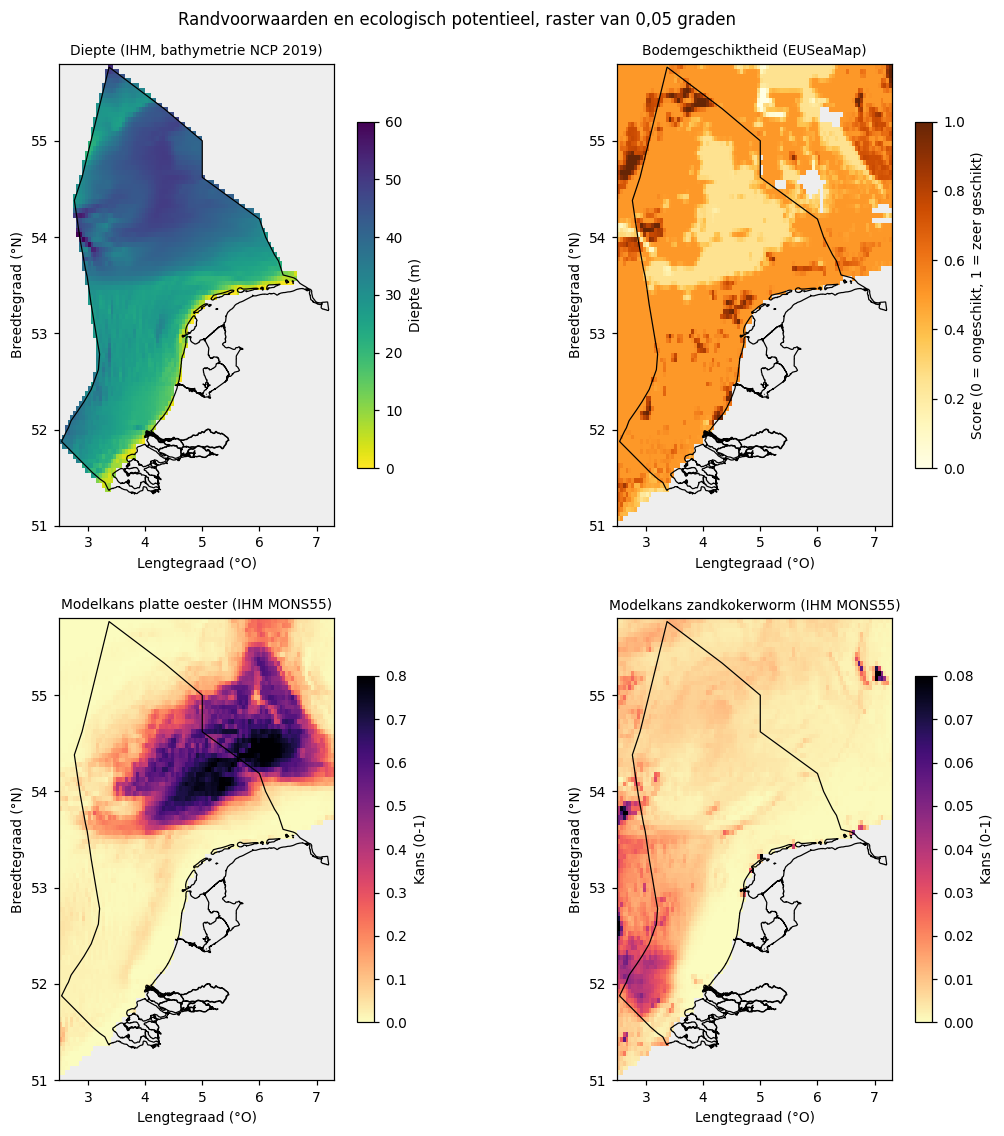

In [29]:
def grid_of(df, col):
    arr = np.full((NY, NX), np.nan)
    arr[df["iy"] - IY0, df["ix"] - IX0] = df[col].astype(float)
    return arr


ASPECT = 1 / np.cos(np.radians(53.4))


def base_map(ax, title):
    ax.set_facecolor("#eeeeee")
    ax.set_title(title, fontsize=9)
    ax.set_xlim(EXTENT[0], EXTENT[1])
    ax.set_ylim(EXTENT[2], EXTENT[3])
    ax.set_aspect(ASPECT)
    ax.set_xlabel("Lengtegraad (°O)")
    ax.set_ylabel("Breedtegraad (°N)")


def eez_outline(ax):
    eez.boundary.plot(ax=ax, color="black", linewidth=0.8)


def show(ax, arr, title, cmap="viridis", vmin=None, vmax=None, label=""):
    base_map(ax, title)
    im = ax.imshow(arr, origin="lower", extent=EXTENT, cmap=cmap, vmin=vmin, vmax=vmax, aspect=ASPECT, interpolation="nearest")
    eez_outline(ax)
    plt.colorbar(im, ax=ax, shrink=0.75, label=label)


fig, axes = plt.subplots(2, 2, figsize=(12, 12))
show(axes[0, 0], grid_of(cl, "depth_m"), "Diepte (IHM, bathymetrie NCP 2019)", "viridis_r", 0, 60, "Diepte (m)")
show(axes[0, 1], grid_of(cl, "substrate_score"), "Bodemgeschiktheid (EUSeaMap)", "YlOrBr", 0, 1, "Score (0 = ongeschikt, 1 = zeer geschikt)")
show(axes[1, 0], grid_of(cl, "p_ostrea"), "Modelkans platte oester (IHM MONS55)", "magma_r", 0, 0.8, "Kans (0-1)")
show(axes[1, 1], grid_of(cl, "p_sabellaria"), "Modelkans zandkokerworm (IHM MONS55)", "magma_r", 0, 0.08, "Kans (0-1)")
fig.suptitle("Randvoorwaarden en ecologisch potentieel, raster van 0,05 graden", y=0.92)
plt.show()

**Wat tonen de kaarten?** Diepte (linksboven) loopt van minder dan 10 m langs de kust tot ongeveer 45 tot 50 m in het noorden. De bodemgeschiktheid (rechtsboven) is hoog op grof en gemengd sediment en laag op slibrijk zand. De twee onderste kaarten tonen de modelkans voor de platte oester en de zandkokerworm.

**Interpretatie.**

- De modelkans voor de platte oester is hoog in het noordelijke deel van de EEZ (tot 0,83). Langs de kust is de kans laag.
- De modelkans voor de zandkokerworm en de paardenmossel is veel lager (hoogste waarde 0,10 en 0,05). Let op de andere schaal. Het notebook gebruikt daarom rangen in plaats van ruwe kansen.
- Het bodemtype is bijna overal *zand* (ongeveer 76% van het celoppervlak). Grof of gemengd sediment is zeldzaam. De bodemscore onderscheidt de cellen dus weinig. De rangschikking hangt daardoor vooral af van de modelkansen en de diepte.
- De modelkaarten zijn voorspellingen uit waarnemingen. Ze tonen geen vastgestelde aanwezigheid.

## 7.2 Drukfactoren, bescherming en bewijs van aanwezigheid

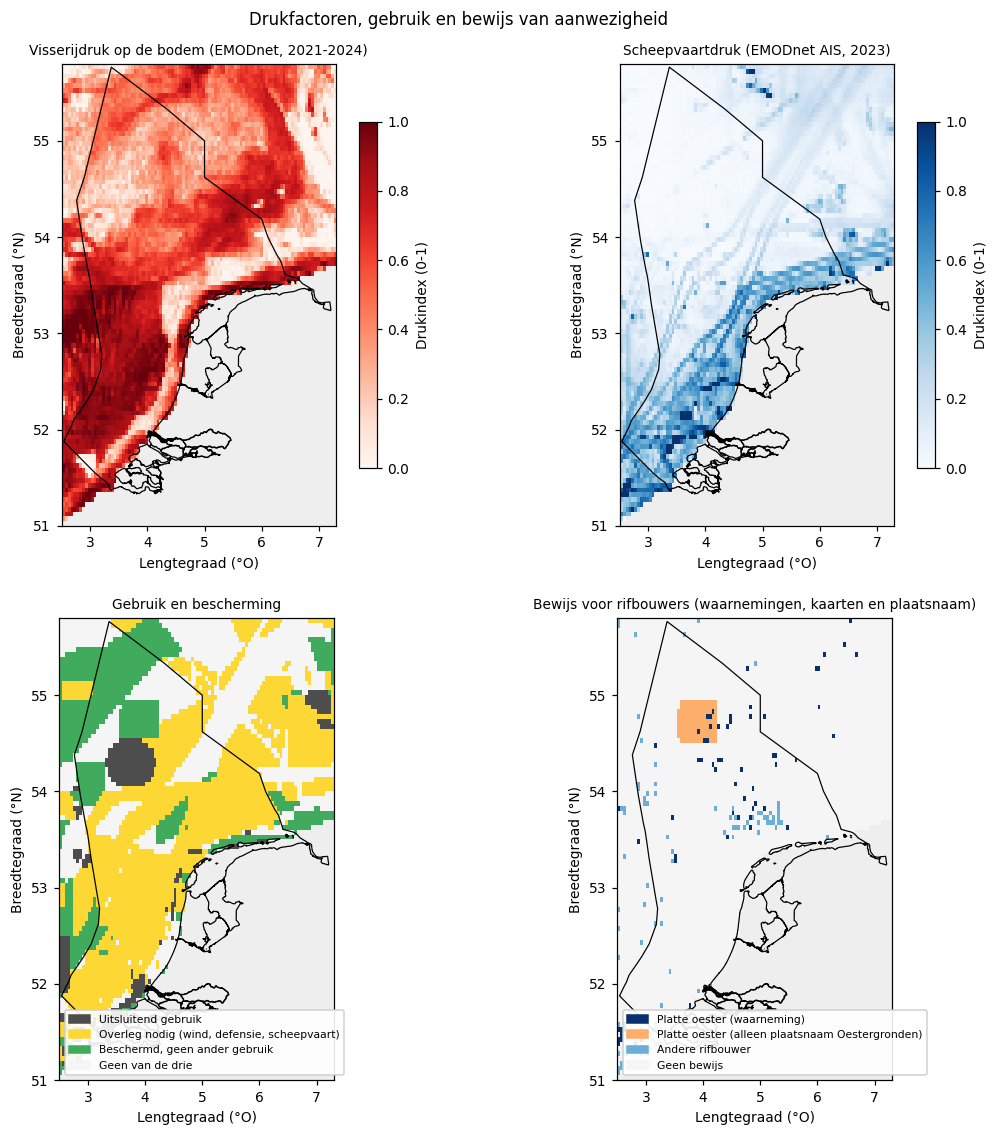

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
show(axes[0, 0], grid_of(cl, "fish_idx"), "Visserijdruk op de bodem (EMODnet, 2021-2024)", "Reds", 0, 1, "Drukindex (0-1)")
show(axes[0, 1], grid_of(cl, "ship_idx"), "Scheepvaartdruk (EMODnet AIS, 2023)", "Blues", 0, 1, "Drukindex (0-1)")

use_code = np.zeros(len(cl))
use_code[cl["negotiate"]] = 2
use_code[cl["blocked"]] = 1
use_code[cl["protected"] & ~cl["blocked"] & ~cl["negotiate"]] = 3
use_cmap = ListedColormap(["#f5f5f5", "#4d4d4d", "#fdd835", "#41ab5d"])
base_map(axes[1, 0], "Gebruik en bescherming")
axes[1, 0].imshow(grid_of(cl.assign(c=use_code), "c"), origin="lower", extent=EXTENT, cmap=use_cmap, vmin=0, vmax=3, aspect=ASPECT, interpolation="nearest")
eez_outline(axes[1, 0])
axes[1, 0].legend(handles=[Patch(color="#4d4d4d", label="Uitsluitend gebruik"), Patch(color="#fdd835", label="Overleg nodig (wind, defensie, scheepvaart)"),
                           Patch(color="#41ab5d", label="Beschermd, geen ander gebruik"), Patch(color="#f5f5f5", label="Geen van de drie")],
                  loc="lower left", fontsize=7, framealpha=0.9)

ev_code = np.zeros(len(cl))
ev_code[cl["ev_other_reef"]] = 1
ev_code[cl["ev_ostrea_name"]] = 2
ev_code[cl["ev_ostrea_obs"]] = 3
ev_cmap = ListedColormap(["#f5f5f5", "#6baed6", "#fdae6b", "#08306b"])
base_map(axes[1, 1], "Bewijs voor rifbouwers (waarnemingen, kaarten en plaatsnaam)")
axes[1, 1].imshow(grid_of(cl.assign(c=ev_code), "c"), origin="lower", extent=EXTENT, cmap=ev_cmap, vmin=0, vmax=3, aspect=ASPECT, interpolation="nearest")
eez_outline(axes[1, 1])
axes[1, 1].legend(handles=[Patch(color="#08306b", label="Platte oester (waarneming)"), Patch(color="#fdae6b", label="Platte oester (alleen plaatsnaam Oestergronden)"),
                           Patch(color="#6baed6", label="Andere rifbouwer"), Patch(color="#f5f5f5", label="Geen bewijs")],
                  loc="lower left", fontsize=7, framealpha=0.9)
fig.suptitle("Drukfactoren, gebruik en bewijs van aanwezigheid", y=0.92)
plt.show()

**Wat tonen de kaarten?** De bovenste kaarten tonen de visserijdruk en de scheepvaartdruk. Linksonder staan de gebieden met uitsluitend gebruik, de gebieden waar overleg nodig is en de beschermde gebieden. Rechtsonder staan de cellen met een waarneming of kaart van een rifbouwer.

**Interpretatie.**

- Bodemvisserij raakt bijna de hele EEZ. De gemiddelde drukindex is 0,56. Enkele gebieden in het noordoosten en een aantal beschermde gebieden hebben een lagere druk.
- Scheepvaart is geconcentreerd in routes. De druk is hoog bij de aanloop naar IJmuiden en in het zuidwesten. Elders is de druk laag.
- Veel cellen vragen overleg: 1.879 van 3.202 cellen liggen in een windpark, defensiegebied of scheepvaartzone. Slechts 251 cellen vallen af door uitsluitend gebruik. 1.200 cellen hebben geen van beide.
- Bewijs voor rifbouwers is schaars. Er zijn 41 cellen met een waarneming van de platte oester en 55 met een andere rifbouwer. In 90% van de cellen is geen MWTL-benthosmonster genomen. Een lege cel in de bewijskaart betekent dus *geen gegevens*, niet *afwezig*.
- Het oranje vlak (Oestergronden) is geen waarneming. Het toont alleen de plaatsnaam.

## 7.3 Indeling en zones

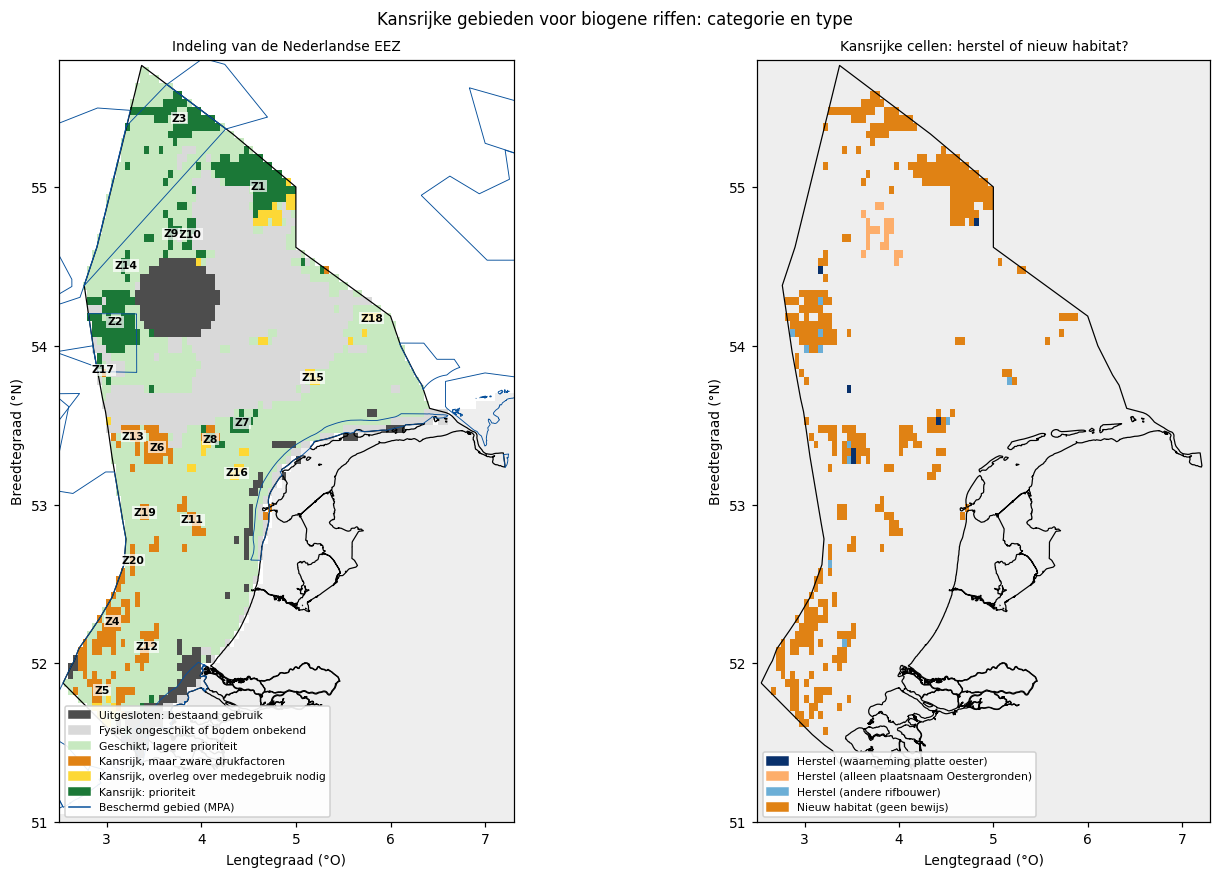

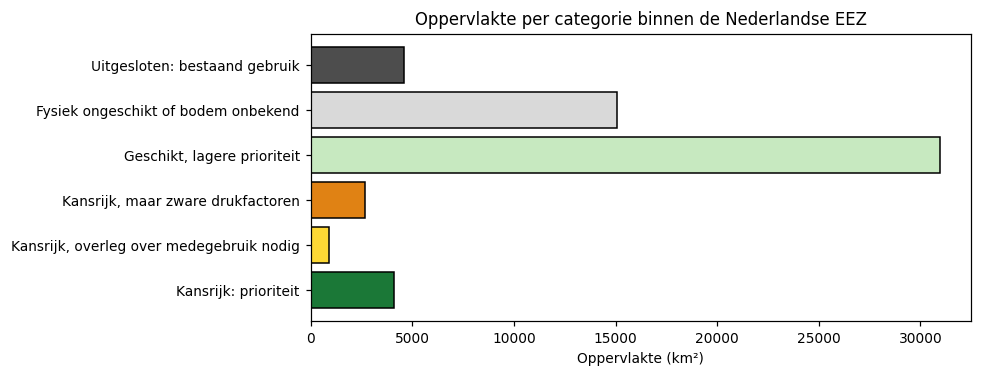

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 9))
cat_cmap = ListedColormap(CAT_COLORS)
base_map(axes[0], "Indeling van de Nederlandse EEZ")
axes[0].imshow(np.where(np.isnan(grid_of(cl, "category")), np.nan, grid_of(cl, "category")), origin="lower", extent=EXTENT,
               cmap=cat_cmap, vmin=0, vmax=6, aspect=ASPECT, interpolation="nearest")
eez_outline(axes[0])
mpa.boundary.plot(ax=axes[0], color="#08519c", linewidth=0.6)
for name, g in cl[cl["zone"].notna()].groupby("zone"):
    axes[0].text(g["lon"].mean(), g["lat"].mean(), name, fontsize=7, ha="center", va="center", fontweight="bold",
                 bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none", alpha=0.7))
axes[0].legend(handles=[Patch(color=CAT_COLORS[i], label=CATEGORIES[i]) for i in range(1, 7)] +
               [plt.Line2D([0], [0], color="#08519c", lw=1, label="Beschermd gebied (MPA)")], loc="lower left", fontsize=7, framealpha=0.9)

type_code = np.full(len(cl), np.nan)
promising_mask = cl["category"].isin([4, 5, 6])
for code, label in enumerate(["Nieuw habitat", "Herstel (andere rifbouwer)", "Herstel (platte oester, alleen plaatsnaam)", "Herstel (platte oester, waarneming)"]):
    type_code[promising_mask & (cl["evidence_type"] == label)] = code
base_map(axes[1], "Kansrijke cellen: herstel of nieuw habitat?")
axes[1].imshow(grid_of(cl.assign(c=type_code), "c"), origin="lower", extent=EXTENT,
               cmap=ListedColormap(["#e08214", "#6baed6", "#fdae6b", "#08306b"]), vmin=0, vmax=3, aspect=ASPECT, interpolation="nearest")
eez_outline(axes[1])
axes[1].legend(handles=[Patch(color="#08306b", label="Herstel (waarneming platte oester)"), Patch(color="#fdae6b", label="Herstel (alleen plaatsnaam Oestergronden)"),
                        Patch(color="#6baed6", label="Herstel (andere rifbouwer)"), Patch(color="#e08214", label="Nieuw habitat (geen bewijs)")],
               loc="lower left", fontsize=7, framealpha=0.9)
fig.suptitle("Kansrijke gebieden voor biogene riffen: categorie en type", y=0.93)
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.5))
bar = summary.reset_index().rename(columns={"index": "Categorie"})
ax.barh(bar["Categorie"], bar["Oppervlakte_km2"], color=[CAT_COLORS[k] for k in summary_codes], edgecolor="black")
ax.set_xlabel("Oppervlakte (km²)")
ax.set_title("Oppervlakte per categorie binnen de Nederlandse EEZ")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

**Wat tonen de kaarten?** Links staat de indeling in categorieën, met de zones (Z1, Z2, enzovoort) en de beschermde gebieden. Rechts staat voor de kansrijke cellen of het gaat om herstel (bewijs voor de soort) of nieuw habitat.

**Interpretatie en voorbehoud.**

- Van de 3.202 cellen zijn 424 kansrijk (7.692 km², 13% van de EEZ). Daarvan zijn 232 cellen *prioriteit*, 50 cellen vragen overleg en 142 cellen hebben zware drukfactoren.
- De zones met veel prioriteitscellen liggen in het noorden en noordwesten (Z1, Z3), bij de Klaverbank (Z2), de Oestergronden (Z9 en Z10) en het Friese Front (Z7). Zones in het zuiden (Z4, Z5, Z6, Z11, Z12) zijn kansrijk volgens de modelkaart, maar de visserij- en scheepvaartdruk is er hoog.
- Van de 424 kansrijke cellen heeft 91% (387 cellen) geen enkele aanwijzing voor eerdere aanwezigheid. Dat is **nieuw habitat** en geen herstel. Voor 37 cellen is er een aanwijzing: 6 cellen met een waarneming van de platte oester, 20 cellen met alleen de plaatsnaam Oestergronden en 11 cellen met een andere rifbouwer.
- De categorieën hangen af van de aannames in sectie 3.1. Een kansrijke cel is een plek om te onderzoeken en geen besluit.

## 7.4 Waarom is de natuurwaarde laag?

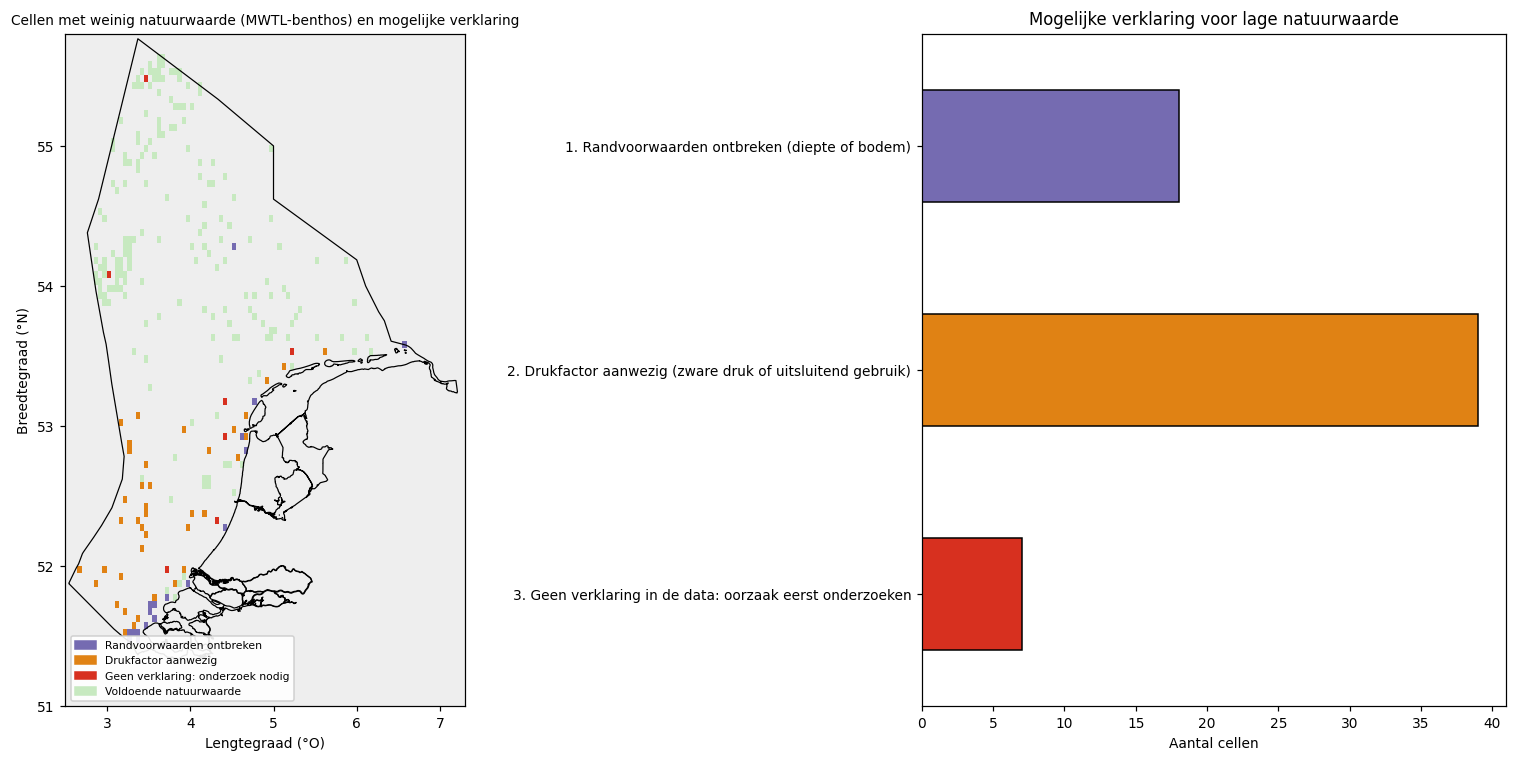

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1.3, 1]})
cause_code = np.full(len(cl), np.nan)
sel = cl["low_value"].fillna(False).astype(bool)
cause_code[sel & cl["cause"].str.startswith("1", na=False)] = 0
cause_code[sel & cl["cause"].str.startswith("2", na=False)] = 1
cause_code[sel & cl["cause"].str.startswith("3", na=False)] = 2
sampled_ok = cl["benthos_samples"].fillna(0) >= MIN_BENTHOS_SAMPLES
cause_code[~sel & sampled_ok & cl["low_value"].notna()] = 3
base_map(axes[0], "Cellen met weinig natuurwaarde (MWTL-benthos) en mogelijke verklaring")
axes[0].imshow(grid_of(cl.assign(c=cause_code), "c"), origin="lower", extent=EXTENT,
               cmap=ListedColormap(["#756bb1", "#e08214", "#d7301f", "#c7e9c0"]), vmin=0, vmax=3, aspect=ASPECT, interpolation="nearest")
eez_outline(axes[0])
axes[0].legend(handles=[Patch(color="#756bb1", label="Randvoorwaarden ontbreken"), Patch(color="#e08214", label="Drukfactor aanwezig"),
                        Patch(color="#d7301f", label="Geen verklaring: onderzoek nodig"), Patch(color="#c7e9c0", label="Voldoende natuurwaarde")],
               loc="lower left", fontsize=7, framealpha=0.9)
cause_table["Cellen"].plot.barh(ax=axes[1], color=["#756bb1", "#e08214", "#d7301f"][: len(cause_table)], edgecolor="black")
axes[1].set_xlabel("Aantal cellen")
axes[1].set_ylabel("")
axes[1].set_title("Mogelijke verklaring voor lage natuurwaarde")
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

**Wat tonen de grafieken?** Links staan alleen de cellen met minimaal 3 monsters. Rood zijn cellen met weinig soorten waarvoor de data geen verklaring geven. Rechts staat het aantal cellen per mogelijke verklaring.

**Interpretatie.**

- Van de 249 cellen met minimaal 3 monsters hebben 64 cellen weinig soorten (hoogstens 17,7 taxa per monster).
- Bij 39 van die 64 cellen (61%) is een drukfactor aanwezig. Bij 18 cellen (28%) zijn diepte of bodem niet geschikt. Bij slechts 7 cellen (11%) geven de data geen verklaring.
- Soortenrijkdom en drukindex hangen negatief samen (Spearman -0,61; alleen visserij -0,49). Dit is geen bewijs voor oorzaak en gevolg. Diepte, bodem en afstand tot de kust spelen ook mee.
- Alleen de rode groep (7 cellen) is een goede kandidaat voor onderzoek naar de oorzaak. Voor de andere cellen is herstel pas zinvol als de drukfactor eerst afneemt of als herstel op een andere plek plaatsvindt.
- Van de 52 kansrijke cellen met monsters hebben er 7 (13%) weinig soorten. De overige 45 cellen hebben geen aanwijzing voor een rifbouwer in de monsters. Dat wijst op **nieuw habitat**.

## 7.5 Natuurherstel en medegebruik

De linker kaart toont voor elke kansrijke cel het belangrijkste medegebruik. De rechter kaart toont het aantal afspraken dat nodig is. De grafiek toont de zuurstofrisico's in de kansrijke cellen.

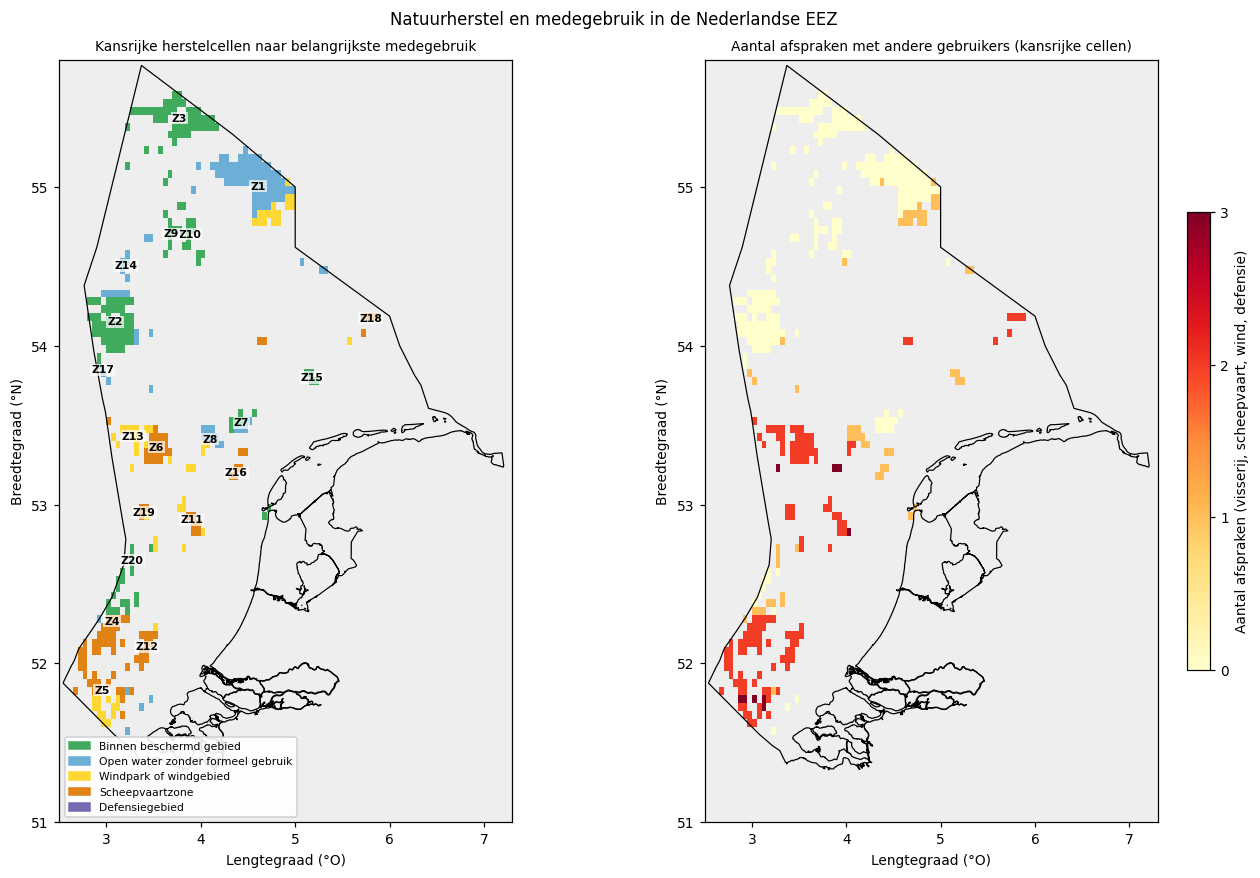

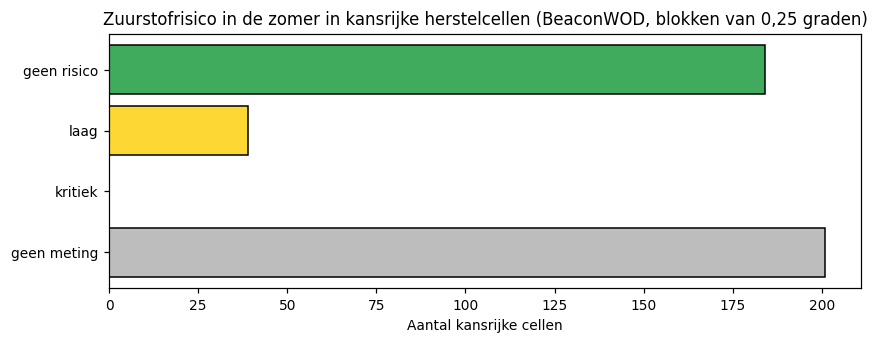

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 9))
COR_ORDER = ["Binnen beschermd gebied", "Open water zonder formeel gebruik", "Windpark of windgebied", "Scheepvaartzone", "Defensiegebied"]
COR_COL = ["#41ab5d", "#6baed6", "#fdd835", "#e08214", "#756bb1"]
code = np.full(len(cl), np.nan)
for i, c in enumerate(COR_ORDER):
    code[(cl["restore"] & (cl["coruse"] == c)).to_numpy()] = i
base_map(axes[0], "Kansrijke herstelcellen naar belangrijkste medegebruik")
axes[0].imshow(grid_of(cl.assign(c=code), "c"), origin="lower", extent=EXTENT, cmap=ListedColormap(COR_COL), vmin=0, vmax=len(COR_COL) - 1,
               aspect=ASPECT, interpolation="nearest")
eez_outline(axes[0])
axes[0].legend(handles=[Patch(color=COR_COL[i], label=COR_ORDER[i]) for i in range(len(COR_ORDER))], loc="lower left", fontsize=7, framealpha=0.9)
for name, g in cl[cl["zone"].notna()].groupby("zone"):
    axes[0].text(g["lon"].mean(), g["lat"].mean(), name, fontsize=7, ha="center", va="center", fontweight="bold",
                 bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none", alpha=0.7))

agr = np.where(cl["restore"], cl["n_agreements"], np.nan)
base_map(axes[1], "Aantal afspraken met andere gebruikers (kansrijke cellen)")
im = axes[1].imshow(grid_of(cl.assign(c=agr), "c"), origin="lower", extent=EXTENT, cmap="YlOrRd", vmin=0, vmax=3, aspect=ASPECT, interpolation="nearest")
eez_outline(axes[1])
plt.colorbar(im, ax=axes[1], shrink=0.6, ticks=[0, 1, 2, 3], label="Aantal afspraken (visserij, scheepvaart, wind, defensie)")
fig.suptitle("Natuurherstel en medegebruik in de Nederlandse EEZ", y=0.93)
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.2))
risk = cl[cl["restore"]]["o2_risk"].value_counts().reindex(["geen risico", "laag", "kritiek", "geen meting"]).fillna(0)
ax.barh(risk.index, risk.values, color=["#41ab5d", "#fdd835", "#d7301f", "#bdbdbd"], edgecolor="black")
ax.set_xlabel("Aantal kansrijke cellen")
ax.set_title("Zuurstofrisico in de zomer in kansrijke herstelcellen (BeaconWOD, blokken van 0,25 graden)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

**Interpretatie.**

- Van de 424 kansrijke cellen (7.692 km²) liggen er 155 (37%) in een beschermd gebied, 111 (26%) in open water zonder formeel gebruik, 99 (23%) in een scheepvaartzone en 59 (14%) in een windpark of windgebied.
- Het aantal afspraken verschilt sterk per zone. In het noorden (Z1, Z3) en bij de beschermde gebieden (Z2, Z7, Z9, Z10) zijn weinig tot geen afspraken nodig. In het zuiden (Z4, Z5, Z6, Z11, Z12) liggen de cellen in een scheepvaartzone, is er veel bodemvisserij en zijn gemiddeld twee afspraken nodig.
- In totaal vragen 146 cellen (34%) om beperking van visserij, 121 cellen (29%) om overleg over scheepvaart, 64 cellen (15%) om overleg over een windpark en 8 cellen (2%) om overleg met Defensie. In 196 cellen (46%) ligt een kabel of leiding.
- **230 cellen (4.096 km²) vragen geen extra afspraken.** Daarvan hebben er 27 een aanwijzing voor eerdere aanwezigheid. Dit zijn de meest eenvoudige startlocaties.
- Geen kansrijke cel heeft een *kritiek* zuurstofrisico. Voor 39 cellen is het risico *laag* en voor 201 cellen is er geen WOD-meting. Zones met laag zuurstofrisico zijn Z2 (11 cellen), Z1 (6 cellen) en Z5 (5 cellen). De zuurstofdata zijn grof (sectie 8.6).

## 7.6 Nieuwe beschermde gebieden (MPA's)

De eerste grafiek toont per habitattype welk deel nu beschermd is, tegenover het doel van 30%. De kaarten tonen de MPA-score van de cellen die in aanmerking komen, de kandidaten met de zones en de lagen die het meest bijdragen.

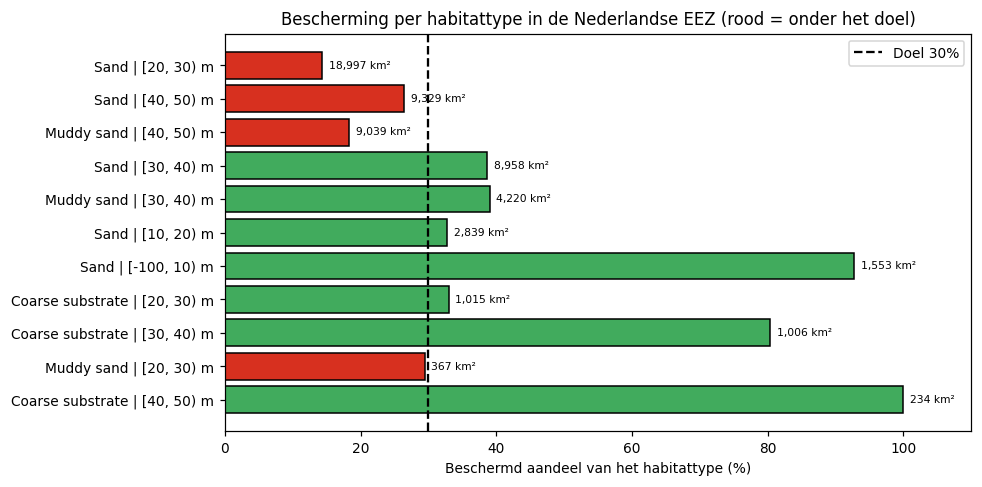

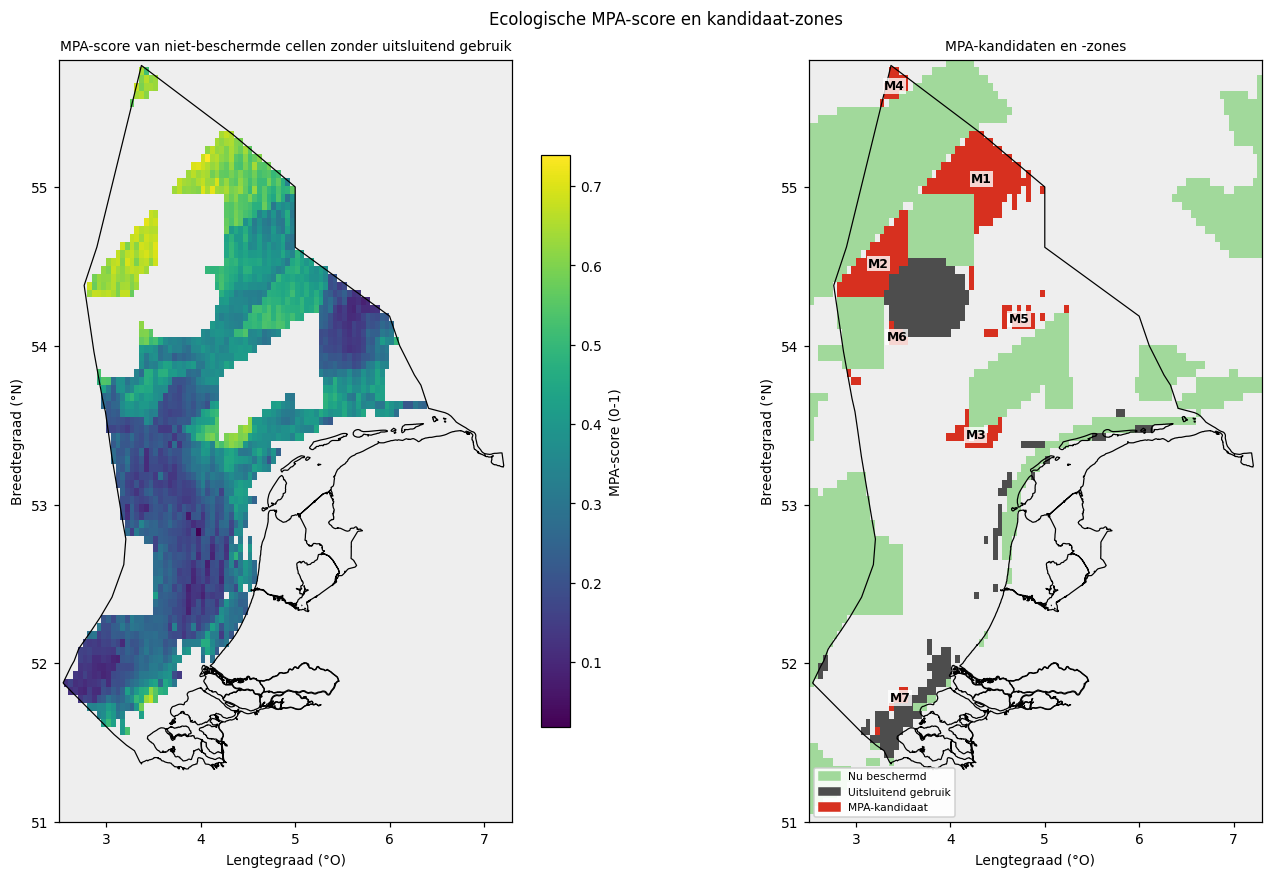

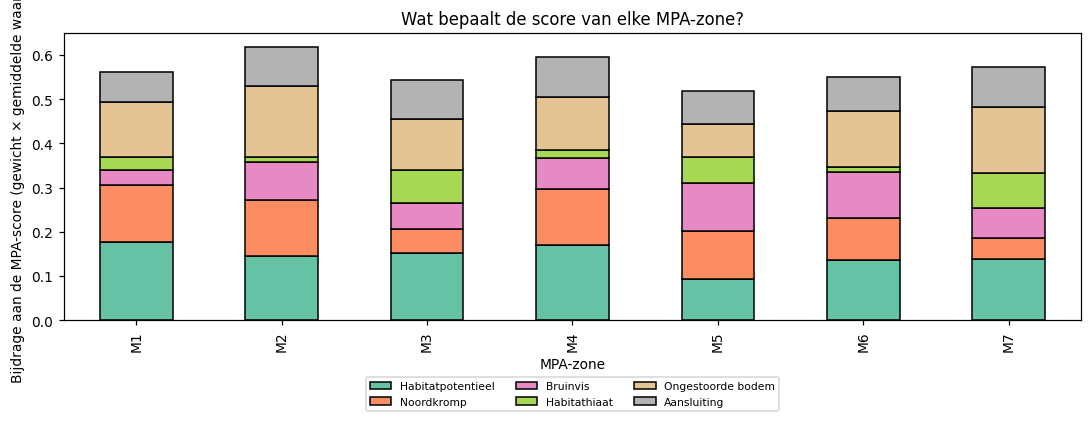

In [34]:
h = hab[hab["Cellen"] >= MIN_OVERLAP_CELLS].sort_values("Oppervlakte_km2")
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["#d7301f" if s < PROTECTION_TARGET else "#41ab5d" for s in h["Beschermd_aandeel"]]
ax.barh(h.index, h["Beschermd_aandeel"] * 100, color=colors, edgecolor="black")
ax.axvline(PROTECTION_TARGET * 100, color="black", linestyle="--", label=f"Doel {PROTECTION_TARGET:.0%}")
for i, (hab_name, row) in enumerate(h.iterrows()):
    ax.text(row["Beschermd_aandeel"] * 100 + 1, i, f"{row['Oppervlakte_km2']:,.0f} km²", va="center", fontsize=7)
ax.set_xlabel("Beschermd aandeel van het habitattype (%)")
ax.set_title("Bescherming per habitattype in de Nederlandse EEZ (rood = onder het doel)")
ax.set_xlim(0, 110)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 9))
show(axes[0], grid_of(cl.assign(c=cl["mpa_score_adj"].where(cl["mpa_eligible"])), "c"), "MPA-score van niet-beschermde cellen zonder uitsluitend gebruik", "viridis", None, None, "MPA-score (0-1)")
base_map(axes[1], "MPA-kandidaten en -zones")
ctype = np.full(len(cl), np.nan)
ctype[cl["protected"].to_numpy()] = 0
ctype[cl["blocked"].to_numpy() & cl["in_nl"].to_numpy()] = 1
ctype[cl["mpa_candidate"].to_numpy()] = 2
axes[1].imshow(grid_of(cl.assign(c=ctype), "c"), origin="lower", extent=EXTENT, cmap=ListedColormap(["#a1d99b", "#4d4d4d", "#d7301f"]), vmin=0, vmax=2,
               aspect=ASPECT, interpolation="nearest")
eez_outline(axes[1])
for name, g in cl[cl["mpa_zone"].notna()].groupby("mpa_zone"):
    axes[1].text(g["lon"].mean(), g["lat"].mean(), name, fontsize=8, ha="center", va="center", fontweight="bold",
                 bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none", alpha=0.8))
axes[1].legend(handles=[Patch(color="#a1d99b", label="Nu beschermd"), Patch(color="#4d4d4d", label="Uitsluitend gebruik"),
                        Patch(color="#d7301f", label="MPA-kandidaat")], loc="lower left", fontsize=7, framealpha=0.9)
fig.suptitle("Ecologische MPA-score en kandidaat-zones", y=0.93)
plt.show()

contrib = pd.DataFrame(
    {z: {k: MPA_WEIGHTS[k] * cl.loc[cl["mpa_zone"] == z, f"v_{k}"].fillna(0).mean() for k in MPA_LAYERS} for z in mpa_zones["Zone"]}).T
labels_nl = {"habitat": "Habitatpotentieel", "quahog": "Noordkromp", "porpoise": "Bruinvis", "gap": "Habitathiaat", "integrity": "Ongestoorde bodem", "connect": "Aansluiting"}
fig, ax = plt.subplots(figsize=(10, 4))
contrib.rename(columns=labels_nl).plot.bar(stacked=True, ax=ax, edgecolor="black", colormap="Set2")
ax.set_ylabel("Bijdrage aan de MPA-score (gewicht × gemiddelde waarde)")
ax.set_xlabel("MPA-zone")
ax.set_title("Wat bepaalt de score van elke MPA-zone?")
ax.legend(fontsize=7, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
plt.tight_layout()
plt.show()

**Interpretatie.**

- Het beschermde deel van de hele EEZ is 28%. Dat is dicht bij het doel van 30%, maar de bescherming is niet gelijk verdeeld over de habitattypen. Drie van de elf beoordeelde habitattypen liggen duidelijk onder het doel: *zand op 20 tot 30 m* (14% beschermd, 18.997 km², tekort ongeveer 2.985 km²), *slibrijk zand op 40 tot 50 m* (18%, tekort ongeveer 1.057 km²) en *zand op 40 tot 50 m* (26%, tekort ongeveer 331 km²). *Slibrijk zand op 20 tot 30 m* ligt op 29%, vlak onder het doel. Negen van de twintig habitattypen zijn te klein (minder dan 10 cellen) om te beoordelen.
- Het notebook vindt 307 kandidaatcellen (5.469 km²), die samen 7 zones vormen van 5.216 km² (8,9% van de EEZ). Zes zones sluiten aan op een bestaand beschermd gebied. Eén zone (M6, 8 cellen, bij de Klaverbank) staat los.
- **M1** (139 cellen, 2.450 km², 4,3°O 55,1°N, 46 m, zand) is de grootste zone. De hoge habitatscore bepaalt de score. De zone sluit aan op de Oestergronden en de Doggersbank. De zone valt voor 41% samen met herstelzone Z1.
- **M2** (85 cellen, 1.518 km², 40 m) heeft de hoogste score (0,65), de laagste visserijdruk (0,20) en een hoge bruinvisdichtheid (1,55). De zone is in alle 9 scenario's een kandidaat.
- **M3** (25 cellen, 458 km², 26 m, Friese Front) en **M7** (6 cellen, 114 km², Voordelta) liggen in ondiep water, waar zand op 20 tot 30 m het grootste hiaat heeft. **M4** (15 cellen, Doggersbank) is robuust. **M5** (15 cellen, slibrijk zand, 45 m) wordt gedragen door de noordkromp, heeft hoge visserijdruk (0,63) en 15 cellen met laag zuurstofrisico.
- De score hangt vooral af van de gewichten voor de ecologische lagen en van de aftrek voor overleg (sectie 8.7). Zonder die aftrek is de overlap met de basis 52%.
- De ecologische logica zegt *waar* een MPA het netwerk aanvult. Het zegt niet of een MPA haalbaar is. Het voormalige verbrandingsgebied (ongeveer 2.400 km² rond 3,8°O 54,3°N) valt volgens de data onder stortlocaties en is uitgesloten. Dat gebied ligt ecologisch tussen M2 en M6.

## 7.7 Overlap van monitoring

De kaarten tonen het aantal biotische monitoringgroepen per cel en de plekken waar groepen in hetzelfde jaar meten. De heatmaps tonen de overlap per paar groepen en de dekking per habitattype.

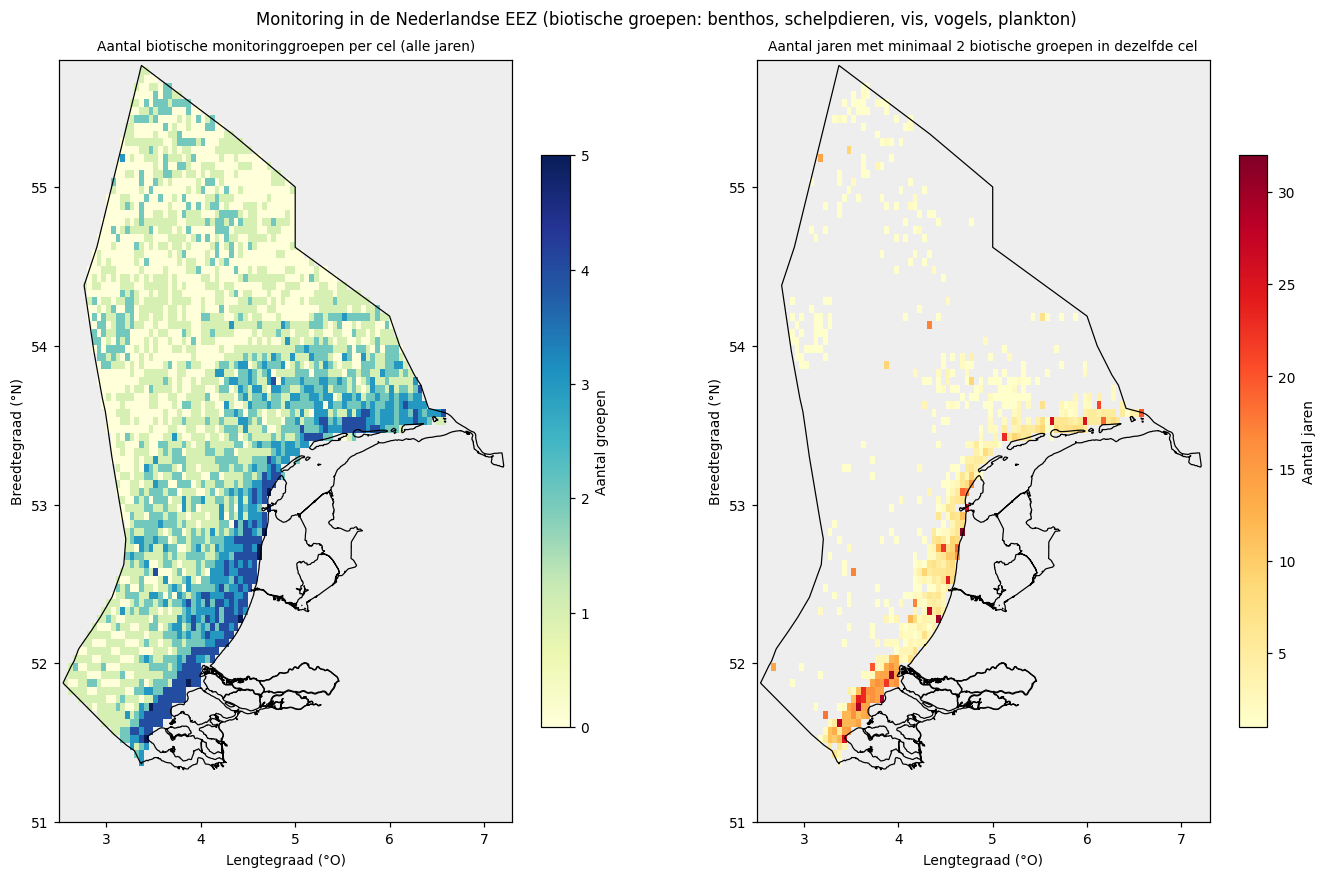

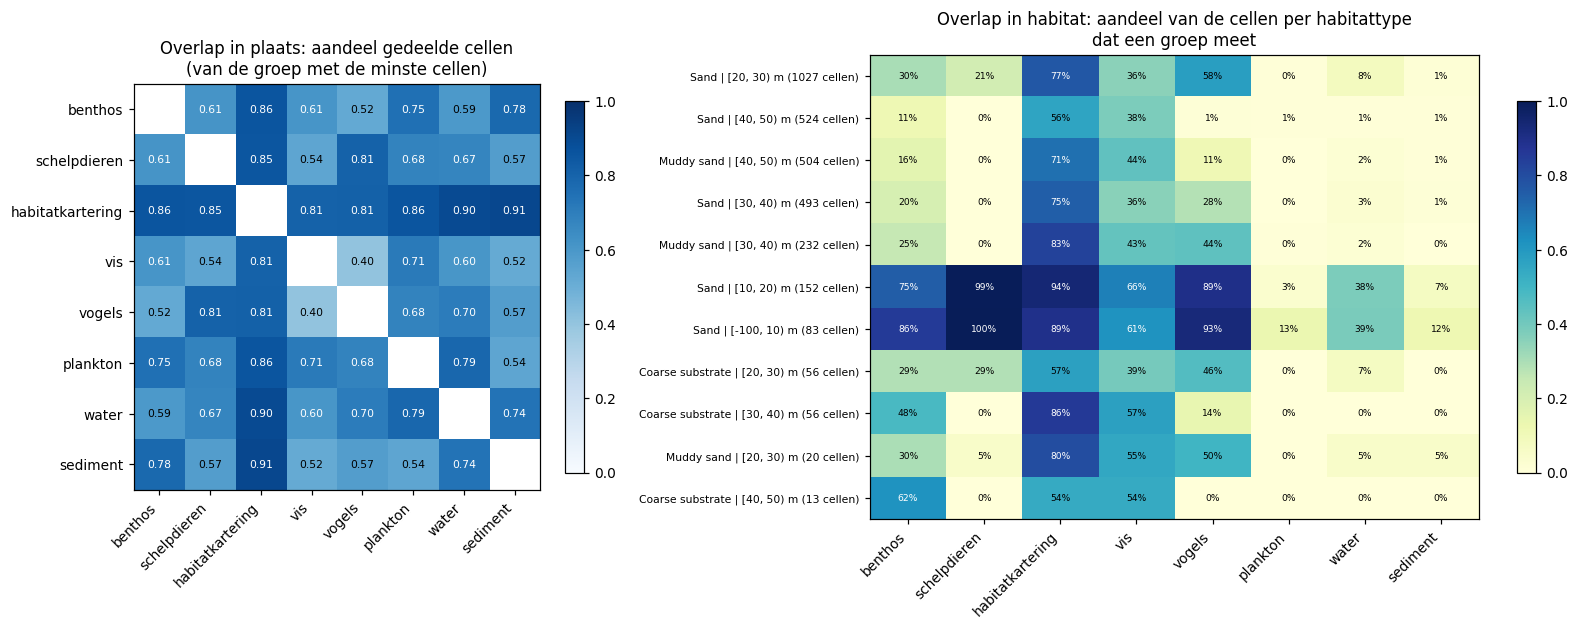

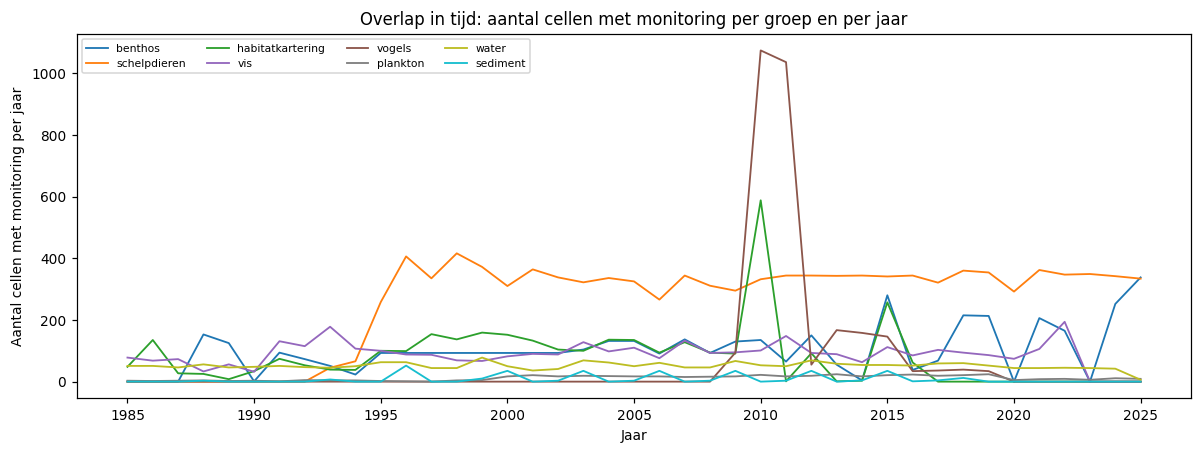

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(15, 9))
show(axes[0], grid_of(cl.assign(c=cl["biotic_present"].where(cl["in_nl"])), "c"), "Aantal biotische monitoringgroepen per cel (alle jaren)", "YlGnBu", 0, 5, "Aantal groepen")
show(axes[1], grid_of(cl.assign(c=cl["sync_years"].where(cl["in_nl"] & (cl["sync_years"] > 0))), "c"),
     "Aantal jaren met minimaal 2 biotische groepen in dezelfde cel", "YlOrRd", 1, None, "Aantal jaren")
fig.suptitle("Monitoring in de Nederlandse EEZ (biotische groepen: benthos, schelpdieren, vis, vogels, plankton)", y=0.93)
plt.show()

M = np.zeros((len(GROUPS), len(GROUPS)))
for _, r in pairs.iterrows():
    i, j = GROUPS.index(r["Groep A"]), GROUPS.index(r["Groep B"])
    M[i, j] = M[j, i] = r["Aandeel van kleinste"]
np.fill_diagonal(M, np.nan)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw={"width_ratios": [1, 1.5]})
im = axes[0].imshow(M, cmap="Blues", vmin=0, vmax=1)
axes[0].set_xticks(range(len(GROUPS)))
axes[0].set_yticks(range(len(GROUPS)))
axes[0].set_xticklabels(GROUPS, rotation=45, ha="right")
axes[0].set_yticklabels(GROUPS)
for i in range(len(GROUPS)):
    for j in range(len(GROUPS)):
        if i != j:
            axes[0].text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if M[i, j] > 0.6 else "black")
axes[0].set_title("Overlap in plaats: aandeel gedeelde cellen\n(van de groep met de minste cellen)")
plt.colorbar(im, ax=axes[0], shrink=0.8)
hc = hab_cov[GROUPS]
im2 = axes[1].imshow(hc.to_numpy(), cmap="YlGnBu", vmin=0, vmax=1, aspect="auto")
axes[1].set_xticks(range(len(GROUPS)))
axes[1].set_xticklabels(GROUPS, rotation=45, ha="right")
axes[1].set_yticks(range(len(hc)))
axes[1].set_yticklabels([f"{n} ({int(hab_cov.loc[n, 'Cellen'])} cellen)" for n in hc.index], fontsize=7)
for i in range(len(hc)):
    for j in range(len(GROUPS)):
        axes[1].text(j, i, f"{hc.iat[i, j]:.0%}", ha="center", va="center", fontsize=6, color="white" if hc.iat[i, j] > 0.6 else "black")
axes[1].set_title("Overlap in habitat: aandeel van de cellen per habitattype\ndat een groep meet")
plt.colorbar(im2, ax=axes[1], shrink=0.8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 4.2))
yrs = mon.dropna(subset=["year"]).drop_duplicates(["ix", "iy", "group", "year"])
yrs = yrs[[k in nl_keys for k in zip(yrs["ix"], yrs["iy"])]]
yy = yrs.groupby(["year", "group"]).size().unstack("group").reindex(columns=GROUPS).fillna(0)
yy = yy.loc[yy.index >= 1985]
yy.plot(ax=ax, linewidth=1.2, colormap="tab10")
ax.set_xlabel("Jaar")
ax.set_ylabel("Aantal cellen met monitoring per jaar")
ax.set_title("Overlap in tijd: aantal cellen met monitoring per groep en per jaar")
ax.legend(fontsize=7, ncol=4)
plt.tight_layout()
plt.show()

**Interpretatie.**

*Overlap in plaats*

- In de EEZ hebben 36 van de 38 tabellen data. De trekvistabel (WMR) en de toegevoegde tabel `ihm_vis_monitoring` hebben geen data in de EEZ. 373 cellen (12%) hebben geen enkele monitoring, 942 cellen één groep en 456 cellen (14%) vier of meer groepen. Voor de biotische groepen hebben 1.017 cellen (32%) niets, 1.123 cellen één groep, 624 cellen twee groepen en 438 cellen drie of meer. In de vorige versie was dat 35% zonder biotische monitoring.
- De overlap concentreert zich langs de kust (kaart links). Dat zijn de stations van Rijkswaterstaat, de Voordelta en de Zeeuwse en Hollandse kust. Op de open Noordzee meet meestal één groep per cel, of geen.
- De sterkste overlap per paar is bij groepen met veel cellen. Van de cellen met benthos meet ook *habitatkartering* in 86% en *vis* in 61%. Van de cellen met schelpdieren meet ook *vogels* in 81%.

*Overlap in tijd*

- In 603 cellen (19%) meten minimaal twee biotische groepen in hetzelfde jaar. Dit zit voor het grootste deel in de kustzone (kaart rechts).
- De dekking per groep is niet constant. Schelpdieren (WOT en `ihm_wmr`) meten sinds 1996 jaarlijks in ongeveer 300 tot 420 cellen. Vogelmetingen vallen vooral in twee jaren (2010 en 2011, ongeveer 1.050 cellen in de WOZ-telling). Benthos meet meestal in 50 tot 200 cellen per jaar. Het aantal piekt in 2015 (ongeveer 280 cellen) en in 2025 (ongeveer 340 cellen). Dat komt door de Aquadesk-stations. Vis heeft ongeveer 70 tot 190 cellen per jaar en plankton minder dan 30.

*Overlap in ecologie*

- Programma's met dezelfde functie en dezelfde stations: fytoplankton en diatomeeën van Rijkswaterstaat (Jaccard 1,00: dezelfde 20 cellen, 319 gedeelde cel-jaren), MWTL-benthos en de boomkorvisserij van Rijkswaterstaat (200 gedeelde cellen, Jaccard 0,60; alle 217 cel-jaren van de boomkor vallen samen met benthos), en de projecten NSW en OWEZ voor benthos (Jaccard 0,88). Dit zijn kansen om te combineren, of waar dat al gebeurt, te behouden.
- **Toegevoegde tabellen die bestaande tabellen grotendeels herhalen.** Aquadesk-fytoplankton bevat alle cel-jaren van beide plankton-tabellen van Rijkswaterstaat. Aquadesk-bodemfauna en MWTL-benthos delen 312 cellen. Aquadesk bevat 97% van de cel-jaren van MWTL-benthos en voegt zelf 22% extra cel-jaren toe. De tabel `ihm_wmr` en de WOT-schelpdiermonitoring delen 447 cellen met 98% dezelfde cel-jaren. Beide tabellen hebben het label IHM-KRM en hetzelfde monsternummerpatroon. Het notebook beschouwt ze daarom als één survey. Dit zijn geen aparte meetactiviteiten. Het zijn kansen om dubbele opslag en dubbele telling te vermijden.
- Benthos (MWTL, Aquadesk en projecten) en schelpdieren (WOT en `ihm_wmr`) meten in 299 cellen allebei. In 142 van die cellen meten ze in dezelfde jaren (1.061 cel-jaren). Dat is een kandidaat voor afstemming van methodes.
- *Overlap in habitat:* de ondiepe habitats (0 tot 20 m) hebben gemiddeld 3,3 tot 3,5 biotische groepen per cel. De diepere habitats hebben veel minder: zand op 40 tot 50 m gemiddeld 0,51, slibrijk zand op 40 tot 50 m gemiddeld 0,71 en zand op 30 tot 40 m gemiddeld 0,85. Voor zand op 40 tot 50 m heeft 56% van de cellen geen biotische monitoring. Schelpdieren (WOT) meten alleen in water ondieper dan 30 m. Plankton en water meten in de diepe habitats vrijwel niet.
- **Plekken met veel overlap:** 206 cellen in 53 clusters hebben sinds 2010 minimaal vier groepen. Het grootste cluster (52 cellen, 3,6°O 51,7°N, Voordelta) is voor 83% beschermd. De volgende clusters liggen bij de Hollandse kust (4,5°O 52,7°N met 40 cellen en 4,35°O 52,3°N met 12 cellen) en bij Ameland (5,7°O 53,5°N met 16 cellen). Deze plekken passen voor geïntegreerde monitoring.

## 7.8 Koppeling: herstel, bescherming en monitoring

De kaart toont waar herstel en bescherming samenvallen en waar een nulmeting ontbreekt. De grafiek toont de monitoringdekking per zone.

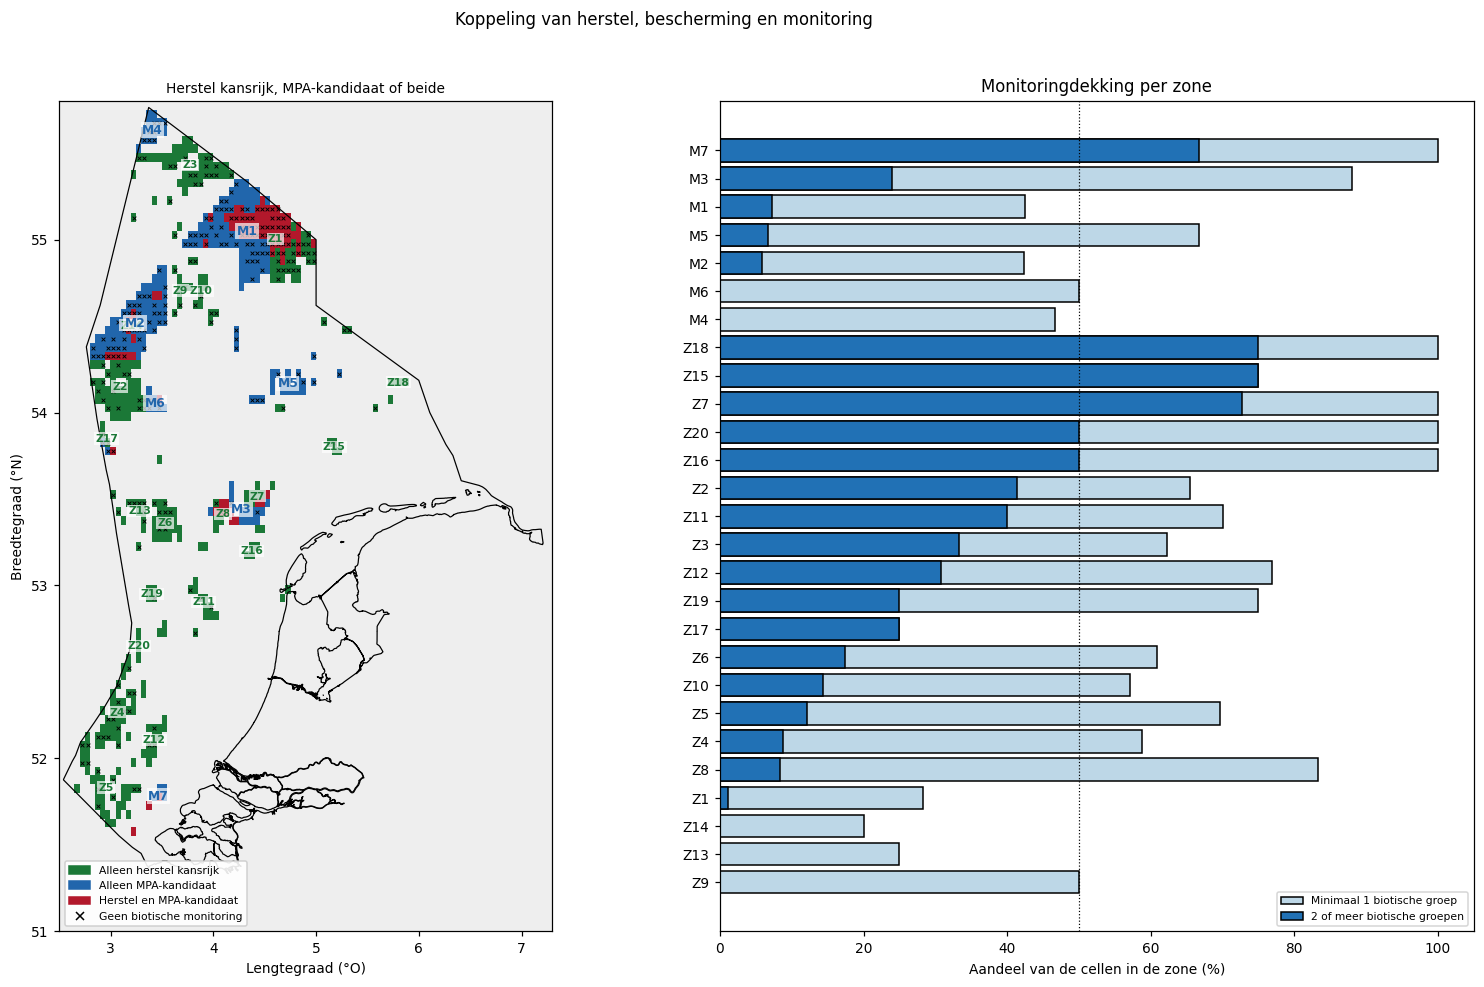

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 9), gridspec_kw={"width_ratios": [1.2, 1]})
COMBO_ORDER = ["Alleen herstel kansrijk", "Alleen MPA-kandidaat", "Herstel en MPA-kandidaat"]
COMBO_COL = ["#1b7837", "#2166ac", "#b2182b"]
cc = np.full(len(cl), np.nan)
for i, c in enumerate(COMBO_ORDER):
    cc[(cl["combo"] == c).to_numpy()] = i
base_map(axes[0], "Herstel kansrijk, MPA-kandidaat of beide")
axes[0].imshow(grid_of(cl.assign(c=cc), "c"), origin="lower", extent=EXTENT, cmap=ListedColormap(COMBO_COL), vmin=0, vmax=2, aspect=ASPECT, interpolation="nearest")
eez_outline(axes[0])
nomon = cl["in_nl"] & cl["combo"].isin(COMBO_ORDER) & (cl["biotic_present"] == 0)
axes[0].scatter(cl.loc[nomon, "lon"], cl.loc[nomon, "lat"], s=6, c="black", marker="x", linewidths=0.6, label="Geen biotische monitoring")
axes[0].legend(handles=[Patch(color=COMBO_COL[i], label=COMBO_ORDER[i]) for i in range(3)] +
               [plt.Line2D([0], [0], marker="x", color="black", linestyle="", markersize=5, label="Geen biotische monitoring")], loc="lower left", fontsize=7, framealpha=0.9)
for name, g in cl[cl["zone"].notna()].groupby("zone"):
    axes[0].text(g["lon"].mean(), g["lat"].mean(), name, fontsize=7, ha="center", va="center", fontweight="bold", color="#1b7837",
                 bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none", alpha=0.7))
for name, g in cl[cl["mpa_zone"].notna()].groupby("mpa_zone"):
    axes[0].text(g["lon"].mean(), g["lat"].mean(), name, fontsize=8, ha="center", va="center", fontweight="bold", color="#2166ac",
                 bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none", alpha=0.7))

cov_all = pd.concat([rest_cov.assign(Soort="Herstelzone"), mpa_cov.assign(Soort="MPA-zone")])
cov_all = cov_all.sort_values(["Soort", "% met 2 of meer biotische groepen"], ascending=[True, True])
axes[1].barh(cov_all.index, cov_all["% biotisch gemeten"].astype(float), color="#bdd7e7", edgecolor="black", label="Minimaal 1 biotische groep")
axes[1].barh(cov_all.index, cov_all["% met 2 of meer biotische groepen"].astype(float), color="#2171b5", edgecolor="black", label="2 of meer biotische groepen")
axes[1].axvline(50, color="black", linestyle=":", lw=0.8)
axes[1].set_xlabel("Aandeel van de cellen in de zone (%)")
axes[1].set_title("Monitoringdekking per zone")
axes[1].legend(fontsize=7, loc="lower right")
fig.suptitle("Koppeling van herstel, bescherming en monitoring", y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

**Interpretatie.**

- 424 cellen zijn kansrijk voor herstel en 307 cellen zijn MPA-kandidaat. **87 cellen (1.550 km²) zijn beide.** Die cellen liggen vooral in M1 en Z1 (55 cellen), en verder in M3 met Z8 en Z7, en in M2 met Z2 en Z14. Het zijn plekken waar herstel en bescherming elkaar kunnen versterken. Het notebook beoordeelt niet welk doel er voorgaat.
- **De plekken die het meest voor de koppeling in aanmerking komen, hebben de minste monitoring.** Van de cellen die zowel herstel als MPA zijn, heeft 61% geen enkele biotische monitoring. Bij cellen met alleen herstel is dat 38%, bij cellen met alleen MPA 49% en in de rest van de EEZ 28%. Een nulmeting ontbreekt dus juist op de plekken met de meeste kansen.
- Van de 20 herstelzones zijn er vijf goed gedekt (Z7, Z15, Z16, Z18 en Z20), 14 gedeeltelijk en één (Z14) heeft een hiaat. Van de 7 MPA-zones is er één goed gedekt (M7, Voordelta). M1 (de grootste MPA-zone) heeft in 42% van de cellen biotische monitoring en in 7% twee of meer groepen. Herstelzone Z1 heeft die dekking in 28% en 1% van de cellen.
- Het zwarte kruis op de kaart toont de cellen zonder biotische monitoring. Daar is een nulmeting het eerste dat nodig is.

# 8. Validatie en betrouwbaarheidscontroles

## 8.1 Dieptecontrole: twee bronnen

De dieptekaart uit `mon_morphology_bathymetry_ncp_2019` (Nederlands Continentaal Plat) is de basis. De controle vergelijkt die met de aparte dieptelaag `prj_nzb_depth`. Die laag heeft niet overal waarden.

Cellen met beide dieptes: 2458 van 3202 cellen in de EEZ
Correlatie (Pearson): 0.984
Mediaan van het verschil NZB min NCP: 0.2 m | gemiddeld absoluut verschil: 0.9 m
Binnen 5 m: 99% | binnen 10 m: 99%
Cellen in het dieptebereik (10, 50): NCP 2349 | NZB 2358 | beide 2340


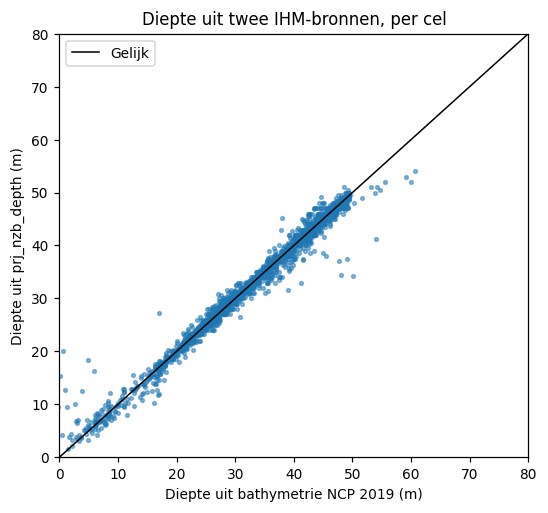

In [37]:
both = cl[cl["in_nl"] & cl["depth_m"].notna() & cl["depth_nzb_m"].notna()]
diff = both["depth_nzb_m"] - both["depth_m"]
print(f"Cellen met beide dieptes: {len(both)} van {int(cl['in_nl'].sum())} cellen in de EEZ")
print(f"Correlatie (Pearson): {both['depth_m'].corr(both['depth_nzb_m']):.3f}")
print(f"Mediaan van het verschil NZB min NCP: {diff.median():.1f} m | gemiddeld absoluut verschil: {diff.abs().mean():.1f} m")
print(f"Binnen 5 m: {(diff.abs() <= 5).mean():.0%} | binnen 10 m: {(diff.abs() <= 10).mean():.0%}")
in_a = both["depth_m"].between(*DEPTH_RANGE_M)
in_b = both["depth_nzb_m"].between(*DEPTH_RANGE_M)
print(f"Cellen in het dieptebereik {DEPTH_RANGE_M}: NCP {in_a.sum()} | NZB {in_b.sum()} | beide {(in_a & in_b).sum()}")
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(both["depth_m"], both["depth_nzb_m"], s=6, alpha=0.5)
lim = [0, 80]
ax.plot(lim, lim, color="black", lw=1, label="Gelijk")
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel("Diepte uit bathymetrie NCP 2019 (m)")
ax.set_ylabel("Diepte uit prj_nzb_depth (m)")
ax.set_title("Diepte uit twee IHM-bronnen, per cel")
ax.legend()
plt.show()

## 8.2 Bodemtype uit EUSeaMap tegenover MWTL-slibfractie

Het bodemtype is uit een kaartafbeelding afgeleid. De controle toetst of cellen met slibrijke klassen ook in de onafhankelijke MWTL-metingen meer slib (fractie kleiner dan 63 µm) tonen.

In [38]:
m = cl[cl["in_nl"] & cl["mud_n"].notna()]
tab = m.groupby("dominant_substrate").agg(Cellen=("ix", "size"), Slib_procent=("mud_pct", "mean"), Slib_mediaan=("mud_pct", "median"))
display(tab.round(1))
rho = m["mud_pct"].corr(1 - m["substrate_score"], method="spearman")
print(f"Cellen met MWTL-slibfractie: {len(m)} | Spearman tussen slibfractie en (1 - bodemscore): {rho:.2f}")

,Cellen,Slib_procent,Slib_mediaan
dominant_substrate,,,
Coarse substrate,2,7.000,7.000
Muddy sand,4,28.600,31.200
Sand,44,14.200,12.700
Seabed,4,22.800,23.000


Cellen met MWTL-slibfractie: 54 | Spearman tussen slibfractie en (1 - bodemscore): 0.22


## 8.3 Visserijdruk uit twee bronnen

De drukindex voor visserij (EMODnet, VMS) is vergeleken met de IHM-laag `prj_dt_fish_yield_2008_2018` (eenheid niet beschreven). Een positieve samenhang geeft vertrouwen dat beide lagen dezelfde gebieden als intensief aanwijzen. Het geeft geen bewijs voor oorzaak.

In [39]:
v = cl[cl["in_nl"] & cl["dt_yield"].notna()]
print(f"Cellen met beide bronnen: {len(v)} van {int(cl['in_nl'].sum())}")
print(f"Spearman tussen visserijindex EMODnet en DT-opbrengst: {v['fish_idx'].corr(v['dt_yield'], method='spearman'):.2f}")

Cellen met beide bronnen: 3202 van 3202
Spearman tussen visserijindex EMODnet en DT-opbrengst: 0.68


## 8.4 Volledigheid, dubbele cellen en monitoringdekking

In [40]:
nl = cl[cl["in_nl"]]
checks = pd.DataFrame({
    "Cellen zonder waarde": {c: int(nl[c].isna().sum()) for c in ["depth_m", "substrate_score", "p_ostrea", "vessel_density", "benthos_samples", "mud_pct", "dt_yield"]}
})
checks["Aandeel"] = checks["Cellen zonder waarde"] / len(nl)
display(checks.round(3))
print("Dubbele cellen in het raster:", int(cl.duplicated(["ix", "iy"]).sum()))
top = nl[nl["category"].isin([4, 5, 6])]
print(f"Kansrijke cellen met minimaal 1 benthosmonster: {(top['benthos_samples'].fillna(0) >= 1).mean():.0%} | met minimaal 3 monsters: {(top['benthos_samples'].fillna(0) >= 3).mean():.0%}")
print(f"Kansrijke cellen met een WOT-station: {(top['wot_stations'].fillna(0) >= 1).mean():.0%}")
print(f"Kansrijke cellen met minimaal 1 MONS55-waarneming van de rifbouwers: {((top[['n_obs_ostrea', 'n_obs_sabellaria', 'n_obs_modiolus']].fillna(0).sum(axis=1)) >= 1).mean():.0%}")

,Cellen zonder waarde,Aandeel
depth_m,0,0.000
substrate_score,12,0.004
p_ostrea,0,0.000
vessel_density,0,0.000
benthos_samples,2868,0.896
mud_pct,3148,0.983
dt_yield,0,0.000


Dubbele cellen in het raster: 0
Kansrijke cellen met minimaal 1 benthosmonster: 15% | met minimaal 3 monsters: 12%
Kansrijke cellen met een WOT-station: 1%
Kansrijke cellen met minimaal 1 MONS55-waarneming van de rifbouwers: 58%


## 8.5 Gevoeligheid voor de aannames

De analist koos de grenzen en gewichten. De volgende tabel toont hoeveel de kansrijke selectie (categorie 4, 5 en 6) verandert als een keuze verandert. De **overlap** is het aandeel gedeelde cellen (Jaccard: gedeelde cellen gedeeld door alle cellen in een van beide selecties). Een hoge overlap betekent een robuuste keuze.

In [41]:
scenarios = {
    "Basis": {},
    "Diepte 5-60 m": dict(depth_range=(5, 60)),
    "Diepte 15-40 m": dict(depth_range=(15, 40)),
    "Alleen platte oester": dict(species_weights={"p_ostrea": 1.0}),
    "Gelijke gewichten voor de 3 soorten": dict(species_weights={"p_ostrea": 1, "p_sabellaria": 1, "p_modiolus": 1}),
    "Strengere bodemeis (alleen grof en gemengd)": dict(min_substrate=0.6),
    "Kansrijk = top 10%": dict(top_fraction=0.10),
    "Kansrijk = top 30%": dict(top_fraction=0.30),
}
base_sel = classify(cells, **scenarios["Basis"])
base_set = set(map(tuple, base_sel.loc[base_sel["category"].isin([4, 5, 6]), ["ix", "iy"]].to_numpy()))
base_prio = set(map(tuple, base_sel.loc[base_sel["category"] == 6, ["ix", "iy"]].to_numpy()))
rows = []
for name, kw in scenarios.items():
    s = classify(cells, **kw)
    sel_set = set(map(tuple, s.loc[s["category"].isin([4, 5, 6]), ["ix", "iy"]].to_numpy()))
    prio_set = set(map(tuple, s.loc[s["category"] == 6, ["ix", "iy"]].to_numpy()))
    rows.append({"Scenario": name, "Kansrijke cellen": len(sel_set), "Waarvan prioriteit": len(prio_set),
                 "Overlap kansrijk met basis": len(sel_set & base_set) / len(sel_set | base_set),
                 "Overlap prioriteit met basis": len(prio_set & base_prio) / max(len(prio_set | base_prio), 1)})
sens = pd.DataFrame(rows)
display(sens.round(2))
core = set.intersection(*[set(map(tuple, classify(cells, **kw).pipe(lambda s: s.loc[s["category"].isin([4, 5, 6]), ["ix", "iy"]]).to_numpy())) for kw in scenarios.values()])
print(f"Cellen die in alle {len(scenarios)} scenario's kansrijk blijven: {len(core)} van {len(base_set)} in het basisscenario")

# Per cel: in hoeveel scenario's is de cel kansrijk?
counts = pd.Series(0, index=pd.MultiIndex.from_frame(cells[["ix", "iy"]]))
for kw in scenarios.values():
    s = classify(cells, **kw)
    idx = pd.MultiIndex.from_frame(s.loc[s["category"].isin([4, 5, 6]), ["ix", "iy"]])
    counts.loc[idx] += 1
cl["scenarios_kansrijk"] = counts.reindex(pd.MultiIndex.from_frame(cl[["ix", "iy"]])).to_numpy()
cl["robuust"] = cl["scenarios_kansrijk"] >= 6
robust_zone = cl[cl["zone"].notna()].groupby("zone").agg(Cellen=("ix", "size"), Robuuste_cellen=("robuust", "sum"),
                                                        Gem_scenarios=("scenarios_kansrijk", "mean"))
robust_zone["Aandeel_robuust"] = robust_zone["Robuuste_cellen"] / robust_zone["Cellen"]
robust_zone = robust_zone.loc[sorted(robust_zone.index, key=lambda z: int(z[1:]))]
print(f"Robuuste cellen (kansrijk in minimaal 6 van {len(scenarios)} scenario's): {int(cl['robuust'].sum())}")
display(robust_zone.round(2))
zones = zones.merge(robust_zone[["Robuuste_cellen", "Aandeel_robuust"]].reset_index().rename(columns={"zone": "Zone"}), on="Zone", how="left")
zones.to_csv(os.path.join("output", "natuurherstel_zones.csv"), index=False)

,Scenario,Kansrijke cellen,Waarvan prioriteit,Overlap kansrijk met basis,Overlap prioriteit met basis
0,Basis,424,232,1.000,1.000
1,Diepte 5-60 m,431,238,0.980,0.970
2,Diepte 15-40 m,335,111,0.550,0.390
3,Alleen platte oester,424,175,0.230,0.410
4,Gelijke gewichten voor de 3 soorten,424,186,0.600,0.680
5,Strengere bodemeis (alleen grof en gemengd),52,35,0.120,0.150
6,Kansrijk = top 10%,212,144,0.500,0.620
7,Kansrijk = top 30%,635,330,0.670,0.700


Cellen die in alle 8 scenario's kansrijk blijven: 26 van 424 in het basisscenario
Robuuste cellen (kansrijk in minimaal 6 van 8 scenario's): 178


,Cellen,Robuuste_cellen,Gem_scenarios,Aandeel_robuust
zone,,,,
Z1,85,29,4.920,0.340
Z2,58,42,6.280,0.720
Z3,45,33,5.840,0.730
Z4,34,18,6.030,0.530
Z5,33,5,5.150,0.150
Z6,23,6,5.090,0.260
Z7,11,10,6.640,0.910
Z8,12,4,5.080,0.330
Z9,8,0,4.380,0.000


## 8.6 Zuurstof uit twee bronnen

De IHM-CTD-metingen en BeaconWOD meten dezelfde grootheid in dezelfde maanden, maar op een ander raster en in andere jaren. De controle vergelijkt het gemiddelde zomerzuurstof per cel. Het WOD-gemiddelde is voor een blok van 0,25 graden.

In [42]:
both_o2 = cl[cl["in_nl"] & cl["ctd_o2_mean_mgl"].notna() & cl["wod_o2_mean_mgl"].notna()]
print(f"Cellen met beide bronnen: {len(both_o2)} van {int(cl['in_nl'].sum())} cellen in de EEZ (CTD heeft alleen zuurstof van 1995 tot 2004)")
if len(both_o2) > 3:
    d_o2 = both_o2["ctd_o2_mean_mgl"] - both_o2["wod_o2_mean_mgl"]
    print(f"Mediaan CTD min WOD: {d_o2.median():.2f} mg/l | gemiddeld absoluut verschil: {d_o2.abs().mean():.2f} mg/l | binnen 1 mg/l: {(d_o2.abs() <= 1).mean():.0%}")
    print(f"Rangcorrelatie (Spearman): {both_o2['ctd_o2_mean_mgl'].corr(both_o2['wod_o2_mean_mgl'], method='spearman'):.2f}")
low_ctd = cl[cl["in_nl"] & (cl["ctd_o2_min_mgl"] < O2_LOW_MG_L)]
print(f"Cellen met een CTD-minimum onder {O2_LOW_MG_L} mg/l: {len(low_ctd)} | hiervan met WOD-risico laag of kritiek: {int(low_ctd['o2_risk'].isin(['laag', 'kritiek']).sum())}, zonder WOD-meting: {int((low_ctd['o2_risk'] == 'geen meting').sum())}")

Cellen met beide bronnen: 17 van 3202 cellen in de EEZ (CTD heeft alleen zuurstof van 1995 tot 2004)


Mediaan CTD min WOD: -0.60 mg/l | gemiddeld absoluut verschil: 0.80 mg/l | binnen 1 mg/l: 65%
Rangcorrelatie (Spearman): 0.21
Cellen met een CTD-minimum onder 6.0 mg/l: 13 | hiervan met WOD-risico laag of kritiek: 0, zonder WOD-meting: 8


## 8.7 Gevoeligheid van de MPA-selectie

De MPA-zones hangen af van de gewichten. De tabel toont acht varianten. De *overlap* is het aandeel gedeelde cellen (gedeelde cellen gedeeld door alle cellen in een van beide selecties). Een cel is *robuust* als ze in minimaal 6 van de 9 scenario's een kandidaat is.

In [43]:
mpa_scen = {
    "Basis": {},
    "Gelijke gewichten voor de zes lagen": dict(weights={k: 1 for k in MPA_LAYERS}),
    "Zonder habitathiaat": dict(weights={**MPA_WEIGHTS, "gap": 0}),
    "Zonder aansluiting op bestaande gebieden": dict(weights={**MPA_WEIGHTS, "connect": 0}),
    "Zonder ongestoorde zeebodem": dict(weights={**MPA_WEIGHTS, "integrity": 0}),
    "Alleen ecologie (habitat, noordkromp, bruinvis)": dict(weights={"habitat": 1, "quahog": 1, "porpoise": 1}),
    "Kandidaten = top 10%": dict(top_fraction=0.10),
    "Kandidaten = top 25%": dict(top_fraction=0.25),
    "Zonder aftrek voor overleg": dict(use_penalty=0.0),
}
mpa_sets, mpa_counts = {}, pd.Series(0, index=pd.MultiIndex.from_frame(cl[["ix", "iy"]]))
for name, kw in mpa_scen.items():
    s = mpa_classify(cl, **kw)
    sel = s.loc[s["mpa_candidate"], ["ix", "iy"]]
    mpa_sets[name] = set(map(tuple, sel.to_numpy()))
    mpa_counts.loc[pd.MultiIndex.from_frame(sel)] += 1
base_m = mpa_sets["Basis"]
sens_mpa = pd.DataFrame([{"Scenario": k, "Kandidaatcellen": len(v), "Overlap met basis": len(v & base_m) / len(v | base_m)} for k, v in mpa_sets.items()])
display(sens_mpa.round(2))
cl["mpa_scenarios"] = mpa_counts.reindex(pd.MultiIndex.from_frame(cl[["ix", "iy"]])).to_numpy()
cl["mpa_robust"] = cl["mpa_scenarios"] >= 6
print(f"Cellen die in alle {len(mpa_scen)} scenario's kandidaat zijn: {len(set.intersection(*mpa_sets.values()))} van {len(base_m)} in het basisscenario")
print(f"Robuuste cellen (minimaal 6 van {len(mpa_scen)} scenario's): {int(cl['mpa_robust'].sum())}")
robust_mpa = cl[cl["mpa_zone"].notna()].groupby("mpa_zone").agg(Cellen=("ix", "size"), Robuuste_cellen=("mpa_robust", "sum"), Gem_scenarios=("mpa_scenarios", "mean"))
robust_mpa["Aandeel_robuust"] = robust_mpa["Robuuste_cellen"] / robust_mpa["Cellen"]
robust_mpa = robust_mpa.loc[sorted(robust_mpa.index, key=lambda k: int(k[1:]))]
display(robust_mpa.round(2))
mpa_zones = mpa_zones.merge(robust_mpa[["Robuuste_cellen", "Aandeel_robuust"]].reset_index().rename(columns={"mpa_zone": "Zone"}), on="Zone", how="left")
mpa_zones.to_csv(os.path.join("output", "mpa_kandidaat_zones.csv"), index=False)

,Scenario,Kandidaatcellen,Overlap met basis
0,Basis,307,1.000
1,Gelijke gewichten voor de zes lagen,307,0.830
2,Zonder habitathiaat,307,0.880
3,Zonder aansluiting op bestaande gebieden,307,0.860
4,Zonder ongestoorde zeebodem,307,0.840
5,"Alleen ecologie (habitat, noordkromp, bruinvis)",307,0.710
6,Kandidaten = top 10%,205,0.670
7,Kandidaten = top 25%,511,0.600
8,Zonder aftrek voor overleg,307,0.520


Cellen die in alle 9 scenario's kandidaat zijn: 187 van 307 in het basisscenario
Robuuste cellen (minimaal 6 van 9 scenario's): 271


,Cellen,Robuuste_cellen,Gem_scenarios,Aandeel_robuust
mpa_zone,,,,
M1,139,123,7.820,0.880
M2,85,85,8.960,1.000
M3,25,18,6.800,0.720
M4,15,15,8.730,1.000
M5,15,10,5.870,0.670
M6,8,7,7.500,0.880
M7,6,4,6.830,0.670


## 8.8 Onafhankelijke toets van de MPA-selectie

De MPA-score gebruikt modelkaarten. Het notebook toetst daarom met data die **niet** in de score zitten: de waargenomen soortenrijkdom in MWTL-benthosmonsters en de waarnemingen van rifbouwers. Een MPA-selectie is geloofwaardiger als kandidaatcellen ook in de waarnemingen opvallen. Het aantal cellen met monsters is klein, dus de toets is indicatief.

In [44]:
s = cl[cl["mpa_eligible"] & (cl["benthos_samples"].fillna(0) >= MIN_BENTHOS_SAMPLES)]
cand, other = s[s["mpa_candidate"]], s[~s["mpa_candidate"]]
print(f"Cellen met minimaal {MIN_BENTHOS_SAMPLES} benthosmonsters: kandidaten {len(cand)}, overige geschikte cellen {len(other)}")
if len(cand) >= 3:
    print(f"Taxa per monster: kandidaten {cand['taxa_per_sample'].mean():.1f} (mediaan {cand['taxa_per_sample'].median():.1f}) | overige {other['taxa_per_sample'].mean():.1f} (mediaan {other['taxa_per_sample'].median():.1f})")
print(f"Rangcorrelatie MPA-score en taxa per monster (alle {len(s)} geschikte cellen met monsters): {s['mpa_score_adj'].corr(s['taxa_per_sample'], method='spearman'):.2f}")
e = cl[cl["mpa_eligible"]]
reef = e["ev_ostrea_obs"] | e["ev_other_reef"]
print(f"Cellen met een waarneming van een rifbouwer: kandidaten {reef[e['mpa_candidate']].mean():.1%} (n={int(e['mpa_candidate'].sum())}) | overige geschikte cellen {reef[~e['mpa_candidate']].mean():.1%} (n={int((~e['mpa_candidate']).sum())})")
print(f"Cellen met monitoring (biotisch): kandidaten {(e.loc[e['mpa_candidate'], 'biotic_present'] > 0).mean():.0%} | overige {(e.loc[~e['mpa_candidate'], 'biotic_present'] > 0).mean():.0%}")

Cellen met minimaal 3 benthosmonsters: kandidaten 10, overige geschikte cellen 63
Taxa per monster: kandidaten 30.0 (mediaan 30.7) | overige 20.4 (mediaan 20.0)
Rangcorrelatie MPA-score en taxa per monster (alle 73 geschikte cellen met monsters): 0.61
Cellen met een waarneming van een rifbouwer: kandidaten 0.7% (n=307) | overige geschikte cellen 2.1% (n=1736)
Cellen met monitoring (biotisch): kandidaten 48% | overige 71%


## 8.9 Controle van de monitoringdata

De controle vergelijkt per tabel het aantal records in het raster met het aantal records dat de server telt in het studiegebied. Een groot verschil zou wijzen op verloren records. Het notebook toont ook het aandeel records zonder geldig jaar. Bij Aquadesk telt de server alleen de records van het gekozen compartiment.

In [45]:
rows = []
for group, tables in MONITORING.items():
    for spec in tables:
        table = spec[0]
        lon, lat = (spec[2], spec[3]) if len(spec) > 2 else ("longitude", "latitude")
        extra = f"AND {spec[4]}" if len(spec) > 4 else ""
        label = spec[5] if len(spec) > 5 else table
        n_sql = int(run_sql(f'SELECT COUNT(*) AS n FROM "{table}" WHERE {lon} BETWEEN {BBOX["lon0"]} AND {BBOX["lon1"]} AND {lat} BETWEEN {BBOX["lat0"]} AND {BBOX["lat1"]} {extra}')["n"].iat[0])
        m = mon[mon["table"] == label]
        rows.append({"Tabel": label, "Records (server)": n_sql, "Records (raster)": int(m["records"].sum()),
                     "Verschil (%)": (1 - m["records"].sum() / n_sql) * 100 if n_sql else np.nan,
                     "Records zonder geldig jaar (%)": m.loc[m["year"].isna(), "records"].sum() / max(m["records"].sum(), 1) * 100})
recon = pd.DataFrame(rows)
display(recon.round(3).style.format({"Records (server)": "{:,.0f}", "Records (raster)": "{:,.0f}"}))
print(f"Grootste verschil tussen server en raster: {recon['Verschil (%)'].abs().max():.3f}%")
print("Controle: aantal groepen per cel is nooit groter dan het aantal groepen:", bool((cl["groups_present"] <= len(GROUPS)).all()))
print("Controle: geen dubbele cellen in het eindraster:", not cl.duplicated(["ix", "iy"]).any())

,Tabel,Records (server),Records (raster),Verschil (%),Records zonder geldig jaar (%)
0,mon_benthos_macroinvertebrates_rws,"677,663","677,663",0.000000,0.000000
1,prj_nsw_macrobenthos,"3,695","3,695",0.000000,0.000000
2,prj_owez_benthos,"3,959","3,959",0.000000,0.000000
3,prj_wozep_benthos,"26,905","26,905",0.000000,0.000000
4,prj_nc2m_benthos,"684,325","684,325",0.000000,0.000000
5,aquadesk2026 (bodemfauna),"1,133,518","1,133,518",0.000000,0.000000
6,prj_a2m_benthos,"4,420","4,420",0.000000,0.000000
7,prj_nv_benthos,"30,301","30,301",0.000000,0.000000
8,prj_egs_benthos,"4,425","4,425",0.000000,0.000000
9,prj_kg2_macrobenthos,"7,858","7,858",0.000000,0.000000


Grootste verschil tussen server en raster: 0.115%
Controle: aantal groepen per cel is nooit groter dan het aantal groepen: True
Controle: geen dubbele cellen in het eindraster: True


## 8.10 Effect van de nieuwe IHM-bronnen

Deze controle toont wat de nieuwe tabellen veranderen ten opzichte van de vorige versie van dit notebook.

- **Wind:** wijzigt de aanvulling met de IHM-windlagen de indeling van de cellen? De controle toetst ook of de vergunde turbinepunten in de EMODnet-windparken liggen. Dat is een onafhankelijke toets van beide bronnen.
- **Monitoring:** hoeveel cellen krijgen door de nieuwe tabellen een biotische groep erbij? De controle laat de nieuwe tabellen weg en vergelijkt het resultaat met de uitkomst met alle tabellen.

In [46]:
# --- Wind: turbines tegenover EMODnet-windparken ---
emod_built_union = shapely.union_all(wind.loc[wind_built.to_numpy(), "geometry"].make_valid().values).buffer(WIND_FOOTPRINT_BUFFER_DEG)
t_use = turbines[turbines["status"] == "In gebruik"]
inside = shapely.contains_xy(emod_built_union, t_use["longitude"].to_numpy(), t_use["latitude"].to_numpy())
print(f"Turbines en platforms 'In gebruik' binnen een bestaand EMODnet-windpark (marge 0,5 km): {int(inside.sum())} van {len(t_use)} ({inside.mean():.0%})")
print("Parken met turbines buiten de EMODnet-contour:", t_use.loc[~inside, "naam"].value_counts().to_dict())

# --- Wind: indeling met en zonder de IHM-aanvulling ---
cells_old = cells.copy()
cells_old["frac_wind_built"], cells_old["frac_wind_planned"] = cells_old["frac_wind_built_emodnet"], cells_old["frac_wind_planned_emodnet"]
cells_old["negotiate"] = ((cells_old["frac_wind_built"] >= NEGOTIATE_SHARE) | (cells_old["frac_wind_planned"] >= NEGOTIATE_SHARE)
                          | (cells_old["frac_military"] >= NEGOTIATE_SHARE) | (cells_old["frac_traffic"] >= NEGOTIATE_SHARE))
cat_old, cat_new = classify(cells_old), classify(cells)
promising_old = set(map(tuple, cat_old.loc[cat_old["category"].isin([4, 5, 6]), ["ix", "iy"]].to_numpy()))
promising_new = set(map(tuple, cat_new.loc[cat_new["category"].isin([4, 5, 6]), ["ix", "iy"]].to_numpy()))
eff = pd.DataFrame({"Alleen EMODnet": cat_old["category"].map(CATEGORIES).value_counts(), "EMODnet en IHM": cat_new["category"].map(CATEGORIES).value_counts()}).fillna(0).astype(int)
display(eff)
print(f"Kansrijke cellen met en zonder IHM-wind: {len(promising_new)} | {len(promising_old)} | verschil: {len(promising_new ^ promising_old)} cellen")

# --- Monitoring: dekking met en zonder de nieuwe tabellen ---
def biotic_counts(skip_new):
    d = mon[mon["group"].isin(BIOTIC) & mon["in_eez"]]
    if skip_new:
        d = d[~d["table"].isin(NEW_TABLES)]
    return d.groupby(["ix", "iy"])["group"].nunique()


def share_at_least(counts, frame, k):
    idx = pd.MultiIndex.from_frame(frame[["ix", "iy"]])
    return float((counts.reindex(idx).fillna(0).to_numpy() >= k).mean())


old_counts, new_counts = biotic_counts(True), biotic_counts(False)
nl_all = cl[cl["in_nl"]]
subsets = {"Alle cellen in de EEZ": nl_all, "Kansrijke herstelcellen": nl_all[nl_all["category"].isin([4, 5, 6])],
           "MPA-kandidaten": nl_all[nl_all["mpa_candidate"]]}
rows = []
for name, frame in subsets.items():
    rows.append({"Cellen": name, "Aantal": len(frame),
                 "Minimaal 1 biotische groep (zonder nieuwe tabellen)": share_at_least(old_counts, frame, 1),
                 "Minimaal 1 biotische groep (met nieuwe tabellen)": share_at_least(new_counts, frame, 1),
                 "Minimaal 2 biotische groepen (zonder)": share_at_least(old_counts, frame, 2),
                 "Minimaal 2 biotische groepen (met)": share_at_least(new_counts, frame, 2)})
display(pd.DataFrame(rows).round(2))

Turbines en platforms 'In gebruik' binnen een bestaand EMODnet-windpark (marge 0,5 km): 738 van 739 (100%)
Parken met turbines buiten de EMODnet-contour: {'Borssele Alpha': 1}


,Alleen EMODnet,EMODnet en IHM
category,,
Buiten Nederlandse EEZ,2883,2883
"Geschikt, lagere prioriteit",1692,1692
Fysiek ongeschikt of bodem onbekend,835,835
Uitgesloten: bestaand gebruik,251,251
Kansrijk: prioriteit,232,232
"Kansrijk, maar zware drukfactoren",142,142
"Kansrijk, overleg over medegebruik nodig",50,50


Kansrijke cellen met en zonder IHM-wind: 424 | 424 | verschil: 0 cellen


,Cellen,Aantal,Minimaal 1 biotische groep (zonder nieuwe tabellen),Minimaal 1 biotische groep (met nieuwe tabellen),Minimaal 2 biotische groepen (zonder),Minimaal 2 biotische groepen (met)
0,Alle cellen in de EEZ,3202,0.650,0.680,0.280,0.330
1,Kansrijke herstelcellen,424,0.550,0.570,0.190,0.210
2,MPA-kandidaten,307,0.450,0.480,0.070,0.090


## 8.11 Uitkomst van de controles

| Controle | Uitkomst | Beoordeling |
|---|---|---|
| Diepte uit twee IHM-bronnen (8.1) | Op 2.458 cellen is de correlatie 0,98 en verschilt 99% van de cellen minder dan 5 m. | Goed. |
| Bodemtype tegenover MWTL-slibfractie (8.2) | Op 54 cellen is de slibfractie het hoogst bij *slibrijk zand* (29%), lager bij *zand* (14%) en het laagst bij *grof sediment* (7%, 2 cellen). De rangcorrelatie is zwak (0,22). | Gedeeltelijk. De richting klopt. De kaart is een benadering. |
| Visserijdruk uit twee bronnen (8.3) | Rangcorrelatie 0,68 tussen de EMODnet-index en `prj_dt_fish_yield_2008_2018`. | Redelijk. |
| Dubbele of verloren cellen (8.4) | Geen dubbele cellen. Alle samenvoegingen behouden de 6.085 cellen van het raster. | Goed. |
| Monitoringdekking van de kansrijke herstelcellen (8.4) | 15% van de kansrijke cellen heeft minimaal 1 benthosmonster en 12% minimaal 3. | **Niet goed.** Dit beperkt alle conclusies over de huidige natuurwaarde. |
| Gevoeligheid van de herstelselectie (8.5) | 26 van de 424 kansrijke cellen blijven kansrijk in alle 8 scenario's. 178 cellen blijven kansrijk in minimaal 6. | Gedeeltelijk. |
| Zuurstof uit twee bronnen (8.6) | Op 17 cellen met beide bronnen is de rangcorrelatie 0,21 en ligt 65% binnen 1 mg/l. Van de 13 cellen met een CTD-minimum onder 6 mg/l heeft geen enkele cel een WOD-risico (8 hebben geen WOD-meting). | **Zwak.** Zuurstof is alleen een indicatie. |
| Gevoeligheid van de MPA-selectie (8.7) | 187 van de 307 kandidaatcellen zijn kandidaat in alle 9 scenario's. 271 cellen zijn kandidaat in minimaal 6. De overlap met de basis ligt tussen 0,52 en 0,88. M2 en M4 zijn voor 100% robuust. | Goed voor de grote zones, gedeeltelijk voor de kleine zones (M5 en M7: 67%). |
| Onafhankelijke toets van de MPA-selectie (8.8) | De 10 kandidaatcellen met monsters hebben gemiddeld 30,0 taxa per monster tegenover 20,4 bij de 63 overige geschikte cellen. De rangcorrelatie met de MPA-score is 0,61 (73 cellen). Waarnemingen van rifbouwers zijn juist zeldzamer in kandidaten (0,7% tegenover 2,1%). | Gedeeltelijk positief. De toets steunt de score voor soortenrijkdom. Hij steunt niet de score voor rifbouwers. |
| Monitoringdata (8.9) | Het aantal records in het raster komt overeen met de server, ook voor de toegevoegde tabellen. Het grootste verschil is 0,115% (ICES-vis, records op de rand van het gebied). 1,9% van de MONS55-records heeft geen geldig jaar. DATRAS heeft geen jaartal. | Goed. |
| Windlagen uit IHM (8.10) | 738 van de 739 turbines en platforms *In gebruik* liggen binnen een EMODnet-windpark. De IHM-lagen veranderen de indeling van de 3.202 cellen niet: in beide varianten zijn 424 cellen kansrijk. | Goed. Twee onafhankelijke bronnen komen overeen. |
| Toegevoegde monitoringtabellen (8.10) | `ihm_wmr` deelt 98% van de cel-jaren met de WOT-schelpdiermonitoring. Aquadesk bevat 97% van de cel-jaren van MWTL-benthos. `mon_fish_ices_cpue_age` heeft precies dezelfde 3.138 cel-jaren als de lengtetabel. Het aandeel kansrijke cellen met minimaal één biotische groep stijgt van 55% naar 57%. | Gedeeltelijk. De nieuwe tabellen verbeteren de dekking maar licht en overlappen sterk met bestaande bronnen. |

Geen controle is geslaagd door een aanname aan te passen. De zwakke punten staan hierboven.

# 9. Belangrijkste bevindingen en betekenis

## Vraag 1: welke gebieden zijn geschikt voor natuurherstel, ecologisch en met medegebruik?

Van de 3.202 cellen (58.329 km²) in de Nederlandse EEZ zijn **424 cellen (7.692 km², 13%) kansrijk** voor biogene riffen. Ze voldoen aan de eisen voor diepte en bodem, hebben een hoog potentieel volgens de modelkaarten en liggen niet in een uitsluitend gebruik. Het notebook ordent ze in 20 zones. Per zone staat hieronder het type medegebruik.

| Zone | Gebied | Omvang | Wat valt op? | Medegebruik | Type |
|---|---|---|---|---|---|
| Z2 | Klaverbank | 58 cellen, 1.045 km², 41 m | 86% beschermd, lage druk (0,13), 72% robuust, 5 cellen met recent bewijs voor een andere rifbouwer. Laag zuurstofrisico in 11 cellen. | Beschermd, geen extra afspraken | Herstel (andere rifbouwer) |
| Z7 | Friese Front | 11 cellen, 201 km², 26 m | 64% beschermd, 91% robuust, 1 cel met een waarneming van de platte oester. | Beschermd, geen extra afspraken | Herstel |
| Z15 | Friese Front Scholbox | 4 cellen, 73 km² | Hoge modelkans voor de platte oester (0,34), 100% beschermd, 100% robuust. | Overleg met Defensie | Herstel (andere rifbouwer) |
| Z9 en Z10 | Oestergronden | 15 cellen, 267 km², 44 tot 45 m | 100% beschermd, visserijbeperking, lage druk. Aanwijzing alleen via de plaatsnaam. Niet robuust bij een kleiner dieptebereik. | Beschermd, geen extra afspraken | Herstel op basis van plaatsnaam |
| Z3 | Doggersbank | 45 cellen, 786 km², 32 m, grof sediment | 100% beschermd, 73% robuust, geen aanwijzing voor rifbouwers in de cellen. | Beschermd, geen extra afspraken | Nieuw habitat |
| Z1 | Noorden (55,0°N, 4,6°O) | 85 cellen, 1.500 km², 44 m | Grootste zone. Lage druk (0,22), niet beschermd, geen bewijs. Voor 19% overleg over een windpark nodig. Laag zuurstofrisico in 6 cellen. | Open water, weinig afspraken | Nieuw habitat |
| Z4, Z5, Z6, Z11, Z12 | Zuidelijk deel | 113 cellen, ongeveer 2.100 km² | Hoge visserij- en scheepvaartdruk (0,57 tot 0,77). | Scheepvaartzone, gemiddeld twee afspraken, 65% tot 100% visserij | Eerst druk aanpakken |

- **Medegebruik:** 230 kansrijke cellen (4.096 km²) vragen geen extra afspraken. 37% van de kansrijke cellen ligt in een beschermd gebied, 26% in open water, 23% in een scheepvaartzone en 14% in een windpark. 34% vraagt om beperking van visserij en 29% om overleg over scheepvaart.
- **Windlagen uit IHM (2026):** de aanvulling met de IHM-windlagen verandert de indeling niet. Het notebook vindt dezelfde 424 kansrijke cellen. In 13 kansrijke cellen, allemaal in zone Z5, ligt vrije ruimte voor medegebruik binnen een windpark. In 4 van die cellen is die ruimte bedoeld voor natuur. De laag dekt alleen Borssele en Hollandse Kust Zuid en Noord.
- **Herstel of nieuw habitat?** Van de 424 kansrijke cellen heeft 91% geen aanwijzing voor eerdere aanwezigheid. Dat is **nieuw habitat**. Voor 37 cellen is er een aanwijzing: 6 met een waarneming van de platte oester, 20 met alleen de plaatsnaam Oestergronden en 11 met een andere rifbouwer. Historische geschiktheid is met deze data niet vast te stellen.
- **Waarom is de natuurwaarde laag?** Van de 64 cellen met weinig soorten heeft 61% een drukfactor, 28% ongeschikte diepte of bodem en 11% (7 cellen) geen verklaring in de data. Soortenrijkdom en drukindex hangen negatief samen (-0,61). Dat bewijst geen oorzaak.

## Vraag 2: wat zijn logische locaties voor nieuwe MPA's?

- **Het netwerk heeft hiaten.** De EEZ is voor 28% beschermd, maar niet gelijk over de habitats. *Zand op 20 tot 30 m* (14%), *slibrijk zand op 40 tot 50 m* (18%) en *zand op 40 tot 50 m* (26%) liggen onder het doel van 30%. Het tekort bedraagt ongeveer 3.000 km² voor zand op 20 tot 30 m en ongeveer 1.050 km² voor slibrijk zand op 40 tot 50 m.
- **Zeven zones (5.216 km², 8,9% van de EEZ)** zijn ecologisch logisch. Zes sluiten aan op een bestaand beschermd gebied.

| Zone | Locatie | Omvang | Waarom? | Robuust |
|---|---|---|---|---|
| M2 | Bij Doggersbank, Klaverbank en Oestergronden (3,2°O 54,5°N) | 85 cellen, 1.518 km², 40 m | Hoogste score, laagste visserijdruk (0,20), hoge bruinvisdichtheid, aansluitend op bestaande gebieden | 100% |
| M1 | Noorden, bij Oestergronden en Doggersbank (4,3°O 55,1°N) | 139 cellen, 2.450 km², 46 m | Grootste zone. Hoog habitatpotentieel en hiaat voor zand op 40 tot 50 m. 41% valt samen met herstelzone Z1. Laag zuurstofrisico in 18 cellen. | 88% |
| M4 | Doggersbank, noordwestpunt (3,4°O 55,6°N) | 15 cellen, 261 km², 43 m | Hoog habitatpotentieel, aansluitend op Doggersbank | 100% |
| M3 | Friese Front (4,3°O 53,4°N) | 25 cellen, 458 km², 26 m | Hiaat voor zand op 20 tot 30 m. 44% valt samen met herstelzones. | 72% |
| M5 | Friese Front, oostzijde (4,7°O 54,2°N) | 15 cellen, 270 km², 45 m | Noordkromp en hiaat voor slibrijk zand. Hoge visserijdruk (0,63). Laag zuurstofrisico in 15 cellen. | 67% |
| M6 | Klaverbank (3,4°O 54,1°N) | 8 cellen, 145 km², 40 m | Nieuw los gebied. Hoge bruinvisdichtheid. | 88% |
| M7 | Voordelta (3,5°O 51,8°N) | 6 cellen, 114 km², 22 m | Hiaat voor zand op 20 tot 30 m. De zone is goed gemonitord. | 67% |

- **De onafhankelijke toets** steunt de selectie voor soortenrijkdom (30,0 tegenover 20,4 taxa per monster, op 10 kandidaatcellen). Voor waarnemingen van rifbouwers is er geen steun. Dat past bij het doel van de score: soortenrijkdom en bruinvis, niet alleen rifbouwers.
- **Bescherming en herstel zijn twee doelen.** MPA-zones en herstelzones overlappen in 87 cellen (1.550 km²), vooral M1 met Z1.

## Vraag 3: welke monitoringsactiviteiten overlappen in plaats en ecologie?

- **In plaats:** 38 IHM-tabellen vormen 8 groepen. 12% van de EEZ heeft geen monitoring en 32% geen biotische monitoring (eerder 35%). De overlap zit langs de kust. In 456 cellen (14%) meten vier of meer groepen.
- **In tijd:** in 603 cellen (19%) meten minimaal twee biotische groepen in hetzelfde jaar. Vogels zijn vooral in 2010 en 2011 geteld.
- **In ecologie:** de sterkste dubbele dekking zit bij fytoplankton en diatomeeën (dezelfde 20 cellen), MWTL-benthos en boomkor (200 cellen), NSW en OWEZ (Jaccard 0,88) en benthos met schelpdieren (299 gedeelde cellen). Dit zijn kansen om methodes en stations af te stemmen. De toegevoegde tabellen Aquadesk (bodemfauna en fytoplankton) en `ihm_wmr` herhalen voor een groot deel bestaande tabellen (97% tot 100% van de cel-jaren). Ze tonen dubbele opslag, geen extra meetnet.
- **Hiaten:** diepere habitats (zand op 40 tot 50 m, slibrijk zand op 40 tot 50 m, zand op 30 tot 40 m) hebben gemiddeld 0,5 tot 0,9 biotische groepen per cel, tegenover 3,3 tot 3,5 in water ondieper dan 20 m. Schelpdieren meten alleen ondieper dan 30 m.
- **Kansen voor geïntegreerde monitoring:** 206 cellen in 53 clusters met minimaal vier groepen sinds 2010, het grootst in de Voordelta.

## Koppeling

- **Nulmeting.** De plekken die voor herstel én bescherming kansrijk zijn, hebben de minste monitoring: 61% van die cellen heeft geen biotische monitoring. M1 en Z1, de grootste overlap, hebben in 42% en 28% van de cellen een biotische groep.
- Slechts 5 van 20 herstelzones (Z7, Z15, Z16, Z18, Z20) en 1 van 7 MPA-zones (M7) zijn goed gedekt. Alle vijf zijn klein (4 tot 11 cellen).

## Wat betekent dit voor de praktijk?

- De **Klaverbank, het Friese Front en de Oestergronden** combineren lage druk, bescherming en enige aanwijzing voor eerdere aanwezigheid. Ze passen bij herstel zonder extra afspraken.
- **M2 en M4** zijn de sterkste ecologische kandidaten voor uitbreiding van de bescherming: hoge score, lage druk, robuust in alle scenario's.
- **Z1 en M1** zijn de grootste overlap tussen herstel en bescherming. Voor die zone is een nulmeting het eerste dat nodig is.
- In het **zuiden** is eerst vermindering van visserij- en scheepvaartdruk nodig. Windparken bieden daar mogelijk ruimte voor medegebruik. De IHM-laag met vrije ruimte laat dat zien voor 13 kansrijke cellen in Z5, in 4 daarvan voor natuur. Dat is alleen een aanwijzing: voor andere windparken ontbreken de gegevens.
- Dit zijn aanbevelingen voor *vervolgonderzoek*. Een locatiekeuze vraagt veldonderzoek, afstemming met beheerders en een afweging van sociaal-economische belangen.

## Wat blijft onzeker?

- Of de modelkaarten kloppen op locatieschaal.
- Of een waarneming van aanwezigheid duidt op een vroeger rif.
- De invloed van de gekozen aannames op de rangschikking (sectie 8.5 en 8.7).
- Het zuurstofrisico (sectie 8.6).

# 10. Beperkingen en vervolgstappen

## Beperkingen

- **Modellen, geen metingen.** Habitatgeschiktheid, noordkromp en bruinvis komen uit modellen. Het notebook kent hun nauwkeurigheid niet. De bruinvisdichtheid geldt voor de zomer van 2020 en mist voor 34% van de cellen een waarde.
- **Bodemtype is een benadering.** Het is uit een kaartafbeelding afgeleid. Bijna alle cellen zijn *zand*. De habitattypen (bodem en diepte) zijn grof en negen van de twintig zijn te klein om te beoordelen.
- **Weinig bewijs voor historische aanwezigheid.** De data van de platte oester hebben geen datum. De plaatsnaam *Oestergronden* is een zwakke aanwijzing.
- **Beperkte monsterdekking.** 90% van de cellen heeft geen benthosmonster. Monitoringoverlap telt alleen of er records zijn en zegt niets over kwaliteit of methode.
- **Zuurstof.** Zuurstofdata zijn schaars (BeaconWOD op 0,25 graden, CTD alleen tot 2004) en de twee bronnen komen slecht overeen. Drempels van 6 en 4 mg/l zijn werkafspraken.
- **Beleidsdoel.** Het doel van 30% bescherming is een parameter. Het notebook rekent mariene beschermde gebieden, Natura 2000 en MSFD-gebieden mee, ook buitenlandse. Het notebook onderscheidt geen strikte bescherming van andere bescherming.
- **Uitsluiting.** Het voormalige verbrandingsgebied (ongeveer 2.400 km²) valt onder de stortlocaties en is uitgesloten. Als het gebruik is gestopt, kan het gebied ecologisch een kandidaat zijn.
- **Visserij en scheepvaart.** De visserijdata dekken alleen schepen langer dan 12 m met VMS. Cellen zonder gegevens zijn op 0 gezet. De AIS-data zijn van 2023.
- **Gebruiksfuncties.** De gebruiksfuncties komen uit het Programma Noordzee en EMODnet. Planstatus en vergunningen kunnen veranderd zijn. De windparkcontour uit IHM is een omhullende van turbinepunten en geen vergunde kavelgrens.
- **Resolutie.** Een cel is ongeveer 3,5 bij 5,5 km. Dat is te grof voor een locatiekeuze op perceelniveau.
- **Geen oorzaak en gevolg.** Correlaties tonen geen oorzaak.
- **Ontbrekende factoren.** Stroming, golven, larvenaanvoer, ziekten (zoals *Bonamia*), sociaal-economische belangen en haalbaarheid van beheer zijn niet meegenomen.
- **Gewichten en grenzen zijn keuzes.** De uitkomst hangt ervan af (sectie 8.5 en 8.7).
- **Overlap tussen toegevoegde en bestaande monitoringtabellen.** Aquadesk, `ihm_wmr` en de ICES-leeftijdstabel herhalen grotendeels bestaande tabellen. De metadata beschrijven niet welke tabel de bron is. De conclusie volgt uit gelijke cel-jaren en gelijke labels. Zij is geen bewijs dat de records identiek zijn.
- **Indeling van Aquadesk.** Compartiment *BS* is als bodemfauna gelezen en *OW* als fytoplankton. In de EEZ passen de taxongroepen daarbij. Buiten de EEZ bevat *OW* ook zoetwatertaxa. Die tellen niet mee.
- **Vrije ruimte in windparken.** De IHM-laag dekt drie windenergiegebieden. Een vlak met de status *Ontwerp* of *Concept* is nog niet vastgesteld.
- **Externe diensten.** De externe diensten kunnen veranderen. De resultaten in de tekst komen uit de uitvoering van 30 oktober 2026.

## Mogelijke vervolgstappen

1. Voeg gedateerde kaarten of literatuur over historische oesterbanken en rifgebieden toe en toets de herstelzones daaraan.
2. Voer een nulmeting uit in M1 en Z1, de grootste overlap tussen herstel en bescherming. Meet bodem, soorten en ziekten.
3. Stem de programma's af met veel overlap: fytoplankton en diatomeeën, MWTL-benthos en Aquadesk, MWTL-benthos en boomkor, benthos en schelpdieren. Overweeg een meetnet voor de diepe habitats (dieper dan 30 m).
4. Voeg stroming, golven en temperatuur toe. Het IHM bevat daarvoor lagen (`prj_nzb_max_wave_height`, `prj_nzb_min_temperature`, `prj_nzb_max_temperature`). Deze zijn nu niet gebruikt omdat ze niet op het raster passen.
5. Controleer de bodemkaart met de polygonen van EUSeaMap en met nieuwe monsters.
6. Herhaal de analyse met een fijner raster in de beste zones.
7. Bespreek de zones met beheerders van Natura 2000, windparken en Defensie. Weeg bij MPA's ook doelen, beheerbaarheid en draagvlak mee.
8. Vraag de eigenaren van de betrokken windparken (Borssele en Hollandse Kust) om de vrije ruimte voor natuur bij zone Z5 te bespreken. Vraag IHM om dezelfde laag voor de overige windparken.

## Uitvoering en validatie

Het notebook is op 30 oktober 2026 **volledig uitgevoerd** in de beoogde omgeving (Python met de `beacon-api` bibliotheek en internettoegang tot de IHM-server, BeaconWOD en de externe diensten). Alle codecellen zijn zonder fout doorlopen. De validatie is **gedeeltelijk geslaagd**: zie sectie 8.11. Het notebook is daarom een eerste, gedocumenteerde selectie en geen geheel gevalideerd advies.

Resultaten zijn ook opgeslagen in `output/natuurherstel_mpa_monitoring_cellen.csv` (indeling per cel), `output/natuurherstel_zones.csv` (herstelzones), `output/mpa_kandidaat_zones.csv` (MPA-zones), `output/monitoring_overlap_groepen.csv` en `output/monitoring_overlap_programmas.csv`.